# E15-H79 - matching tie-break

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-09 <br>
**Record**: `### E15-H79 matching-tie-break` in `docs/experiments/wmd-docdistance-experiments.md` <br>
**Pipeline stage**: experiment - E13 campaign, stage A (measure) - no source edit, every variant is prototyped in this notebook <br>
**Execution model**: opus <br>

Measures one registered lever on the unit-capacity statement matching that E13-H70 (matched order gap) and E13-H71
(per-statement map) prototyped. E13-H70 measured that statements with identical text give the assignment equal
costs: on the 62-statement fixture document `source`, which holds 9 statements with the text `-`, the solver
recovered the surviving statements in 88 of 120 order-preserving deletion cases and the matched order gap read
above the shipped order gap in 21 of 120. This notebook measures whether a position term added to the assignment
cost removes that reading, and whether every registered E13-H70 and E13-H71 reading stays unchanged at one cutoff
`c = 0.325`. Nothing under `src/` is edited.

**Mechanism under test**. With `C` the shipped ground cost between the `n` statements of `A` and the `m`
statements of `B`, `i` and `j` the statement positions:

$$M^{*}_{\varepsilon} = \arg\min_{M} \sum_{(i,j) \in M} \Big( \min(C_{ij},\, c) + \varepsilon \,\Big|\tfrac{i}{n} - \tfrac{j}{m}\Big| \Big), \qquad M_c = \{(i,j) \in M^{*}_{\varepsilon} : C_{ij} < c\}$$

The registered values are `c = 0.325` and `ε = 1e-6`. A pair whose ground cost without the position term is at or
above `c` stays unmatched. The two readings built on `M_c` are the E13 readings:

$$g_c(A, B) = g(A', B'), \qquad g(X, Y) = \max\big(0,\ \langle T_{\mathrm{OPW}}(X, Y),\, C(X, Y) \rangle - \mathrm{SMD}(X, Y)\big)$$

`A'` and `B'` are the matched statements of each document in document order and `g` is the shipped `opw_gap`. The
per-statement map labels a statement in `M_c` as kept, another statement of `A` as removed and another statement of
`B` as added. `g` and `g_c` are scores, not metrics; the map is an annotation.

## Approach
1. **Kill-gate** - without the tie-break at `c = 0.6` the E13-H70 third-pass readings must reproduce (88/120, 21/120), then one case must show ground costs that are bitwise equal inside the group of repeated statements
2. **Harness sanity check** - the case builders of E13-H70 and E13-H71 are copied unchanged, seeds included, and their recorded readings are reproduced: 280/280, AUC 0.999903, 1847/1847 at `c = 0.6`; macro-F1 0.9674 and 0.9772 at `c = 0.325`
3. **Clause 1** - third-pass set, 120 pure deletions on the document with repeated statements: matched gap at or below the shipped gap in 120/120 and matched sub-sequence textually equal to the shorter document in at least 114/120
4. **Clause 2** - at least 95% of the 280 order-preserving deletion cases read `≤ 0.005` and deleted-only against reordered-and-deleted AUC `≥ 0.95`
5. **Clause 3** - `np.array_equal` with shipped `opw_gap` on every fully matched equal-length fixture pair
6. **Clause 4** - E13-H71 macro-F1 at `c = 0.325` at least 0.90 in both halves with the tie-break on
7. **Readings without a bar** - `ε = 1e-4` and `1e-8`, positions counted from 1, the 53-statement document, the 66 natural pairs of unequal length, the no-edit control, the shorter document encoded in its own call
8. **Guardrails** - `V` counted on the ibm panel, source tree fingerprinted, default path compared by exact equality

## Outputs
- `reports/E15-H79-matching-tie-break-metrics.json` - every measured number, the bar readings, the guardrail readings and the constants a build needs (`c`, `ε`, the count of fully matched equal-length pairs at `c = 0.325`)
- In-notebook: the kill-gate tables and the bitwise tie, the reproduction table, one table and one figure per clause, the arm table, the conclusions

## Environment

No GPU is used. The campaign primer pins stage A to CPU, so `CUDA_VISIBLE_DEVICES` is set empty before any model
library is imported; the encoder is the shipped OpenVINO INT8 mmBERT.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # CPU only - set before any torch import
# the kernel starts in notebooks/experiments/, so the readiness gate is pointed at the repository's docdistance.json
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"
os.environ["CI"] = "true"                          # switches the OpenVINO usage telemetry off (DEF-DEPS-11)
os.environ["HF_HUB_OFFLINE"] = "1"                 # no network access: every model resolves from the local mirrors
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
print("device: CPU only | encoder backend: OpenVINO INT8 | solvers: scipy assignment, POT network simplex, numpy Sinkhorn")

device: CPU only | encoder backend: OpenVINO INT8 | solvers: scipy assignment, POT network simplex, numpy Sinkhorn


## Imports

The shipped `docdistance` core (`distance`, `encoders`, `pipeline`), scipy for the assignment solve, scikit-learn
for the AUC, polars for the result tables, rich and matplotlib for the output. The library is imported read-only.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
from collections import Counter                     # repeated statement texts
from fractions import Fraction                      # exact position sums of a matching
import hashlib                                      # source-tree fingerprint and checkpoint key
import json                                         # fixture, checkpoint and metrics files
import math                                         # exactly rounded sums (fsum)
import random                                       # seed
import re                                           # word tokens of the lexical alignment check (E13-H71)
import subprocess                                   # git status (src-untouched guardrail)
import sys                                          # interpreter path, progress-bar stream
from typing import NamedTuple                       # the record of one matching arm
import warnings                                     # silence third-party deprecation warnings
import zlib                                         # stable per-edit seed (E13-H71)
from pathlib import Path                            # repository paths

warnings.filterwarnings("ignore")

# scientific
import numpy as np                                  # arrays, exact equality checks
import polars as pl                                 # result tables
import scipy                                        # version line
import sklearn                                      # version line
from scipy.optimize import linear_sum_assignment    # unit-capacity statement matching
from sklearn.metrics import roc_auc_score           # AUC of the separation clause

# visualisation
import matplotlib.pyplot as plt                     # inline figures

# console
from rich.console import Console, Group             # one output block per result
from rich.panel import Panel                        # bordered verdict blocks
from rich.table import Table                        # tabular readings
from tqdm import tqdm                               # text progress bar of the long loops

# optimal transport and the shipped core (read only)
import ot                                           # POT, the solver behind smd and opw_gap
import docdistance                                  # version line
import docdistance.pipeline as pipe                 # shipped constants and version stamp
from docdistance.distance import SMD_MAX, cost_matrix, opw_gap, smd   # shipped functions, used unmodified
from docdistance.encoders import load_encoder       # shipped INT8 encoder (the E13-H70 loader)
from docdistance.pipeline import DocDistance        # shipped pipeline entry point (the E13-H71 loader)

console = Console(width=150)


def progress(iterable, description):
    """Plain-text progress bar in the cell output: a few lines per loop, no stderr stream."""
    return tqdm(iterable, desc=description, file=sys.stdout, mininterval=15.0)


console.print(
    f"[bold medium_purple]Imports ready[/bold medium_purple]\n"
    f"  python [dark_sea_green]{sys.version.split()[0]}[/dark_sea_green] [dim]{sys.executable}[/dim]\n"
    f"  docdistance [dark_sea_green]{docdistance.__version__}[/dark_sea_green] | POT [dark_sea_green]{ot.__version__}[/dark_sea_green]"
    f" | numpy [dark_sea_green]{np.__version__}[/dark_sea_green] | scipy [dark_sea_green]{scipy.__version__}[/dark_sea_green]"
    f" | scikit-learn [dark_sea_green]{sklearn.__version__}[/dark_sea_green] | polars [dark_sea_green]{pl.__version__}[/dark_sea_green]"
)

Imports ready
  python 3.14.8 /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
  docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6 | scipy 1.17.1 | scikit-learn 1.9.0 | polars 1.42.1

## Reproducibility

`SEED = 0` is the seed of E12-H62, E13-H70 and E13-H71. The copied case builders derive every draw from it:
`[SEED, base index, k, rep]` for the 280 deletion cases, `[SEED, crc32(edit name)]` for the 900 edited pairs. The
third-pass draws use `[7, prefix length, draw]`, as in E13-H70. The encoder is a frozen INT8 graph and the solvers
take no random input.

In [3]:
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Paths, the registered lever and bars of the E15-H79 record, the recorded E13 readings to reproduce, the matching
arms, the constants of the two copied case builders and the figure palette. The record leaves four reading rules
open; they are the executor's rules, written here, and this cell executes before every measurement cell.

- **Position index** - the record writes `|i/n - j/m|` and does not say from which number the positions count. The registered arm counts from 0 (`i = 0 .. n-1`), as the pipeline does for `index` and `target_index`. A second arm counts from 1, as the shipped `_aligned_plan` does, and is reported beside every bar reading without a bar
- **Tie group** - in a third-pass case the tie group is the block of the ground cost between the statements of `A` and of `B` that carry the repeated text. An exact tie is a block with at least 2 rows and 1 column whose entries share one bit pattern
- **Textually equal** - the texts of the matched statements of `A`, in document order, equal the text list of `B`
- **Fully matched** - both documents have the same length and every statement is in `M_c`, as in E13-H70

In [4]:
# Paths
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIXTURE = ROOT / "data/processed/structure-fixture"                      # 10 base documents, reorder pool, pairs
PARAPHRASE_DIR = ROOT / "data/interim/structure-paraphrase"              # back-translations, one list per base
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"   # ibm panel of the V guardrail
CHECKPOINT_DIR = ROOT / "data/interim/E15-H79"                           # shipped readings of the 900 edited pairs (git-ignored)
H71_CHECKPOINT_DIR = ROOT / "data/interim/E13-H71"                       # the E13-H71 checkpoint, read only
H70_METRICS = ROOT / "reports/E13-H70-matched-order-gap-metrics.json"    # recorded readings, read only
H71_METRICS = ROOT / "reports/E13-H71-partial-matching-map-metrics.json" # recorded readings, read only
METRICS_OUT = ROOT / "reports/E15-H79-matching-tie-break-metrics.json"

# Registered lever (E15-H79 record)
C_REGISTERED = 0.325                   # the single matching cutoff, the E13-H71 value
EPS_REGISTERED = 1e-6                  # weight of the position term
EPS_NO_BAR = (1e-4, 1e-8)              # reported without a bar
C_H70 = pipe.NO_COUNTERPART_COST       # 0.6, the cutoff of the E13-H70 readings and of the kill-gate

# Registered bars (applied literally)
GAP_BAR = 0.005                        # paraphrase reference p95: ceiling of the deletion clause
TEXT_EQUAL_MIN = 114                   # clause 1: textually equal matched sub-sequences out of 120
DELETION_SHARE_BAR = 0.95              # clause 2: share of the 280 deletion cases that must read <= GAP_BAR
AUC_BAR = 0.95                         # clause 2: deleted-only against reordered-and-deleted
MACRO_F1_BAR = 0.90                    # clause 4: macro-F1 over {kept, removed, added} in each half
COUNT_DROP_BELOW = 20                  # prediction: the fully matched count falls below 1847 by fewer than this

# Recorded readings to reproduce (E15-H79 record, E13-H70 and E13-H71 result files)
RECORDED = {
    "third_pass_cases": 120, "third_pass_recovered": 88, "third_pass_above_shipped": 21,    # kill-gate, c = 0.6
    "deletion_cases": 280, "deletion_within_bar": 280, "auc": 0.999903, "identities": 1847,  # sanity, c = 0.6
    "macro_f1_half_A": 0.9674, "macro_f1_half_B": 0.9772,                                    # sanity, c = 0.325
}


class Arm(NamedTuple):
    """One variant of the unit-capacity statement matching."""

    c: float                # matching cutoff on the ground cost
    eps: float | None       # weight of the position term; None = no tie-break, the E13 code path
    base: int               # number given to the first statement in the position term
    label: str              # text used in tables and figures


H70_ARM, PLAIN, REG, ONE_BASED = "c060", "c0325", "c0325_e6", "c0325_e6_b1"
ARMS = {
    H70_ARM: Arm(C_H70, None, 0, f"c = {C_H70}, no tie-break (E13-H70)"),
    PLAIN: Arm(C_REGISTERED, None, 0, f"c = {C_REGISTERED}, no tie-break"),
    REG: Arm(C_REGISTERED, EPS_REGISTERED, 0, f"c = {C_REGISTERED}, eps = {EPS_REGISTERED:g} (registered)"),
    "c0325_e4": Arm(C_REGISTERED, EPS_NO_BAR[0], 0, f"c = {C_REGISTERED}, eps = {EPS_NO_BAR[0]:g} (no bar)"),
    "c0325_e8": Arm(C_REGISTERED, EPS_NO_BAR[1], 0, f"c = {C_REGISTERED}, eps = {EPS_NO_BAR[1]:g} (no bar)"),
    ONE_BASED: Arm(C_REGISTERED, EPS_REGISTERED, 1, f"c = {C_REGISTERED}, eps = {EPS_REGISTERED:g}, positions from 1 (no bar)"),
}

# E13-H70 case builders: deletion set, scramble ladder, third pass (values copied unchanged)
KS = (1, 2, 3, 4)                      # statements deleted
INTERIOR_REPS = 5                      # interior draws per base and k
K_SEPARATION = 2                       # deletion depth of the separation clause
N_RUNGS = 6                            # equal-width bins of the normalized footrule displacement
RUNG_EDGES = np.linspace(0.0, 1.0, N_RUNGS + 1)
RUNG_MIN = 2                           # "at or above the E11 rung-2 level"
LONG_DOC = "source"                    # the one structure-fixture document above 14 statements
LONG_PREFIXES = (14, 20, 30, 40, 50)   # prefix lengths; the whole document is appended as the last length
LONG_REPS = 20                         # interior draws per prefix length
LONG_K = 2                             # statements deleted per draw
LONG_SEED = 7                          # seed head of the third pass: [7, n, draw]

# E13-H71 case builder: split, edit grid, classes (values copied unchanged)
HALF = {"A": ("gold", "v1", "opus", "haiku", "werg-b"), "B": ("gold-2", "v2", "sonnet", "werg-a", "werg-c")}
EDIT_KINDS = ("deletion", "insertion", "replacement")
EDIT_KS = (1, 2, 3)                    # edited statements per pair
PARAPHRASE_ARMS = (False, True)        # kept statements identical to A, or back-translated
REPS = 5                               # random draws per (base, kind, k); both paraphrase arms share one draw
CHECKPOINT_EVERY = 100                 # pairs between two checkpoint writes
KEPT, REMOVED, ADDED = 0, 1, 2
CLASS_NAMES = ("kept", "removed", "added")

# ibm panel of the standing V guardrail: (file, label, tier), anchor first
PANEL = (
    ("exec-summary-gold-opus-4-6.md", "gold", "anchor"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adversarial"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adversarial"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adversarial"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adversarial"),
)
PANEL_PRIMER_ROW = {"V": 0, "margin_pts": 4.71}    # naive row on OpenVINO INT8 quoted by the campaign primer

# Figure palette: one colour per series for the whole notebook
COL_SHIPPED = "#E74C3C"                # shipped opw_gap(A, B)
COL_PLAIN = "#F39C12"                  # matching without the tie-break
COL_TIE = "#3498DB"                    # matching with the registered tie-break
COL_OTHER = "#9B59B6"                  # tie-break arms without a bar
COL_REFERENCE = "#7F8C8D"              # bars and reference lines
ARM_COLOUR = {H70_ARM: COL_PLAIN, PLAIN: COL_PLAIN, REG: COL_TIE, "c0325_e4": COL_OTHER, "c0325_e8": COL_OTHER, ONE_BASED: COL_OTHER}
ARM_HATCH = {H70_ARM: "..", PLAIN: "", REG: "", "c0325_e4": "//", "c0325_e8": "\\\\", ONE_BASED: "xx"}
PLOT_FLOOR = 1e-6                      # log-axis floor; smaller readings are drawn at this value

console.print(
    f"[bold medium_purple]Configuration[/bold medium_purple]\n"
    f"[dim]{'─' * 60}[/dim]\n"
    f"[bold]Paths[/bold]\n"
    f"  Fixture: [dim]{FIXTURE.relative_to(ROOT)}[/dim]\n"
    f"  Checkpoint: [dim]{CHECKPOINT_DIR.relative_to(ROOT)}[/dim] [dim](E13-H71 checkpoint read only: {H71_CHECKPOINT_DIR.relative_to(ROOT)})[/dim]\n"
    f"  Output: [cadet_blue]{METRICS_OUT.relative_to(ROOT)}[/cadet_blue]\n\n"
    f"[bold]Registered lever[/bold]\n"
    f"  Cutoff c: [dark_sea_green]{C_REGISTERED}[/dark_sea_green] [dim](shipped DIFF_CHANGED_COST is {pipe.DIFF_CHANGED_COST!r}; the record registers the literal 0.325)[/dim]\n"
    f"  Position weight eps: [dark_sea_green]{EPS_REGISTERED:g}[/dark_sea_green] | without a bar: [dark_sea_green]{', '.join(f'{e:g}' for e in EPS_NO_BAR)}[/dark_sea_green]\n"
    f"  Position term: [dark_sea_green]|i/n - j/m|[/dark_sea_green], positions counted from 0 [dim](second reading: from 1)[/dim]\n\n"
    f"[bold]Arms[/bold]\n" + "\n".join(f"  {key}: [dark_sea_green]{arm.label}[/dark_sea_green]" for key, arm in ARMS.items()) + "\n\n"
    f"[bold]Registered bars[/bold]\n"
    f"  Clause 1: matched gap <= shipped gap in 120/120 third-pass cases AND textually equal in >= [dark_sea_green]{TEXT_EQUAL_MIN}[/dark_sea_green]/120\n"
    f"  Clause 2: >= [dark_sea_green]{DELETION_SHARE_BAR:.0%}[/dark_sea_green] of the 280 deletion cases read <= [dark_sea_green]{GAP_BAR}[/dark_sea_green] AND AUC >= [dark_sea_green]{AUC_BAR}[/dark_sea_green]\n"
    f"  Clause 3: np.array_equal with shipped opw_gap on every fully matched equal-length fixture pair\n"
    f"  Clause 4: macro-F1 >= [dark_sea_green]{MACRO_F1_BAR}[/dark_sea_green] in both halves of the 900 edited pairs\n\n"
    f"[bold]Recorded readings to reproduce[/bold]\n"
    f"  Kill-gate, c = {C_H70}: survivors recovered [dark_sea_green]{RECORDED['third_pass_recovered']}/{RECORDED['third_pass_cases']}[/dark_sea_green],"
    f" matched above shipped [dark_sea_green]{RECORDED['third_pass_above_shipped']}/{RECORDED['third_pass_cases']}[/dark_sea_green]\n"
    f"  Sanity, c = {C_H70}: [dark_sea_green]{RECORDED['deletion_within_bar']}/{RECORDED['deletion_cases']}[/dark_sea_green],"
    f" AUC [dark_sea_green]{RECORDED['auc']}[/dark_sea_green], [dark_sea_green]{RECORDED['identities']}/{RECORDED['identities']}[/dark_sea_green]\n"
    f"  Sanity, c = {C_REGISTERED}: macro-F1 [dark_sea_green]{RECORDED['macro_f1_half_A']}[/dark_sea_green] half A,"
    f" [dark_sea_green]{RECORDED['macro_f1_half_B']}[/dark_sea_green] half B\n\n"
    f"[bold]Case builders[/bold]\n"
    f"  E13-H70: k [dark_sea_green]{KS}[/dark_sea_green], head, tail, interior x{INTERIOR_REPS}, seed [dark_sea_green]{SEED}[/dark_sea_green]"
    f" | third pass on [dark_sea_green]{LONG_DOC}[/dark_sea_green]: prefixes [dark_sea_green]{LONG_PREFIXES}[/dark_sea_green] and the whole document,"
    f" k = {LONG_K}, interior x{LONG_REPS}, seed head [dark_sea_green]{LONG_SEED}[/dark_sea_green]\n"
    f"  E13-H71: [dark_sea_green]{', '.join(EDIT_KINDS)}[/dark_sea_green], k [dark_sea_green]{EDIT_KS}[/dark_sea_green], x{REPS} draws, 2 paraphrase arms,"
    f" 10 bases = [dark_sea_green]{10 * len(EDIT_KINDS) * len(EDIT_KS) * len(PARAPHRASE_ARMS) * REPS}[/dark_sea_green] pairs\n\n"
    f"[bold]Device[/bold]\n"
    f"  Using: [green]cpu[/green] [dim](CUDA_VISIBLE_DEVICES empty)[/dim]"
)

Configuration
────────────────────────────────────────────────────────────
Paths
  Fixture: data/processed/structure-fixture
  Checkpoint: data/interim/E15-H79 (E13-H71 checkpoint read only: data/interim/E13-H71)
  Output: reports/E15-H79-matching-tie-break-metrics.json

Registered lever
  Cutoff c: 0.325 (shipped DIFF_CHANGED_COST is 0.3252691193458119; the record registers the literal 0.325)
  Position weight eps: 1e-06 | without a bar: 0.0001, 1e-08
  Position term: |i/n - j/m|, positions counted from 0 (second reading: from 1)

Arms
  c060: c = 0.6, no tie-break (E13-H70)
  c0325: c = 0.325, no tie-break
  c0325_e6: c = 0.325, eps = 1e-06 (registered)
  c0325_e4: c = 0.325, eps = 0.0001 (no bar)
  c0325_e8: c = 0.325, eps = 1e-08 (no bar)
  c0325_e6_b1: c = 0.325, eps = 1e-06, positions from 1 (no bar)

Registered bars
  Clause 1: matched gap <= shipped gap in 120/120 third-pass cases AND textually equal in >= 114/120
  Clause 2: >= 95% of the 280 deletion cases read <= 0.005 AND AUC >= 0.95
  Clause 3: np.array_equal with shipped opw_gap on every fully matched equal-length fixture pair
  Clause 4: macro-F1 >= 0.9 in both halves of the 900 edited pairs

Recorded readings to reproduce
  Kill-gate, c = 0.6: survivors recovered 88/120, matched above shipped 21/120
  Sanity, c = 0.6: 280/280, AUC 0.999903, 1847/1847
  Sanity, c = 0.325: macro-F1 0.9674 half A, 0.9772 half B

Case builders
  E13-H70: k (1, 2, 3, 4), head, tail, interior x5, seed 0 | third pass on source: prefixes (14, 20, 30, 40, 50) and the whole document, k = 2, 
interior x20, seed head 7
  E13-H71: deletion, insertion, replacement, k (1, 2, 3), x5 draws, 2 paraphrase arms, 10 bases = 900 pairs

Device
  Using: cpu (CUDA_VISIBLE_DEVICES empty)

## Data loading - structure fixture and the shipped pipeline

Two loaders, one per source notebook. The E13-H70 loader encodes every fixture document as the fixture stores it
(title lines included) with the shipped OpenVINO INT8 encoder. The E13-H71 loader drops a leading H1 title line
and embeds the 10 base documents and their back-translations through the shipped `DocDistance.embed_statements`.
The source-tree fingerprint and the default-path readings are taken here, before any measurement, so the
guardrail section can compare against them.

In [5]:
META = json.loads((FIXTURE / "meta.json").read_text())
STATEMENTS = json.loads((FIXTURE / "statements.json").read_text())
PAIRS = json.loads((FIXTURE / "pairs.json").read_text())
REORDER = json.loads((FIXTURE / "reorder_pool.json").read_text())
BASES = META["base_docs"]

ENC = load_encoder("openvino", offline=True)
EMB = {label: ENC.encode(doc["statements"]) for label, doc in STATEMENTS.items()}


def repeated_count(texts) -> int:
    """Number of entries of ``texts`` whose text occurs more than once among them."""
    return sum(n for n in Counter(texts).values() if n > 1)


t = Table(title=f"Encoded documents - {len(EMB)} in total, the {len(BASES)} base documents and '{LONG_DOC}' listed", header_style="bold medium_purple")
for column in ("document", "statements", "repeated statements", "dim", "dtype", "article", "reorder-pool entries"):
    t.add_column(column, justify="left" if column in ("document", "article", "dtype") else "right")
for label in (*BASES, LONG_DOC):
    t.add_row(label, str(len(EMB[label])), str(repeated_count(STATEMENTS[label]["statements"])), str(EMB[label].shape[1]),
              str(EMB[label].dtype), STATEMENTS[label]["article"], str(len(REORDER.get(label, []))))
console.print(t)

            Encoded documents - 25 in total, the 10 base documents and 'source' listed            
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ document ┃ statements ┃ repeated statements ┃ dim ┃ dtype   ┃ article   ┃ reorder-pool entries ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ gold     │         11 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ gold-2   │         13 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ v1       │         12 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ v2       │         12 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ opus     │         13 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ sonnet   │         11 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ haiku    │         14 │                   0 │ 768 │ float32 │ ibm       │                  182 │
│ werg-a   │         11 │                   0 │ 768 │ float32 │ wergeland │                  182 │
│ werg-b   │         13 │                   0 │ 768 │ float32 │ wergeland │                  182 │
│ werg-c   │         14 │                   0 │ 768 │ float32 │ wergeland │                  182 │
│ source   │         62 │                   9 │ 768 │ float32 │ ibm       │                    0 │
└──────────┴────────────┴─────────────────────┴─────┴─────────┴───────────┴──────────────────────┘

In [6]:
def body(statements: list[str]) -> list[str]:
    """The statements without a leading H1 title line (E13-H71, verbatim)."""
    return statements[1:] if statements[0].startswith("# ") else statements


def join(statements: list[str]) -> str:
    """Document text handed to the shipped API: one statement per paragraph (E13-H71, verbatim)."""
    return "\n\n".join(statements)


assert list(HALF["A"]) == BASES[0::2] and list(HALF["B"]) == BASES[1::2], "split is not the alternation"
RAW_BASE = {b: STATEMENTS[b]["statements"] for b in BASES}
RAW_BT = {b: json.loads((PARAPHRASE_DIR / f"{b}.bt.json").read_text()) for b in BASES}
BODY = {b: body(RAW_BASE[b]) for b in BASES}
BT_BODY = {b: body(RAW_BT[b]) for b in BASES}
ARTICLE = {b: STATEMENTS[b]["article"] for b in BASES}
HALF_OF = {b: h for h, members in HALF.items() for b in members}

DD = DocDistance()  # shipped defaults: OpenVINO INT8 encoder, offline, no anisotropy
SEGMENTS, BODY_EMB = {}, {}
for b in BASES:
    for key, statements in ((b, BODY[b]), (f"{b}~bt", BT_BODY[b])):
        SEGMENTS[key], BODY_EMB[key] = DD.embed_statements(join(statements))

print(f"E13-H71 loader: {len(BODY_EMB)} documents embedded through DocDistance.embed_statements | body statements per base: "
      + ", ".join(f"{b} {len(BODY[b])}" for b in BASES))

E13-H71 loader: 20 documents embedded through DocDistance.embed_statements | body statements per base: gold 10, gold-2 12, v1 11, v2 11, opus 12, sonnet 10, haiku 13, werg-a 11, werg-b 13, werg-c 14


In [7]:
def tree_fingerprint() -> str:
    """sha256 over the path and bytes of every file under src/ and tests/ (E13-H71, verbatim)."""
    digest = hashlib.sha256()
    files = sorted(p for d in ("src", "tests") for p in (ROOT / d).rglob("*")
                   if p.is_file() and "__pycache__" not in p.parts)
    for path in files:
        digest.update(str(path.relative_to(ROOT)).encode())
        digest.update(path.read_bytes())
    return digest.hexdigest()


def panel_reading() -> tuple[np.ndarray, np.ndarray]:
    """smd and order_gap of every non-anchor ibm summary against the anchor, on the shipped default path (E13-H71, verbatim)."""
    anchor = SUMMARY_DIR / PANEL[0][0]
    smd_values = [DD.semantic_distance(SUMMARY_DIR / f, anchor).smd for f, _, _ in PANEL[1:]]
    gap_values = [DD.structural_distance(SUMMARY_DIR / f, anchor).order_gap for f, _, _ in PANEL[1:]]
    return np.array(smd_values), np.array(gap_values)


GUARD_PAIR = ("gold", "gold-2")
FINGERPRINT_START = tree_fingerprint()
PANEL_BEFORE = panel_reading()
guard_before = np.array([smd(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]]), opw_gap(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]])])

console.print(
    f"[bold medium_purple]Guardrail baseline[/bold medium_purple]\n"
    f"  source-tree fingerprint at start: [dim]{FINGERPRINT_START[:16]}[/dim]\n"
    f"  ibm panel read before the experiment: {PANEL_BEFORE[0].size} smd and {PANEL_BEFORE[1].size} order_gap values\n"
    f"  default path on {GUARD_PAIR}: smd [dark_sea_green]{float(guard_before[0])!r}[/dark_sea_green]"
    f" | order gap [dark_sea_green]{float(guard_before[1])!r}[/dark_sea_green]"
)

Guardrail baseline
  source-tree fingerprint at start: 905a308ecd1b29d1
  ibm panel read before the experiment: 10 smd and 10 order_gap values
  default path on ('gold', 'gold-2'): smd 0.22343884174015136 | order gap 0.1343654387715936

## Case builders copied from E13-H70

The builders below are copied from `notebooks/experiments/E13-H70-kj-matched-order-gap.ipynb` without a change to
their logic, their constants or their seeds: the 280 order-preserving deletion cases (`delete_positions`,
`deletion_plans`), the reorder ladder (`rung_of`, the unique permutations of the reorder pool, the 7 `k = 2`
deletion plans per base), the enumeration of every fixture pair, and the third pass on prefixes of `source`. Two
names differ from the source: the third-pass document dictionary is `LONG_DOCS` (in E13-H70 `LONG_ARMS`), because
"arm" names a matching variant here, and the third-pass cases are built as a list before they are scored. Rung-1
permutations are not scored: E13-H70 used them for its rung table only. The harness sanity check verifies the copy
by reproducing the recorded readings.

In [8]:
def delete_positions(n: int, k: int, family: str, rng: np.random.Generator) -> list[int]:
    """Indices to drop (E12-H62, verbatim); the surviving indices stay in ascending order."""
    if family == "head":
        return list(range(k))
    if family == "tail":
        return list(range(n - k, n))
    return sorted(rng.choice(np.arange(1, n - 1), size=k, replace=False).tolist())


def deletion_plans(base_index: int, n: int, k: int) -> list[dict]:
    """The 7 E12-H62 deletion plans of one base at depth ``k``: head, tail and 5 interior draws."""
    plans = []
    for family, rep in [("head", 0), ("tail", 0)] + [("interior", r) for r in range(INTERIOR_REPS)]:
        rng = np.random.default_rng([SEED, base_index, k, rep])
        drop = delete_positions(n, k, family, rng)
        plans.append({"family": family, "rep": rep, "keep": [i for i in range(n) if i not in drop]})
    return plans


def rung_of(disp: float) -> int:
    """E11 rung (1 to 6) of a normalized footrule displacement: 6 equal-width bins, top edge closed."""
    return int(min(np.searchsorted(RUNG_EDGES, disp, side="right"), N_RUNGS))


def prefix_lengths(doc: np.ndarray) -> tuple[int, ...]:
    """The configured prefix lengths below the document length, then the document length itself."""
    return (*(p for p in LONG_PREFIXES if p < len(doc)), len(doc))


# the 280 order-preserving deletion cases
CASES = [
    {"base": base, "k": k, **plan}
    for base_index, base in enumerate(BASES)
    for k in KS
    for plan in deletion_plans(base_index, len(EMB[base]), k)
]

# the reorder ladder: one entry per unique permutation of every base, and the 7 k=2 deletion plans per base
POOL = []
for base in BASES:
    seen = set()
    for entry in REORDER[base]:
        perm = tuple(entry["perm"])
        if perm not in seen:
            seen.add(perm)
            POOL.append({"base": base, "perm": list(perm), "disp": entry["disp"], "rung": rung_of(entry["disp"])})
PLANS_K2 = {base: deletion_plans(base_index, len(EMB[base]), K_SEPARATION) for base_index, base in enumerate(BASES)}
POSITIVE_POOL = [item for item in POOL if item["rung"] >= RUNG_MIN]

# every pair the structure fixture defines: (family, label_a, label_b, A, B)
fixture_pairs = []
for article, listed in PAIRS["cross_summary"].items():
    fixture_pairs += [(f"cross_summary/{article}", a, b, EMB[a], EMB[b]) for a, b in listed]
fixture_pairs += [("tier_contrast", p["a"], p["b"], EMB[p["a"]], EMB[p["b"]]) for p in PAIRS["tier_contrast"]]
fixture_pairs += [(f"paraphrase/{p['kind']}", p["a"], p["b"], EMB[p["a"]], EMB[p["b"]]) for p in PAIRS["paraphrase"]]
summary_label, source_label = PAIRS["section_summary_source"]
fixture_pairs.append(("section_summary_source", summary_label, source_label, EMB[summary_label], EMB[source_label]))
fixture_pairs += [("section_swap (identity sequence)", base, base, EMB[base], EMB[base]) for base in PAIRS["section_swap"]]
for base in BASES:
    fixture_pairs += [("reorder_pool", base, f"{base}[k={e['k']},seed={e['seed']}]", EMB[base], EMB[base][e["perm"]]) for e in REORDER[base]]

# the third pass: k=2 interior deletions on prefixes of the long document, with and without its repeated statements
long_texts = STATEMENTS[LONG_DOC]["statements"]
long_counts = Counter(long_texts)
REPEATED_TEXTS = {text: n for text, n in long_counts.items() if n > 1}
REPEATED_POSITIONS = [i for i, text in enumerate(long_texts) if long_counts[text] > 1]
unique_positions = [i for i, text in enumerate(long_texts) if long_counts[text] == 1]
DOC_KEPT, DOC_REMOVED = "repeated statements kept", "repeated statements removed"
LONG_DOCS = {DOC_KEPT: EMB[LONG_DOC], DOC_REMOVED: EMB[LONG_DOC][unique_positions]}
LONG_TEXTS = {DOC_KEPT: long_texts, DOC_REMOVED: [long_texts[i] for i in unique_positions]}
LONG_CASES = []
for doc_key, doc in LONG_DOCS.items():
    for n in prefix_lengths(doc):
        for rep in range(LONG_REPS):
            drop = delete_positions(n, LONG_K, "interior", np.random.default_rng([LONG_SEED, n, rep]))
            LONG_CASES.append({"doc": doc_key, "n": n, "rep": rep, "drop": drop, "keep": [i for i in range(n) if i not in drop]})

assert len(REPEATED_TEXTS) == 1, "the tie-group reading assumes one repeated text"
REPEATED_TEXT = next(iter(REPEATED_TEXTS))
repeated_rows = EMB[LONG_DOC][REPEATED_POSITIONS]
REPEATED_ROWS_BITWISE_EQUAL = bool(all(np.array_equal(repeated_rows[0], row) for row in repeated_rows))

console.print(
    f"[bold medium_purple]Case sets built[/bold medium_purple]\n"
    f"  deletion cases: [dark_sea_green]{len(CASES)}[/dark_sea_green] over {len(BASES)} bases, k {KS}\n"
    f"  unique permutations: [dark_sea_green]{len(POOL)}[/dark_sea_green] (pool entries {sum(len(v) for v in REORDER.values())}),"
    f" of which at rung >= {RUNG_MIN}: [dark_sea_green]{len(POSITIVE_POOL)}[/dark_sea_green] → reordered-and-deleted cases:"
    f" [dark_sea_green]{len(POSITIVE_POOL) * (2 + INTERIOR_REPS)}[/dark_sea_green]\n"
    f"  fixture pairs: [dark_sea_green]{len(fixture_pairs)}[/dark_sea_green] over {len(set(pair[0] for pair in fixture_pairs))} families\n"
    f"  third pass: [dark_sea_green]{len(LONG_CASES)}[/dark_sea_green] cases, {LONG_REPS} per prefix length, on '{LONG_DOC}'"
    f" ({len(long_texts)} statements, {len(REPEATED_POSITIONS)} with a repeated text) and on the same document without them"
    f" ({len(unique_positions)} statements)\n"
    f"  repeated text: [dark_sea_green]{REPEATED_TEXT!r}[/dark_sea_green] x{REPEATED_TEXTS[REPEATED_TEXT]} at positions {REPEATED_POSITIONS}"
    f" | their {len(REPEATED_POSITIONS)} embedding rows are bitwise equal: [dark_sea_green]{REPEATED_ROWS_BITWISE_EQUAL}[/dark_sea_green]"
)

Case sets built
  deletion cases: 280 over 10 bases, k (1, 2, 3, 4)
  unique permutations: 1611 (pool entries 1820), of which at rung >= 2: 1430 → reordered-and-deleted cases: 10010
  fixture pairs: 1913 over 8 families
  third pass: 240 cases, 20 per prefix length, on 'source' (62 statements, 9 with a repeated text) and on the same document without them (53 
statements)
  repeated text: '-' x9 at positions [4, 6, 8, 21, 23, 26, 35, 40, 51] | their 9 embedding rows are bitwise equal: True

## The lever - matching with a position term

One matching function serves both E13 readings. `assign` solves the assignment on `min(C, c)`; when the arm has a
tie-break it adds `ε · |i/n - j/m|`, the one registered line. With `eps = None` the solver receives exactly the
matrix of E13-H70 `match_statements` and E13-H71 `partial_matching`. `matched_pairs` discards every pair whose
ground cost without the position term is at or above `c`. `gap_over_matching` is the E13-H70 reading: shipped
`opw_gap` on the matched sub-sequences, and on the unmodified inputs when the pair is fully matched.

In [9]:
def position_term(n: int, m: int, base: int) -> np.ndarray:
    """``|i/n - j/m|`` for the statement positions ``i`` of A and ``j`` of B, counted from ``base``."""
    i = (np.arange(n) + base)[:, None]
    j = (np.arange(m) + base)[None, :]
    return np.abs(i / n - j / m)


def assign(cost: np.ndarray, arm: Arm) -> tuple[np.ndarray, np.ndarray]:
    """Unit-capacity assignment on ``min(cost, c)``, plus ``eps * |i/n - j/m|`` when the arm has a tie-break.

    With ``arm.eps`` None the solver receives exactly the E13-H70 / E13-H71 matrix.
    """
    capped = np.minimum(cost, arm.c)
    if arm.eps is None:
        return linear_sum_assignment(capped)
    return linear_sum_assignment(capped + arm.eps * position_term(*cost.shape, arm.base))


def matched_pairs(cost: np.ndarray, arm: Arm) -> tuple[np.ndarray, np.ndarray]:
    """Partial matching at the cutoff of the arm: pair ``p`` joins statement ``rows[p]`` of A with ``cols[p]`` of B.

    A pair whose ground cost (without the position term) is at or above ``c`` stays unmatched. ``rows`` is ascending.
    """
    rows, cols = assign(cost, arm)
    kept = cost[rows, cols] < arm.c
    return rows[kept], cols[kept]


def gap_over_matching(A: np.ndarray, B: np.ndarray, rows: np.ndarray, cols: np.ndarray) -> float:
    """Shipped ``opw_gap`` over the matched sub-sequences (the E13-H70 matched order gap). A score, not a metric.

    Each side keeps its own document order. ``nan`` when no pair is matched. A fully matched equal-length pair
    is passed to ``opw_gap`` unmodified, so its value is the shipped value.
    """
    if len(rows) == 0:
        return float("nan")
    if len(rows) == len(A) == len(B):
        return opw_gap(A, B)
    return opw_gap(A[np.sort(rows)], B[np.sort(cols)])


def survivors_recovered(rows: np.ndarray, cols: np.ndarray, keep: list[int]) -> bool:
    """True when the matching of ``A`` with ``A[keep]`` pairs every surviving statement with its own copy (E13-H70, verbatim)."""
    return bool(len(rows) == len(keep) and np.array_equal(rows, np.asarray(keep)[cols]))


def score_case(A: np.ndarray, B: np.ndarray) -> tuple[dict, dict]:
    """Readings and matchings of one pair under every arm.

    Readings: the shipped gap, then per arm the matched gap (``<arm>``), the matched-pair count (``n_<arm>``) and
    whether the matched pairs equal those of the arm without a tie-break at the registered cutoff (``same_<arm>``).
    Matchings: ``{arm: (rows, cols)}``.
    """
    cost = cost_matrix(A, B)
    matchings = {key: matched_pairs(cost, arm) for key, arm in ARMS.items()}
    plain_rows, plain_cols = matchings[PLAIN]
    readings = {"shipped": opw_gap(A, B)}
    for key, (rows, cols) in matchings.items():
        readings[key] = gap_over_matching(A, B, rows, cols)
        readings[f"n_{key}"] = len(rows)
        readings[f"same_{key}"] = bool(np.array_equal(rows, plain_rows) and np.array_equal(cols, plain_cols))
    return readings, matchings


def tie_group(cost: np.ndarray, texts_a: list[str], texts_b: list[str]) -> np.ndarray:
    """Block of the ground cost between the statements of A and of B that carry the repeated text."""
    rows = [i for i, text in enumerate(texts_a) if text == REPEATED_TEXT]
    cols = [j for j, text in enumerate(texts_b) if text == REPEATED_TEXT]
    return cost[np.ix_(rows, cols)]


def bit_patterns(values: np.ndarray) -> np.ndarray:
    """The distinct bit patterns among ``values``: floats compared as unsigned integers of the same width."""
    return np.unique(np.ascontiguousarray(values).view(f"u{values.dtype.itemsize}"))


def position_sum(rows, cols, n: int, m: int, base: int) -> Fraction:
    """Exact ``sum |i/n - j/m|`` over the pairs of a matching, in rational arithmetic."""
    return sum((abs(Fraction(int(i) + base, n) - Fraction(int(j) + base, m)) for i, j in zip(rows, cols)), Fraction(0))


def in_document_order(cols: np.ndarray) -> bool:
    """True when the matched B positions increase along the matched A positions (the pairs come sorted by A position)."""
    return bool(np.all(np.diff(cols) > 0))


print("lever defined: position_term, assign, matched_pairs, gap_over_matching, survivors_recovered, score_case | arms", list(ARMS))

lever defined: position_term, assign, matched_pairs, gap_over_matching, survivors_recovered, score_case | arms ['c060', 'c0325', 'c0325_e6', 'c0325_e4', 'c0325_e8', 'c0325_e6_b1']


## Kill-gate

Two parts, read in the order the record gives. **Harness check**: without the tie-break at `c = 0.6`, the third
pass on the document with repeated statements must reproduce the E13-H70 readings - survivors recovered in 88 of
120 cases, matched gap above the shipped gap in 21 of 120. A different reading means the case builder differs from
E13-H70 and the run is `Blocked`. **Precondition**: the ground cost between repeated statements must be bitwise
equal across the tie group in at least one case. Without an exact tie a tie-break cannot be the repair and the
hypothesis is `Killed-at-gate`. The first cell scores the 240 third-pass cases under every arm; the gate reads the
arm without a tie-break at `c = 0.6` only.

In [10]:
long_rows = []
for case in LONG_CASES:
    texts_a = LONG_TEXTS[case["doc"]][: case["n"]]
    texts_b = [texts_a[i] for i in case["keep"]]
    A = LONG_DOCS[case["doc"]][: case["n"]]
    B = A[case["keep"]]
    readings, matchings = score_case(A, B)
    cost = cost_matrix(A, B)
    group = tie_group(cost, texts_a, texts_b)
    survivor_cols = np.arange(len(B))               # the survivor matching pairs A[keep[j]] with B[j]
    capped = np.minimum(cost, ARMS[REG].c)
    position = position_term(len(A), len(B), ARMS[REG].base)      # the float64 term the solver receives
    sum_survivors = position_sum(case["keep"], survivor_cols, len(A), len(B), ARMS[REG].base)
    sum_returned = position_sum(*matchings[REG], len(A), len(B), ARMS[REG].base)
    row = {
        "doc": case["doc"], "n": case["n"], "rep": case["rep"], "drop": case["drop"],
        "dropped_repeated": sum(texts_a[i] == REPEATED_TEXT for i in case["drop"]),
        "tie_rows": group.shape[0], "tie_cols": group.shape[1],
        "tie_bit_patterns": int(bit_patterns(group).size),
        "tie_value": float(group.max()) if group.size else float("nan"),
        "floor_copy": opw_gap(B, B.copy()),         # the shortened document against its copy, as E13-H70 reads it
        "floor_same": opw_gap(B, B),                # the identity gap opw_gap(B, B) the record names
        "position_survivors": float(sum_survivors), "position_returned": float(sum_returned),
        "position_compare": "returned < survivors" if sum_returned < sum_survivors else "equal" if sum_returned == sum_survivors else "returned > survivors",
        "position_float_diff": math.fsum(position[matchings[REG]].tolist()) - math.fsum(position[case["keep"], survivor_cols].tolist()),
        "ground_cost_equal": math.fsum(capped[matchings[REG]].tolist()) == math.fsum(capped[case["keep"], survivor_cols].tolist()),
        **readings,
    }
    for key, (rows, cols) in matchings.items():
        in_group = np.array([texts_a[i] == REPEATED_TEXT for i in rows], dtype=bool)
        row[f"rec_{key}"] = survivors_recovered(rows, cols, case["keep"])
        row[f"txt_{key}"] = [texts_a[i] for i in rows] == texts_b
        row[f"order_{key}"] = in_document_order(cols)
        row[f"group_order_{key}"] = in_document_order(cols[in_group])
        row[f"asreg_{key}"] = bool(np.array_equal(rows, matchings[REG][0]) and np.array_equal(cols, matchings[REG][1]))
        row[f"unmatched_{key}"] = sorted(set(range(len(A))) - set(rows.tolist()))
    long_rows.append(row)
long_df = pl.DataFrame(long_rows)
kept_df = long_df.filter(pl.col("doc") == DOC_KEPT)
removed_df = long_df.filter(pl.col("doc") == DOC_REMOVED)
print(f"{long_df.height} third-pass cases scored under {len(ARMS)} arms | {kept_df.height} on '{DOC_KEPT}', {removed_df.height} on '{DOC_REMOVED}'")

240 third-pass cases scored under 6 arms | 120 on 'repeated statements kept', 120 on 'repeated statements removed'


In [11]:
def third_pass_summary(frame: pl.DataFrame, key: str) -> dict:
    """Counts and extremes of one group of third-pass cases under the arm ``key``."""
    matched, shipped = frame[key].to_numpy(), frame["shipped"].to_numpy()
    return {
        "cases": frame.height,
        "survivors_recovered": int(frame[f"rec_{key}"].sum()),
        "text_equal": int(frame[f"txt_{key}"].sum()),
        "at_or_below_shipped": int((matched <= shipped).sum()),
        "above_shipped": int((matched > shipped).sum()),
        "above_gap_bar": int((matched > GAP_BAR).sum()),
        "equal_to_floor_copy": int((matched == frame["floor_copy"].to_numpy()).sum()),
        "same_matching_as_no_tie_break": int(frame[f"same_{key}"].sum()),
        "shipped_median": float(np.median(shipped)), "matched_median": float(np.median(matched)), "matched_max": float(matched.max()),
    }


GATE = third_pass_summary(kept_df, H70_ARM)
GATE_PER_N = {n: third_pass_summary(kept_df.filter(pl.col("n") == n), H70_ARM) for n in prefix_lengths(LONG_DOCS[DOC_KEPT])}
GATE_DROPPED_REPEATED = int((kept_df["dropped_repeated"] > 0).sum())
GATE_NOT_RECOVERED_DROPPED = int(((kept_df["dropped_repeated"] > 0) & ~kept_df[f"rec_{H70_ARM}"]).sum())
GATE_NOT_RECOVERED_OTHER = int(((kept_df["dropped_repeated"] == 0) & ~kept_df[f"rec_{H70_ARM}"]).sum())
HARNESS_REPRODUCED = bool(
    GATE["cases"] == RECORDED["third_pass_cases"]
    and GATE["survivors_recovered"] == RECORDED["third_pass_recovered"]
    and GATE["above_shipped"] == RECORDED["third_pass_above_shipped"]
)

has_group = (pl.col("tie_rows") >= 2) & (pl.col("tie_cols") >= 1)
TIE_GROUP_CASES = kept_df.filter(has_group).height
EXACT_TIE_CASES = kept_df.filter(has_group & (pl.col("tie_bit_patterns") == 1)).height
EXACT_TIE_NOT_RECOVERED = kept_df.filter(has_group & (pl.col("tie_bit_patterns") == 1) & ~pl.col(f"rec_{H70_ARM}")).height
TIE_VALUES = dict(sorted(Counter(kept_df.filter(has_group)["tie_value"].to_list()).items()))    # tied ground cost → cases
EXACT_TIE_EXISTS = bool(EXACT_TIE_CASES >= 1)
KILL_GATE_PASSED = bool(HARNESS_REPRODUCED and EXACT_TIE_EXISTS)

t = Table(title=f"Kill-gate - third pass on '{LONG_DOC}' with its repeated statements, {ARMS[H70_ARM].label}", header_style="bold medium_purple")
for column in ("prefix length", "survivors recovered", "matched > shipped", f"matched > {GAP_BAR}", "deletions that removed a repeated statement",
               "tie group rows x columns", "cases with one bit pattern in the tie group"):
    t.add_column(column, justify="right")
for n, row in GATE_PER_N.items():
    sub = kept_df.filter(pl.col("n") == n)
    t.add_row(str(n), f"{row['survivors_recovered']}/{row['cases']}", f"{row['above_shipped']}/{row['cases']}", f"{row['above_gap_bar']}/{row['cases']}",
              f"{int((sub['dropped_repeated'] > 0).sum())}/{row['cases']}",
              f"{sub['tie_rows'].min()} x {sub['tie_cols'].min()} to {sub['tie_rows'].max()} x {sub['tie_cols'].max()}",
              f"{sub.filter(has_group & (pl.col('tie_bit_patterns') == 1)).height}/{sub.filter(has_group).height}")
t.add_row("all", f"{GATE['survivors_recovered']}/{GATE['cases']}", f"{GATE['above_shipped']}/{GATE['cases']}", f"{GATE['above_gap_bar']}/{GATE['cases']}",
          f"{GATE_DROPPED_REPEATED}/{GATE['cases']}", "", f"{EXACT_TIE_CASES}/{TIE_GROUP_CASES}", style="bold")
gate_colour = "dark_sea_green" if KILL_GATE_PASSED else "indian_red"
gate_text = ("GATE PASSED - the experiment proceeds" if KILL_GATE_PASSED
             else "HARNESS CHECK FAILED - verdict Blocked" if not HARNESS_REPRODUCED else "GATE FIRED - verdict Killed-at-gate")
console.print(Group(t, Panel(
    f"[bold {gate_colour}]{gate_text}[/bold {gate_colour}]\n"
    f"harness check: survivors recovered {GATE['survivors_recovered']}/{GATE['cases']} (recorded {RECORDED['third_pass_recovered']}/{RECORDED['third_pass_cases']}),"
    f" matched gap above shipped {GATE['above_shipped']}/{GATE['cases']} (recorded {RECORDED['third_pass_above_shipped']}/{RECORDED['third_pass_cases']})"
    f" → reproduced: {HARNESS_REPRODUCED}\n"
    f"E13-H70 detail: {GATE_DROPPED_REPEATED} deletions removed a repeated statement; survivors not recovered in {GATE_NOT_RECOVERED_DROPPED} of those and in"
    f" {GATE_NOT_RECOVERED_OTHER} of the other {GATE['cases'] - GATE_DROPPED_REPEATED}; largest matched reading {GATE['matched_max']:.6f}\n"
    f"precondition: the tie group shares one bit pattern in {EXACT_TIE_CASES}/{TIE_GROUP_CASES} cases, {EXACT_TIE_NOT_RECOVERED} of them cases in which"
    f" the survivors were not recovered → exact tie exists: {EXACT_TIE_EXISTS}\n"
    f"value of the tied ground cost: " + ", ".join(f"{value!r} in {count} cases" for value, count in TIE_VALUES.items()),
    border_style=gate_colour, expand=False)))

                           Kill-gate - third pass on 'source' with its repeated statements, c = 0.6, no tie-break (E13-H70)                           
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃               ┃                     ┃                   ┃                 ┃        deletions that ┃                        ┃    cases with one bit ┃
┃               ┃                     ┃                   ┃                 ┃    removed a repeated ┃       tie group rows x ┃    pattern in the tie ┃
┃ prefix length ┃ survivors recovered ┃ matched > shipped ┃ matched > 0.005 ┃             statement ┃                columns ┃                 group ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│            14 │               14/20 │              0/20 │            1/20 │                  9/20 │         3 x 1 to 3 x 3 │                 20/20 │
│            20 │               18/20 │              0/20 │            0/20 │                  7/20 │         3 x 1 to 3 x 3 │                 20/20 │
│            30 │               13/20 │              5/20 │            5/20 │                  8/20 │         6 x 4 to 6 x 6 │                 20/20 │
│            40 │               10/20 │             10/20 │           10/20 │                 11/20 │         7 x 5 to 7 x 7 │                 20/20 │
│            50 │               16/20 │              3/20 │            4/20 │                  4/20 │         8 x 7 to 8 x 8 │                 20/20 │
│            62 │               17/20 │              3/20 │            3/20 │                  4/20 │         9 x 8 to 9 x 9 │                 20/20 │
│           all │              88/120 │            21/120 │          23/120 │                43/120 │                        │               120/120 │
└───────────────┴─────────────────────┴───────────────────┴─────────────────┴───────────────────────┴────────────────────────┴───────────────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ GATE PASSED - the experiment proceeds                                                                                                              │
│ harness check: survivors recovered 88/120 (recorded 88/120), matched gap above shipped 21/120 (recorded 21/120) → reproduced: True                 │
│ E13-H70 detail: 43 deletions removed a repeated statement; survivors not recovered in 32 of those and in 0 of the other 77; largest matched        │
│ reading 0.324574                                                                                                                                   │
│ precondition: the tie group shares one bit pattern in 120/120 cases, 32 of them cases in which the survivors were not recovered → exact tie        │
│ exists: True                                                                                                                                       │
│ value of the tied ground cost: 0.0 in 60 cases, 0.0003452669770922512 in 60 cases                                                                  │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

One exact bitwise tie, shown in full: the case with the largest matched reading without the tie-break. Each row of
the table is one statement of `B` that carries the repeated text. The columns give the position it has in `B`, the
position in `A` it is a copy of, the bit patterns of its ground costs to the repeated statements of `A`, and the
statement of `A` the solver paired it with under two arms.

In [12]:
worst = kept_df.sort(H70_ARM, descending=True).row(0, named=True)
worst_case = next(c for c in LONG_CASES if c["doc"] == DOC_KEPT and c["n"] == worst["n"] and c["rep"] == worst["rep"])
texts_a = long_texts[: worst_case["n"]]
A = LONG_DOCS[DOC_KEPT][: worst_case["n"]]
B = A[worst_case["keep"]]
cost = cost_matrix(A, B)
group_rows = [i for i, text in enumerate(texts_a) if text == REPEATED_TEXT]
group_cols = [j for j, i in enumerate(worst_case["keep"]) if texts_a[i] == REPEATED_TEXT]
block = cost[np.ix_(group_rows, group_cols)]
WORST_BITS = [f"0x{int(pattern):0{2 * block.dtype.itemsize}x}" for pattern in bit_patterns(block)]
partner = {key: dict(zip(cols.tolist(), rows.tolist())) for key, (rows, cols) in ((k, matched_pairs(cost, ARMS[k])) for k in (H70_ARM, REG))}

t = Table(title=f"One exact tie - prefix {worst['n']}, deleted positions {worst['drop']}, ground cost dtype {cost.dtype}", header_style="bold medium_purple")
for column in ("position in B", "copy of A position", f"cost to the {len(group_rows)} repeated statements of A: distinct values",
               "distinct bit patterns", f"paired with A position, {ARMS[H70_ARM].label}", f"paired with A position, {ARMS[REG].label}"):
    t.add_column(column, justify="right")
for column_index, j in enumerate(group_cols):
    values = block[:, column_index]
    t.add_row(str(j), str(worst_case["keep"][j]), ", ".join(repr(float(v)) for v in np.unique(values)),
              ", ".join(f"0x{int(p):0{2 * values.dtype.itemsize}x}" for p in bit_patterns(values)),
              str(partner[H70_ARM].get(j, "-")), str(partner[REG].get(j, "-")))
console.print(Group(t,
    f"[bold]tie group {block.shape[0]} x {block.shape[1]}: repeated statements of A at positions {group_rows}, of B at positions {group_cols}[/bold]\n"
    f"bit patterns over the whole block: {WORST_BITS} → {len(WORST_BITS)} distinct, every entry equals {float(block.flat[0])!r}\n"
    f"statements of A left unmatched: {worst[f'unmatched_{H70_ARM}']} without the tie-break, {worst[f'unmatched_{REG}']} with eps = {EPS_REGISTERED:g};"
    f" deleted positions: {worst['drop']}\n"
    f"matched order gap: {worst[H70_ARM]:.6f} without the tie-break, {worst[REG]:.6f} with it; shipped order gap {worst['shipped']:.6f};"
    f" identity gap of the shortened document {worst['floor_copy']:.3e}"))

                                    One exact tie - prefix 30, deleted positions [4, 6], ground cost dtype float32                                    
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃               ┃                    ┃     cost to the 6 repeated ┃                       ┃                             ┃  paired with A position, c ┃
┃               ┃                    ┃  statements of A: distinct ┃                       ┃ paired with A position, c = ┃       = 0.325, eps = 1e-06 ┃
┃ position in B ┃ copy of A position ┃                     values ┃ distinct bit patterns ┃ 0.6, no tie-break (E13-H70) ┃               (registered) ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│             6 │                  8 │                        0.0 │            0x00000000 │                           4 │                          6 │
│            19 │                 21 │                        0.0 │            0x00000000 │                           6 │                         21 │
│            21 │                 23 │                        0.0 │            0x00000000 │                           8 │                         23 │
│            24 │                 26 │                        0.0 │            0x00000000 │                          21 │                         26 │
└───────────────┴────────────────────┴────────────────────────────┴───────────────────────┴─────────────────────────────┴────────────────────────────┘
tie group 6 x 4: repeated statements of A at positions [4, 6, 8, 21, 23, 26], of B at positions [6, 19, 21, 24]
bit patterns over the whole block: ['0x00000000'] → 1 distinct, every entry equals 0.0
statements of A left unmatched: [23, 26] without the tie-break, [4, 8] with eps = 1e-06; deleted positions: [4, 6]
matched order gap: 0.324574 without the tie-break, 0.002882 with it; shipped order gap 0.058678; identity gap of the shortened document 2.926e-03

The figure counts, per prefix length, the cases in which the matching without the tie-break recovered the
surviving statements (filled) and the cases in which it did not (hatched). The reading to check is the total of
the filled bars against the recorded 88.

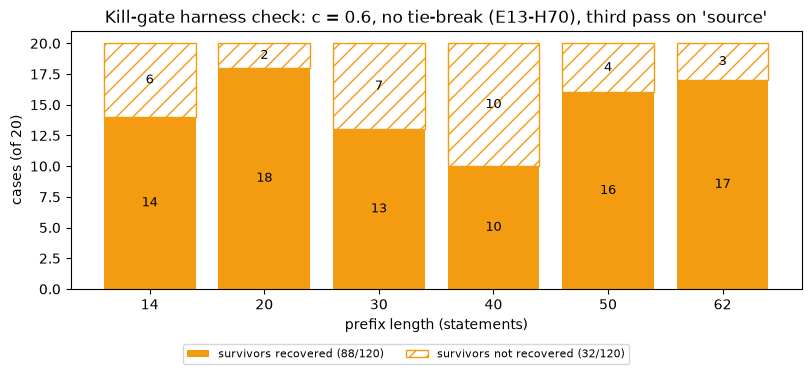

In [13]:
lengths = list(GATE_PER_N)
recovered = np.array([GATE_PER_N[n]["survivors_recovered"] for n in lengths])
missed = np.array([GATE_PER_N[n]["cases"] - GATE_PER_N[n]["survivors_recovered"] for n in lengths])
fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
x = np.arange(len(lengths))
ax.bar(x, recovered, color=COL_PLAIN, label=f"survivors recovered ({recovered.sum()}/{GATE['cases']})")
ax.bar(x, missed, bottom=recovered, color="white", edgecolor=COL_PLAIN, hatch="//", label=f"survivors not recovered ({missed.sum()}/{GATE['cases']})")
for position, (r, m) in enumerate(zip(recovered, missed)):
    ax.text(position, r / 2, str(r), ha="center", va="center", fontsize=9)
    if m:
        ax.text(position, r + m / 2, str(m), ha="center", va="center", fontsize=9)
ax.set_xticks(x, [str(n) for n in lengths])
ax.set_xlabel("prefix length (statements)")
ax.set_ylabel(f"cases (of {LONG_REPS})")
ax.set_title(f"Kill-gate harness check: {ARMS[H70_ARM].label}, third pass on '{LONG_DOC}'")
fig.legend(fontsize=8, loc="outside lower center", ncol=2)
plt.show()

## Harness sanity check - reproduce the recorded E13 readings

The copied builders are verified by their output: the recorded E13-H70 readings at `c = 0.6` (280/280 deletion
cases at or below `0.005`, AUC `0.999903`, 1847/1847 fully matched equal-length pairs equal to shipped `opw_gap`)
and the recorded E13-H71 readings at `c = 0.325` (macro-F1 `0.9674` on half A, `0.9772` on half B), all without the
tie-break. A reading that does not reproduce returns `Blocked`. Every scoring loop of this section computes all
arms in one pass; the section reads the two arms without a tie-break, and the clause sections read the others.

### E13-H70 sets

The 280 deletion cases, the reordered-and-deleted cases at rung 2 or above, and every fixture pair.

In [14]:
del_rows = []
for case in CASES:
    A = EMB[case["base"]]
    readings, matchings = score_case(A, A[case["keep"]])
    del_rows.append({"base": case["base"], "k": case["k"], "family": case["family"], "rep": case["rep"], **readings,
                     **{f"rec_{key}": survivors_recovered(rows, cols, case["keep"]) for key, (rows, cols) in matchings.items()}})
del_df = pl.DataFrame(del_rows)
print(f"{del_df.height} deletion cases scored | {del_df['base'].n_unique()} bases | k {sorted(del_df['k'].unique().to_list())}")

280 deletion cases scored | 10 bases | k [1, 2, 3, 4]


In [15]:
pos_rows = []
for item in progress(POSITIVE_POOL, "reordered-and-deleted cases, per unique permutation"):
    A = EMB[item["base"]]
    Y = A[item["perm"]]
    for plan in PLANS_K2[item["base"]]:
        readings, _ = score_case(A, Y[plan["keep"]])
        pos_rows.append({"base": item["base"], "rung": item["rung"], **readings})
pos_df = pl.DataFrame(pos_rows)

reordered-and-deleted cases, per unique permutation:   0%|          | 0/1430 [00:00<?, ?it/s]

reordered-and-deleted cases, per unique permutation:  44%|████▍     | 629/1430 [00:15<00:19, 41.91it/s]

reordered-and-deleted cases, per unique permutation:  44%|████▍     | 629/1430 [00:30<00:19, 41.91it/s]

reordered-and-deleted cases, per unique permutation:  87%|████████▋ | 1247/1430 [00:30<00:04, 41.47it/s]

reordered-and-deleted cases, per unique permutation: 100%|██████████| 1430/1430 [00:34<00:00, 41.40it/s]

In [16]:
pair_rows = []
for family, label_a, label_b, A, B in progress(fixture_pairs, "fixture pairs"):
    readings, _ = score_case(A, B)
    pair_rows.append({"family": family, "a": label_a, "b": label_b, "n_a": len(A), "n_b": len(B), **readings})
pair_df = pl.DataFrame(pair_rows)

fixture pairs:   0%|          | 0/1913 [00:00<?, ?it/s]

fixture pairs: 100%|██████████| 1913/1913 [00:06<00:00, 293.08it/s]

In [17]:
def auc(negatives: np.ndarray, positives: np.ndarray) -> float:
    """AUC of ``positives`` reading above ``negatives``; a tie counts one half (E13-H70, verbatim)."""
    labels = np.r_[np.zeros(len(negatives)), np.ones(len(positives))]
    return float(roc_auc_score(labels, np.r_[negatives, positives]))


def fully_matched(frame: pl.DataFrame, key: str) -> pl.DataFrame:
    """The fixture pairs of equal length in which the arm ``key`` matches every statement."""
    return frame.filter((pl.col("n_a") == pl.col("n_b")) & (pl.col(f"n_{key}") == pl.col("n_a")))


neg_df = del_df.filter(pl.col("k") == K_SEPARATION)
assert int(pos_df.select(pl.any_horizontal(pl.col(list(ARMS)).is_nan()).sum()).item()) == 0, "a case with no matched pair has no order gap"

ORDER = {}                     # per arm: the clause 2 and clause 3 readings
for key in ARMS:
    eligible = fully_matched(pair_df, key)
    ORDER[key] = {
        "deletion_within_bar": int((del_df[key] <= GAP_BAR).sum()),
        "deletion_share": float((del_df[key] <= GAP_BAR).mean()),
        "deletion_recovered": int(del_df[f"rec_{key}"].sum()),
        "deletion_max": float(del_df[key].max()),
        "deletion_median_k2": float(neg_df[key].median()),
        "auc": auc(neg_df[key].to_numpy(), pos_df[key].to_numpy()),
        "fully_matched_pairs": eligible.height,
        "fully_matched_exactly_equal": int((eligible[key].to_numpy() == eligible["shipped"].to_numpy()).sum()),
        "fully_matched_array_equal": bool(np.array_equal(eligible[key].to_numpy(), eligible["shipped"].to_numpy())),
    }
N_NEG, N_POS = neg_df.height, pos_df.height
N_FIXTURE_PAIRS = pair_df.height
N_EQUAL_LENGTH = pair_df.filter(pl.col("n_a") == pl.col("n_b")).height
SHIPPED_MEDIAN_K2 = float(neg_df["shipped"].median())
AUC_SHIPPED = auc(neg_df["shipped"].to_numpy(), pos_df["shipped"].to_numpy())
print(f"{ARMS[H70_ARM].label}: {ORDER[H70_ARM]['deletion_within_bar']}/{del_df.height} deletion cases <= {GAP_BAR} |"
      f" AUC {ORDER[H70_ARM]['auc']:.6f} ({N_NEG} against {N_POS}) |"
      f" {ORDER[H70_ARM]['fully_matched_exactly_equal']}/{ORDER[H70_ARM]['fully_matched_pairs']} fully matched equal-length pairs equal to shipped"
      f" ({N_FIXTURE_PAIRS} fixture pairs, {N_EQUAL_LENGTH} of equal length)")

c = 0.6, no tie-break (E13-H70): 280/280 deletion cases <= 0.005 | AUC 0.999903 (70 against 10010) | 1847/1847 fully matched equal-length pairs equal to shipped (1913 fixture pairs, 1847 of equal length)


### E13-H71 set

The 900 edited pairs. The alignment check, the donor rule, `build_edit` and the shipped details call are copied
from `notebooks/experiments/E13-H71-kj-partial-matching-map.ipynb` without a change to their logic or seeds. Two
names differ because they collide with E13-H70 names: `BODY_EMB` (in E13-H71 `EMB`) and `EDIT_PAIRS` (in E13-H71
`PAIRS`). The checkpoint mechanic differs in one point. A reading is restored in this order: this notebook's own
checkpoint, then the E13-H71 checkpoint when it has the same fixture key (a sha1 over the library version and the
text of every pair; that file is read only), and only a pair found in neither is computed. The cell after the loop
compares every reading this notebook computed itself with the E13-H71 checkpoint.

In [18]:
def word_set(text: str) -> set[str]:
    return set(re.findall(r"[a-z0-9]+", text.lower()))


def lexical_cost(a: list[str], b: list[str]) -> np.ndarray:
    """1 - Jaccard overlap of the word sets; independent of the encoder (E13-H71, verbatim)."""
    sets_a, sets_b = [word_set(s) for s in a], [word_set(s) for s in b]
    return np.array([[1 - len(x & y) / len(x | y) for y in sets_b] for x in sets_a])


def identity_is_optimal(cost: np.ndarray) -> bool:
    """True when the optimal one-to-one assignment pairs every statement with its own index (E13-H71, verbatim)."""
    if cost.shape[0] != cost.shape[1]:
        return False
    return bool(np.array_equal(linear_sum_assignment(cost)[1], np.arange(cost.shape[0])))


ALIGNMENT = {}
for b in BASES:
    ground = cost_matrix(BODY_EMB[b], BODY_EMB[f"{b}~bt"]).astype(np.float64)
    checks = {
        "equal_length": len(RAW_BASE[b]) == len(RAW_BT[b]),
        "title_consistent": RAW_BASE[b][0].startswith("# ") == RAW_BT[b][0].startswith("# "),
        "roundtrip": SEGMENTS[b] == BODY[b] and SEGMENTS[f"{b}~bt"] == BT_BODY[b],
        "ground_cost_identity": identity_is_optimal(ground),
        "lexical_identity": identity_is_optimal(lexical_cost(BODY[b], BT_BODY[b])),
    }
    ALIGNMENT[b] = {**checks, "aligned": all(checks.values())}

EXCLUDED = [b for b in BASES if not ALIGNMENT[b]["aligned"]]
HALF_BASES = {h: [b for b in members if ALIGNMENT[b]["aligned"]] for h, members in HALF.items()}
PAIR_COST = {b: cost_matrix(BODY_EMB[b], BODY_EMB[f"{b}~bt"]).astype(np.float64) for b in BASES}
print(f"paraphrase alignment (equal length, title consistent, exact re-segmentation, identity optimal under the ground cost and under a lexical cost):"
      f" {len(BASES) - len(EXCLUDED)} of {len(BASES)} base documents aligned | excluded: {', '.join(EXCLUDED) or 'none'}")

paraphrase alignment (equal length, title consistent, exact re-segmentation, identity optimal under the ground cost and under a lexical cost): 10 of 10 base documents aligned | excluded: none


In [19]:
def norm_text(text: str) -> str:
    return " ".join(text.casefold().split())


def donor_relation(base: str, donor: str) -> str:
    """How the donor document relates to the base: the ibm documents summarise one article in parallel (E13-H71, verbatim)."""
    if ARTICLE[base] != ARTICLE[donor]:
        return "other article"
    return "sibling summary" if ARTICLE[base] == "ibm" else "other section"


def donor_pool(base: str) -> list[tuple[str, int]]:
    """(document, statement index) of every statement of the other bases in the same half, minus exact duplicates (E13-H71, verbatim)."""
    present = {norm_text(s) for s in BODY[base]}
    return [(d, i) for d in HALF_BASES[HALF_OF[base]] if d != base
            for i, s in enumerate(BODY[d]) if norm_text(s) not in present]


def build_edit(base: str, kind: str, k: int, rep: int, paraphrase: bool) -> dict:
    """One labelled pair; the generator ignores the paraphrase arm, so both arms share positions and donors (E13-H71, verbatim)."""
    rng = np.random.default_rng([SEED, zlib.crc32(f"{base}|{kind}|{k}|{rep}".encode())])
    n = len(BODY[base])
    removed = sorted(rng.choice(n, size=k, replace=False).tolist()) if kind != "insertion" else []
    pool = DONOR_POOL[base]
    donors = [pool[p] for p in rng.choice(len(pool), size=k, replace=False)] if kind != "deletion" else []
    slots = removed if kind == "replacement" else sorted(rng.integers(0, n + 1, size=len(donors)).tolist())
    inserted_at: dict[int, list[tuple[str, int]]] = {}
    for slot, donor in zip(slots, donors):
        inserted_at.setdefault(slot, []).append(donor)

    kept_text = BT_BODY[base] if paraphrase else BODY[base]
    b_text, y_b, relation, counterpart, replaced_by = [], [], [], np.full(n, -1), np.full(n, -1)
    for i in range(n + 1):  # position n is the end of the document
        for doc, index in inserted_at.get(i, []):
            if kind == "replacement":
                replaced_by[i] = len(b_text)
            b_text.append(BODY[doc][index])
            y_b.append(ADDED)
            relation.append(donor_relation(base, doc))
        if i < n and i not in removed:
            counterpart[i] = len(b_text)
            b_text.append(kept_text[i])
            y_b.append(KEPT)
            relation.append("")
    y_a = np.full(n, KEPT)
    y_a[removed] = REMOVED
    return {"pid": f"{base}|{kind}|{k}|{rep}|{'bt' if paraphrase else 'id'}", "base": base, "kind": kind, "k": k,
            "paraphrase": paraphrase, "a_text": BODY[base], "b_text": b_text, "y_a": y_a, "y_b": np.array(y_b),
            "counterpart": counterpart, "replaced_by": replaced_by, "relation": relation}


DONOR_POOL = {b: donor_pool(b) for b in BASES}
EDITS = [build_edit(b, kind, k, rep, paraphrase) for b in BASES for kind in EDIT_KINDS for k in EDIT_KS
         for rep in range(REPS) for paraphrase in PARAPHRASE_ARMS]
# the checkpoint is keyed by the library version and the exact texts, so a changed fixture never reads it (E13-H71, verbatim)
fixture_key = hashlib.sha1(json.dumps([pipe._VERSION, [(e["pid"], e["a_text"], e["b_text"]) for e in EDITS]])
                           .encode()).hexdigest()[:12]
CHECKPOINT = CHECKPOINT_DIR / f"shipped-readings-{len(EDITS):05d}-{fixture_key}.json"
H71_CHECKPOINT = H71_CHECKPOINT_DIR / CHECKPOINT.name
FIXTURE_KEY_EQUALS_H71 = H71_CHECKPOINT.exists()
print(f"{len(EDITS)} edited pairs built | removed statements {sum(int((e['y_a'] == REMOVED).sum()) for e in EDITS)},"
      f" added statements {sum(int((e['y_b'] == ADDED).sum()) for e in EDITS)}\n"
      f"fixture key (sha1 over the library version and every pair text): {fixture_key} |"
      f" an E13-H71 checkpoint with the same key exists: {FIXTURE_KEY_EQUALS_H71}")

900 edited pairs built | removed statements 1200, added statements 1200
fixture key (sha1 over the library version and every pair text): 3e396129ed50 | an E13-H71 checkpoint with the same key exists: True


In [20]:
CAPTURED: list[tuple[list[str], np.ndarray]] = []


def recording_embed(doc, **kwargs):
    """The shipped embed_statements, with its return value also kept for the cost matrix (E13-H71, verbatim)."""
    out = DocDistance.embed_statements(DD, doc, **kwargs)
    CAPTURED.append(out)
    return out


class ParagraphSegmenter:
    """Stand-in for the SaT segmenter: one statement per paragraph, the unit the labels are defined on (E13-H71, verbatim)."""

    @staticmethod
    def split(text: str) -> list[str]:
        return text.split("\n\n")


def details_call(edit: dict) -> tuple:
    """The shipped details call, its two embedding arrays, and whether the statements are the constructed ones (E13-H71, verbatim)."""
    CAPTURED.clear()
    result, details = DD.semantic_distance_with_details(join(edit["a_text"]), join(edit["b_text"]))
    (seg_a, emb_a), (seg_b, emb_b) = CAPTURED
    return result, details, emb_a, emb_b, seg_a == edit["a_text"] and seg_b == edit["b_text"]


def shipped_reading(edit: dict) -> dict:
    """The shipped details call on one edited pair, reduced to what the two E13-H71 labellers read (E13-H71, verbatim)."""
    result, details, emb_a, emb_b, exact = details_call(edit)
    if not exact:  # SaT split a statement differently inside the edited text: repeat with the statement units pinned
        sat, DD._segmenter = DD._segmenter, ParagraphSegmenter
        result, details, emb_a, emb_b, pinned_exact = details_call(edit)
        DD._segmenter = sat
        assert pinned_exact, edit["pid"]
    return {
        "shipped_segmentation": exact,
        "smd": result.smd,
        "cost": cost_matrix(emb_a, emb_b).astype(np.float64).tolist(),
        "no_counterpart": [flow["no_counterpart"] for flow in details["flows"]],
        "heaviest_target": [flow["matches"][0]["target_index"] for flow in details["flows"]],
        "n_targets": [len(flow["matches"]) for flow in details["flows"]],
        "min_incoming_cost": [target["min_incoming_cost"] for target in details["targets"]],
    }


def save_checkpoint(path: Path, readings: dict) -> None:
    scratch = path.with_suffix(".tmp")
    scratch.write_text(json.dumps(readings))
    scratch.replace(path)


CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OWN_READINGS = json.loads(CHECKPOINT.read_text()) if CHECKPOINT.exists() else {}          # computed by this notebook
H71_READINGS = json.loads(H71_CHECKPOINT.read_text()) if FIXTURE_KEY_EQUALS_H71 else {}   # computed by E13-H71 on the same texts, read only
N_OWN_RESTORED = len(OWN_READINGS)
todo = [e for e in EDITS if e["pid"] not in OWN_READINGS and e["pid"] not in H71_READINGS]
DD.embed_statements = recording_embed
for done, edit in enumerate(progress(todo, "shipped details per edited pair"), start=1):
    OWN_READINGS[edit["pid"]] = shipped_reading(edit)
    if done % CHECKPOINT_EVERY == 0:
        save_checkpoint(CHECKPOINT, OWN_READINGS)
del DD.embed_statements  # removes the instance override; the class method is in force again
N_COMPUTED = len(todo)
if N_COMPUTED:
    save_checkpoint(CHECKPOINT, OWN_READINGS)
READINGS = H71_READINGS | OWN_READINGS       # a reading this notebook computed takes precedence

shipped details per edited pair: 0it [00:00, ?it/s]

shipped details per edited pair: 0it [00:00, ?it/s]

In [21]:
EDIT_PAIRS = [{**edit, "row": row, "cost": np.array(READINGS[edit["pid"]]["cost"])} for row, edit in enumerate(EDITS)]
assert all(p["cost"].shape == (p["y_a"].size, p["y_b"].size) for p in EDIT_PAIRS)
N_PINNED = sum(not READINGS[e["pid"]]["shipped_segmentation"] for e in EDITS)
OVERRIDE_REMOVED = "embed_statements" not in vars(DD) and type(DD._segmenter).__name__ == "Segmenter"

N_OWN = len(OWN_READINGS)                                               # pairs this notebook computed, in this or an earlier execution
N_FROM_H71 = sum(e["pid"] not in OWN_READINGS for e in EDITS)           # pairs read from the E13-H71 checkpoint
in_both = [pid for pid in OWN_READINGS if pid in H71_READINGS]
H71_COST_EQUAL = sum(np.array_equal(np.array(H71_READINGS[pid]["cost"]), OWN_READINGS[pid]["cost"]) for pid in in_both)
H71_READING_EQUAL = sum(H71_READINGS[pid] == OWN_READINGS[pid] for pid in in_both)
OWN_BASES = sorted({pid.split("|")[0] for pid in OWN_READINGS}, key=BASES.index)
print(f"shipped details of the {len(EDITS)} pairs: {N_OWN} computed by this notebook ({N_COMPUTED} in this execution, {N_OWN_RESTORED} restored from"
      f" {CHECKPOINT_DIR.name}/{CHECKPOINT.name}), {N_FROM_H71} read from the E13-H71 checkpoint of the same fixture key\n"
      f"pairs computed by this notebook against the E13-H71 checkpoint: cost matrices np.array_equal in {H71_COST_EQUAL}/{len(in_both)},"
      f" whole stored reading equal in {H71_READING_EQUAL}/{len(in_both)} | bases they cover: {', '.join(OWN_BASES) or 'none'}\n"
      f"pairs where SaT split a statement differently inside the edited text and the statement units were pinned: {N_PINNED} of {len(EDITS)}\n"
      f"instance overrides removed: {OVERRIDE_REMOVED}")

shipped details of the 900 pairs: 300 computed by this notebook (0 in this execution, 300 restored from E15-H79/shipped-readings-00900-3e396129ed50.json), 600 read from the E13-H71 checkpoint of the same fixture key
pairs computed by this notebook against the E13-H71 checkpoint: cost matrices np.array_equal in 300/300, whole stored reading equal in 300/300 | bases they cover: gold, gold-2, v1, v2
pairs where SaT split a statement differently inside the edited text and the statement units were pinned: 37 of 900
instance overrides removed: True


In [22]:
def partial_matching(cost: np.ndarray, arm: Arm) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """The E13-H71 labels from the matching of the arm: A labels, B labels and the matched B index per A statement (-1 = none)."""
    rows, cols = matched_pairs(cost, arm)
    target = np.full(cost.shape[0], -1)
    target[rows] = cols
    labels_b = np.full(cost.shape[1], ADDED)
    labels_b[cols] = KEPT
    return np.where(target >= 0, KEPT, REMOVED), labels_b, target


def add_counts(counts: np.ndarray, pair: dict, labels_a: np.ndarray, labels_b: np.ndarray) -> None:
    """Confusion counts, true class in rows and predicted class in columns, over both sides of the pair (E13-H71, verbatim)."""
    np.add.at(counts, (pair["y_a"], labels_a), 1)
    np.add.at(counts, (pair["y_b"], labels_b), 1)


def confusion(pairs: list[dict], labeller) -> np.ndarray:
    counts = np.zeros((3, 3), dtype=np.int64)
    for pair in pairs:
        add_counts(counts, pair, *labeller(pair)[:2])
    return counts


def scores(counts: np.ndarray) -> dict:
    """Per-class precision, recall and F1 plus the macro-F1; an empty denominator scores 0 (E13-H71, verbatim)."""
    tp = np.diag(counts).astype(float)
    predicted, actual = counts.sum(axis=0), counts.sum(axis=1)
    f1 = np.divide(2 * tp, predicted + actual, out=np.zeros(3), where=(predicted + actual) > 0)
    return {"precision": np.divide(tp, predicted, out=np.zeros(3), where=predicted > 0),
            "recall": np.divide(tp, actual, out=np.zeros(3), where=actual > 0),
            "f1": f1, "macro_f1": float(f1.mean())}


def pairs_of(bases: list[str]) -> list[dict]:
    return [p for p in EDIT_PAIRS if p["base"] in bases]


MAP_SETS = {"half_A": pairs_of(HALF_BASES["A"]), "half_B": pairs_of(HALF_BASES["B"]), "all": EDIT_PAIRS}
LABELS = {key: [partial_matching(p["cost"], arm) for p in EDIT_PAIRS] for key, arm in ARMS.items()}

MAP = {}                       # per arm: macro-F1 per set, label changes against the arm without a tie-break, no-edit control
for key, arm in ARMS.items():
    per_set = {name: scores(confusion(pairs, lambda p, key=key: LABELS[key][p["row"]])) for name, pairs in MAP_SETS.items()}
    changed = [int((a != pa).sum() + (b != pb).sum()) for (a, b, _), (pa, pb, _) in zip(LABELS[key], LABELS[PLAIN])]
    no_edit = {b: int((partial_matching(PAIR_COST[b], arm)[0] == REMOVED).sum()) for b in BASES}
    MAP[key] = {
        "macro_f1": {name: s["macro_f1"] for name, s in per_set.items()},
        "f1": {name: dict(zip(CLASS_NAMES, (float(v) for v in s["f1"]))) for name, s in per_set.items()},
        "n_pairs": {name: len(pairs) for name, pairs in MAP_SETS.items()},
        "pairs_with_a_changed_label": int(sum(c > 0 for c in changed)),
        "statements_with_a_changed_label": int(sum(changed)),
        "pairs_with_a_changed_target": int(sum(not np.array_equal(t, pt) for (_, _, t), (_, _, pt) in zip(LABELS[key], LABELS[PLAIN]))),
        "no_edit_read_as_removed": int(sum(no_edit.values())), "no_edit_per_base": no_edit,
    }
NO_EDIT_STATEMENTS = int(sum(PAIR_COST[b].shape[0] for b in BASES))
print(f"{ARMS[PLAIN].label}: macro-F1 half A {MAP[PLAIN]['macro_f1']['half_A']:.4f}, half B {MAP[PLAIN]['macro_f1']['half_B']:.4f},"
      f" all {MAP[PLAIN]['macro_f1']['all']:.4f} | {ARMS[H70_ARM].label}: all {MAP[H70_ARM]['macro_f1']['all']:.4f}")

c = 0.325, no tie-break: macro-F1 half A 0.9674, half B 0.9772, all 0.9723 | c = 0.6, no tie-break (E13-H70): all 0.7771


### Reproduction table

Every recorded reading beside the reading of this notebook. The five rows the hypothesis notes name decide the
check. The other rows are further recorded values of the two E13 metrics files and are shown as supporting
evidence that the builders are the same.

In [23]:
h70_saved = json.loads(H70_METRICS.read_text())
h71_saved = json.loads(H71_METRICS.read_text())

# (reading, recorded, here, decides the check)
REPRODUCTION = [
    (f"deletion cases <= {GAP_BAR}, c = {C_H70}", f"{RECORDED['deletion_within_bar']}/{RECORDED['deletion_cases']}",
     f"{ORDER[H70_ARM]['deletion_within_bar']}/{del_df.height}", True),
    (f"AUC deleted-only against reordered-and-deleted, c = {C_H70}", f"{RECORDED['auc']:.6f}", f"{ORDER[H70_ARM]['auc']:.6f}", True),
    (f"fully matched equal-length pairs equal to shipped opw_gap, c = {C_H70}", f"{RECORDED['identities']}/{RECORDED['identities']}",
     f"{ORDER[H70_ARM]['fully_matched_exactly_equal']}/{ORDER[H70_ARM]['fully_matched_pairs']}", True),
    (f"macro-F1 half A, c = {C_REGISTERED}", f"{RECORDED['macro_f1_half_A']:.4f}", f"{MAP[PLAIN]['macro_f1']['half_A']:.4f}", True),
    (f"macro-F1 half B, c = {C_REGISTERED}", f"{RECORDED['macro_f1_half_B']:.4f}", f"{MAP[PLAIN]['macro_f1']['half_B']:.4f}", True),
    ("shipped median at k=2 (E13-H70 metrics)", f"{h70_saved['sanity_check']['shipped_median_k2']:.6f}", f"{SHIPPED_MEDIAN_K2:.6f}", False),
    ("matched median at k=2, c = 0.6 (E13-H70 metrics)", f"{h70_saved['clause_1_deletions']['per_k']['2']['matched_median']:.5e}",
     f"{ORDER[H70_ARM]['deletion_median_k2']:.5e}", False),
    ("negatives / positives of the AUC (E13-H70 metrics)",
     f"{h70_saved['clause_2_separation']['n_negatives']} / {h70_saved['clause_2_separation']['n_positives']}", f"{N_NEG} / {N_POS}", False),
    ("shipped AUC (E13-H70 metrics)", f"{h70_saved['clause_2_separation']['shipped']['auc']:.6f}", f"{AUC_SHIPPED:.6f}", False),
    ("fixture pairs / of equal length (E13-H70 metrics)",
     f"{h70_saved['clause_3_bit_identity']['fixture_pairs']} / {h70_saved['clause_3_bit_identity']['equal_length_pairs']}",
     f"{N_FIXTURE_PAIRS} / {N_EQUAL_LENGTH}", False),
    ("edited pairs / pairs with pinned statement units (E13-H71 metrics)",
     f"{h71_saved['fixture']['n_pairs_built']} / {h71_saved['fixture']['n_segmentation_pinned']}", f"{len(EDITS)} / {N_PINNED}", False),
    ("macro-F1 all pairs, c = 0.325 (E13-H71 metrics)", f"{h71_saved['cutoff']['macro_f1_at_fixed_cutoffs']['0.325']['all']:.4f}",
     f"{MAP[PLAIN]['macro_f1']['all']:.4f}", False),
    ("macro-F1 all pairs, c = 0.6 (E13-H71 metrics)", f"{h71_saved['cutoff']['macro_f1_at_fixed_cutoffs']['0.600']['all']:.4f}",
     f"{MAP[H70_ARM]['macro_f1']['all']:.4f}", False),
    ("cost matrices computed by this notebook equal to the E13-H71 checkpoint", f"{len(in_both)}/{len(in_both)}", f"{H71_COST_EQUAL}/{len(in_both)}", False),
]
SANITY_PASSED = bool(all(recorded == here for _, recorded, here, decides in REPRODUCTION if decides) and not EXCLUDED)
SUPPORTING_MATCH = sum(recorded == here for _, recorded, here, decides in REPRODUCTION if not decides)
SUPPORTING_ROWS = sum(not decides for *_, decides in REPRODUCTION)

t = Table(title="Harness sanity check - recorded E13 readings against this notebook, without the tie-break", header_style="bold medium_purple")
for column in ("reading", "recorded", "here", "decides the check", "reproduced"):
    t.add_column(column, justify="left" if column == "reading" else "right")
for reading, recorded, here, decides in REPRODUCTION:
    t.add_row(reading, recorded, here, "yes" if decides else "no",
              "[dark_sea_green]yes[/dark_sea_green]" if recorded == here else "[indian_red]NO[/indian_red]", style="bold" if decides else None)
sanity_colour = "dark_sea_green" if SANITY_PASSED else "indian_red"
console.print(Group(t, Panel(
    f"[bold {sanity_colour}]{'SANITY CHECK PASSED' if SANITY_PASSED else 'SANITY CHECK FAILED - verdict Blocked'}[/bold {sanity_colour}]\n"
    f"the five named readings reproduce: {SANITY_PASSED} | supporting rows that reproduce: {SUPPORTING_MATCH}/{SUPPORTING_ROWS}\n"
    f"paraphrase alignment: {len(BASES) - len(EXCLUDED)} of {len(BASES)} bases aligned | edit-fixture key {fixture_key} equals the key of the E13-H71"
    f" checkpoint: {FIXTURE_KEY_EQUALS_H71}",
    border_style=sanity_colour, expand=False)))

                       Harness sanity check - recorded E13 readings against this notebook, without the tie-break                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ reading                                                                 ┃    recorded ┃        here ┃ decides the check ┃ reproduced ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ deletion cases <= 0.005, c = 0.6                                        │     280/280 │     280/280 │               yes │        yes │
│ AUC deleted-only against reordered-and-deleted, c = 0.6                 │    0.999903 │    0.999903 │               yes │        yes │
│ fully matched equal-length pairs equal to shipped opw_gap, c = 0.6      │   1847/1847 │   1847/1847 │               yes │        yes │
│ macro-F1 half A, c = 0.325                                              │      0.9674 │      0.9674 │               yes │        yes │
│ macro-F1 half B, c = 0.325                                              │      0.9772 │      0.9772 │               yes │        yes │
│ shipped median at k=2 (E13-H70 metrics)                                 │    0.134041 │    0.134041 │                no │        yes │
│ matched median at k=2, c = 0.6 (E13-H70 metrics)                        │ 9.67076e-05 │ 9.67076e-05 │                no │        yes │
│ negatives / positives of the AUC (E13-H70 metrics)                      │  70 / 10010 │  70 / 10010 │                no │        yes │
│ shipped AUC (E13-H70 metrics)                                           │    0.950980 │    0.950980 │                no │        yes │
│ fixture pairs / of equal length (E13-H70 metrics)                       │ 1913 / 1847 │ 1913 / 1847 │                no │        yes │
│ edited pairs / pairs with pinned statement units (E13-H71 metrics)      │    900 / 37 │    900 / 37 │                no │        yes │
│ macro-F1 all pairs, c = 0.325 (E13-H71 metrics)                         │      0.9723 │      0.9723 │                no │        yes │
│ macro-F1 all pairs, c = 0.6 (E13-H71 metrics)                           │      0.7771 │      0.7771 │                no │        yes │
│ cost matrices computed by this notebook equal to the E13-H71 checkpoint │     300/300 │     300/300 │                no │        yes │
└─────────────────────────────────────────────────────────────────────────┴─────────────┴─────────────┴───────────────────┴────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ SANITY CHECK PASSED                                                                                                         │
│ the five named readings reproduce: True | supporting rows that reproduce: 9/9                                               │
│ paraphrase alignment: 10 of 10 bases aligned | edit-fixture key 3e396129ed50 equals the key of the E13-H71 checkpoint: True │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Clause 1 - pure deletions on the document with repeated statements

The registered arm (`c = 0.325`, `ε = 1e-6`, positions from 0) on the 120 third-pass cases of the document that
holds the 9 repeated statements. The bar has two conditions: the matched order gap is at or below the shipped
order gap in 120 of 120 cases, and the matched sub-sequence of the longer document is textually equal to the
shorter document in at least 114 of 120. The table reads every arm on the same cases, so the registered arm
stands beside the arm without a tie-break.

In [24]:
THIRD = {key: third_pass_summary(kept_df, key) for key in ARMS}
C1_AT_OR_BELOW, C1_TEXT_EQUAL = THIRD[REG]["at_or_below_shipped"], THIRD[REG]["text_equal"]
C1_CASES = THIRD[REG]["cases"]
CLAUSE1_MET = bool(C1_AT_OR_BELOW == C1_CASES and C1_TEXT_EQUAL >= TEXT_EQUAL_MIN)

t = Table(title=f"Clause 1 - k={LONG_K} interior deletions on prefixes of '{LONG_DOC}', {DOC_KEPT}, {C1_CASES} cases", header_style="bold medium_purple")
t.add_column("arm")
for column in ("survivors recovered", "textually equal", "matched <= shipped", f"matched > {GAP_BAR}", "matched = identity gap",
               "matching = no tie-break", "matched median", "matched max"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    row = THIRD[key]
    t.add_row(arm.label, f"{row['survivors_recovered']}/{row['cases']}", f"{row['text_equal']}/{row['cases']}",
              f"{row['at_or_below_shipped']}/{row['cases']}", f"{row['above_gap_bar']}/{row['cases']}", f"{row['equal_to_floor_copy']}/{row['cases']}",
              f"{row['same_matching_as_no_tie_break']}/{row['cases']}", f"{row['matched_median']:.3e}", f"{row['matched_max']:.3e}",
              style="bold" if key == REG else None)
c1_colour = "dark_sea_green" if CLAUSE1_MET else "indian_red"
console.print(Group(t, Panel(
    f"[bold {c1_colour}]clause 1 {'MET' if CLAUSE1_MET else 'NOT MET'}[/bold {c1_colour}] under {ARMS[REG].label}\n"
    f"matched gap at or below the shipped gap: {C1_AT_OR_BELOW}/{C1_CASES} (bar {C1_CASES}/{C1_CASES})\n"
    f"matched sub-sequence textually equal to the shorter document: {C1_TEXT_EQUAL}/{C1_CASES} (bar >= {TEXT_EQUAL_MIN}/{C1_CASES})\n"
    f"without the tie-break at the same cutoff: at or below {THIRD[PLAIN]['at_or_below_shipped']}/{C1_CASES}, textually equal {THIRD[PLAIN]['text_equal']}/{C1_CASES}\n"
    f"shipped order gap on the same cases: median {THIRD[REG]['shipped_median']:.5f}",
    border_style=c1_colour, expand=False)))

                            Clause 1 - k=2 interior deletions on prefixes of 'source', repeated statements kept, 120 cases                            
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃                ┃      survivors ┃      textually ┃     matched <= ┃      matched > ┃      matched = ┃  matching = no ┃       matched ┃             ┃
┃ arm            ┃      recovered ┃          equal ┃        shipped ┃          0.005 ┃   identity gap ┃      tie-break ┃        median ┃ matched max ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ c = 0.6, no    │         88/120 │         88/120 │         99/120 │         23/120 │         88/120 │        120/120 │     3.211e-03 │   3.246e-01 │
│ tie-break      │                │                │                │                │                │                │               │             │
│ (E13-H70)      │                │                │                │                │                │                │               │             │
│ c = 0.325, no  │         88/120 │         88/120 │         99/120 │         23/120 │         88/120 │        120/120 │     3.211e-03 │   3.246e-01 │
│ tie-break      │                │                │                │                │                │                │               │             │
│ c = 0.325, eps │        110/120 │        111/120 │        120/120 │          0/120 │        111/120 │         85/120 │     2.888e-03 │   4.876e-03 │
│ = 1e-06        │                │                │                │                │                │                │               │             │
│ (registered)   │                │                │                │                │                │                │               │             │
│ c = 0.325, eps │        110/120 │        111/120 │        120/120 │          0/120 │        111/120 │         85/120 │     2.888e-03 │   4.876e-03 │
│ = 0.0001 (no   │                │                │                │                │                │                │               │             │
│ bar)           │                │                │                │                │                │                │               │             │
│ c = 0.325, eps │        110/120 │        111/120 │        120/120 │          0/120 │        111/120 │         85/120 │     2.888e-03 │   4.876e-03 │
│ = 1e-08 (no    │                │                │                │                │                │                │               │             │
│ bar)           │                │                │                │                │                │                │               │             │
│ c = 0.325, eps │        110/120 │        111/120 │        120/120 │          0/120 │        111/120 │         85/120 │     2.888e-03 │   4.876e-03 │
│ = 1e-06,       │                │                │                │                │                │                │               │             │
│ positions from │                │                │                │                │                │                │               │             │
│ 1 (no bar)     │                │                │                │                │                │                │               │             │
└────────────────┴────────────────┴────────────────┴────────────────┴────────────────┴────────────────┴────────────────┴───────────────┴─────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 1 NOT MET under c = 0.325, eps = 1e-06 (registered)                             │
│ matched gap at or below the shipped gap: 120/120 (bar 120/120)                         │
│ matched sub-sequence textually equal to the shorter document: 111/120 (bar >= 114/120) │
│ without th

The cases in which the registered arm does not return a textually equal sub-sequence, one row each, then the
mechanism readings over all 120 cases. `position sum` is the total `Σ |i/n - j/m|` over the pairs of a matching,
computed in exact rational arithmetic: once for the matching the solver returned and once for the survivor
matching, which pairs every surviving statement with its own copy. The solver minimises this sum among the
matchings of equal ground cost. A returned sum below the survivor sum means the position term itself ranks another
matching first; two equal sums mean the position term has a tie of its own. For those the table also gives the
difference of the two sums as the solver receives them, in float64. The mechanism table reads the sentence of the record literally: whether the tie group is matched in
document order, and whether the whole matching is.

In [25]:
miss_df = kept_df.filter(~pl.col(f"txt_{REG}")).sort(["n", "rep"])
C1_MISSES = miss_df.height
C1_MISS_RETURNED_BELOW = miss_df.filter(pl.col("position_compare") == "returned < survivors").height
C1_MISS_POSITION_TIE = miss_df.filter(pl.col("position_compare") == "equal").height
tie_miss_df = miss_df.filter(pl.col("position_compare") == "equal")
C1_TIE_FLOAT_BELOW = int((tie_miss_df["position_float_diff"] < 0).sum())      # float64 input ranks the returned matching first
C1_TIE_FLOAT_EQUAL = int((tie_miss_df["position_float_diff"] == 0).sum())
C1_MISS_DROPPED_REPEATED = int((miss_df["dropped_repeated"] > 0).sum())
C1_MISS_ABOVE_SHIPPED = int((miss_df[REG] > miss_df["shipped"]).sum())
C1_MISS_ABOVE_BAR = int((miss_df[REG] > GAP_BAR).sum())
C1_MISS_MATCHED_MAX = float(miss_df[REG].max()) if C1_MISSES else float("nan")
C1_DROPPED_REPEATED_EQUAL = int(((kept_df["dropped_repeated"] > 0) & kept_df[f"txt_{REG}"]).sum())
C1_POSITION_COMPARE = dict(sorted(Counter(kept_df["position_compare"].to_list()).items()))
C1_GROUND_COST_EQUAL = int(kept_df["ground_cost_equal"].sum())
MECHANISM = {key: {"tie_group_in_document_order": int(kept_df[f"group_order_{key}"].sum()),
                   "whole_matching_in_document_order": int(kept_df[f"order_{key}"].sum()),
                   "matching_equal_to_registered_arm": int(kept_df[f"asreg_{key}"].sum())} for key in ARMS}

tables = []
if C1_MISSES:
    t = Table(title=f"Clause 1 - the {C1_MISSES} cases without a textually equal sub-sequence under {ARMS[REG].label}", header_style="bold medium_purple")
    for column in ("prefix length", "draw", "deleted positions", "repeated statements deleted", "A positions left unmatched",
                   "position sum, returned", "position sum, survivors", "exact comparison", "float64 returned - survivors", "matched gap",
                   "shipped gap", "identity gap of B"):
        t.add_column(column, justify="right")
    for row in miss_df.iter_rows(named=True):
        t.add_row(str(row["n"]), str(row["rep"]), str(row["drop"]), str(row["dropped_repeated"]), str(row[f"unmatched_{REG}"]),
                  f"{row['position_returned']:.6f}", f"{row['position_survivors']:.6f}", row["position_compare"],
                  f"{row['position_float_diff']:+.1e}", f"{row[REG]:.5f}", f"{row['shipped']:.5f}", f"{row['floor_copy']:.3e}")
    tables.append(t)
t = Table(title=f"Clause 1 - mechanism readings over the {C1_CASES} cases, per arm", header_style="bold medium_purple")
t.add_column("arm")
for column in ("tie group matched in document order", "whole matching in document order", "textually equal", "matching = registered arm"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    t.add_row(arm.label, f"{MECHANISM[key]['tie_group_in_document_order']}/{C1_CASES}", f"{MECHANISM[key]['whole_matching_in_document_order']}/{C1_CASES}",
              f"{THIRD[key]['text_equal']}/{C1_CASES}", f"{MECHANISM[key]['matching_equal_to_registered_arm']}/{C1_CASES}", style="bold" if key == REG else None)
tables.append(t)
console.print(Group(*tables,
    f"[bold]cases without a textually equal sub-sequence under the registered arm: {C1_MISSES}/{C1_CASES}[/bold]\n"
    f"  a repeated statement was deleted in {C1_MISS_DROPPED_REPEATED}/{C1_MISSES}\n"
    f"  the returned matching has a smaller position sum than the survivor matching in {C1_MISS_RETURNED_BELOW}/{C1_MISSES};"
    f" the two position sums are exactly equal in {C1_MISS_POSITION_TIE}/{C1_MISSES}\n"
    f"  of those {C1_MISS_POSITION_TIE} exact ties, the float64 sum of the returned matching is below the survivor sum in {C1_TIE_FLOAT_BELOW}"
    f" and equal to it in {C1_TIE_FLOAT_EQUAL}\n"
    f"  the matched gap is above the shipped gap in {C1_MISS_ABOVE_SHIPPED}/{C1_MISSES} and above {GAP_BAR} in {C1_MISS_ABOVE_BAR}/{C1_MISSES};"
    f" largest matched gap among them {C1_MISS_MATCHED_MAX:.6f}\n"
    f"cases with a deleted repeated statement and a textually equal sub-sequence: {C1_DROPPED_REPEATED_EQUAL}/{GATE_DROPPED_REPEATED}\n"
    f"exact comparison of the position sums over all {C1_CASES} cases: " + ", ".join(f"{name} in {count}" for name, count in C1_POSITION_COMPARE.items()) + "\n"
    f"cases in which the returned matching and the survivor matching have the same total capped ground cost: {C1_GROUND_COST_EQUAL}/{C1_CASES}"))

                       Clause 1 - the 9 cases without a textually equal sub-sequence under c = 0.325, eps = 1e-06 (registered)                        
┏━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃            ┃      ┃            ┃            ┃          A ┃            ┃            ┃            ┃            ┃            ┃           ┃            ┃
┃            ┃      ┃            ┃   repeated ┃  positions ┃   position ┃   position ┃            ┃    float64 ┃            ┃           ┃            ┃
┃     prefix ┃      ┃    deleted ┃ statements ┃       left ┃       sum, ┃       sum, ┃      exact ┃ returned - ┃    matched ┃   shipped ┃   identity ┃
┃     length ┃ draw ┃  positions ┃    deleted ┃  unmatched ┃   returned ┃  survivors ┃ comparison ┃  survivors ┃        gap ┃       gap ┃   gap of B ┃
┡━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│         14 │    2 │    [8, 11] │          1 │    [6, 11] │   0.428571 │   0.428571 │      equal │   -5.6e-17 │    0.00042 │   0.04586 │  6.047e-05 │
│         14 │    7 │     [2, 4] │          1 │     [2, 6] │   0.547619 │   0.595238 │ returned < │   -4.8e-02 │    0.00049 │   0.03902 │  1.095e-04 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
│         14 │   16 │     [1, 4] │          1 │     [1, 6] │   0.595238 │   0.642857 │ returned < │   -4.8e-02 │    0.00047 │   0.03731 │  9.817e-05 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
│         14 │   19 │    [8, 12] │          1 │    [6, 12] │   0.452381 │   0.452381 │      equal │   -5.6e-17 │    0.00041 │   0.05480 │  4.852e-05 │
│         30 │    5 │     [4, 5] │          1 │     [5, 8] │   0.642857 │   0.728571 │ returned < │   -8.6e-02 │    0.00235 │   0.06179 │  2.231e-03 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
│         30 │    7 │     [1, 6] │          1 │     [1, 8] │   0.728571 │   0.766667 │ returned < │   -3.8e-02 │    0.00266 │   0.06039 │  2.624e-03 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
│         30 │   17 │     [4, 6] │          2 │     [4, 8] │   0.657143 │   0.695238 │ returned < │   -3.8e-02 │    0.00288 │   0.05868 │  2.926e-03 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
│         40 │    9 │   [23, 32] │          1 │   [21, 32] │   0.443421 │   0.448684 │ returned < │   -5.3e-03 │    0.00347 │   0.03787 │  3.659e-03 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
│         40 │   14 │   [23, 25] │          1 │   [21, 25] │   0.471053 │   0.476316 │ returned < │   -5.3e-03 │    0.00354 │   0.04696 │  3.765e-03 │
│            │      │            │            │            │            │            │  survivors │            │            │           │            │
└────────────┴──────┴────────────┴────────────┴────────────┴────────────┴────────────┴────────────┴────────────┴────────────┴───────────┴────────────┘
                                              Clause 1 - mechanism readings over the 120 cases, per arm                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                                 ┃    tie group matched in document ┃    

The two panels place every case by its shipped order gap (x) and its matched order gap (y), without the tie-break
and with it, at the registered cutoff. A filled marker is a textually equal sub-sequence, a hollow marker is not.
The reading to check is the number of markers above the dashed identity line, which is the count of cases that
read above the shipped gap.

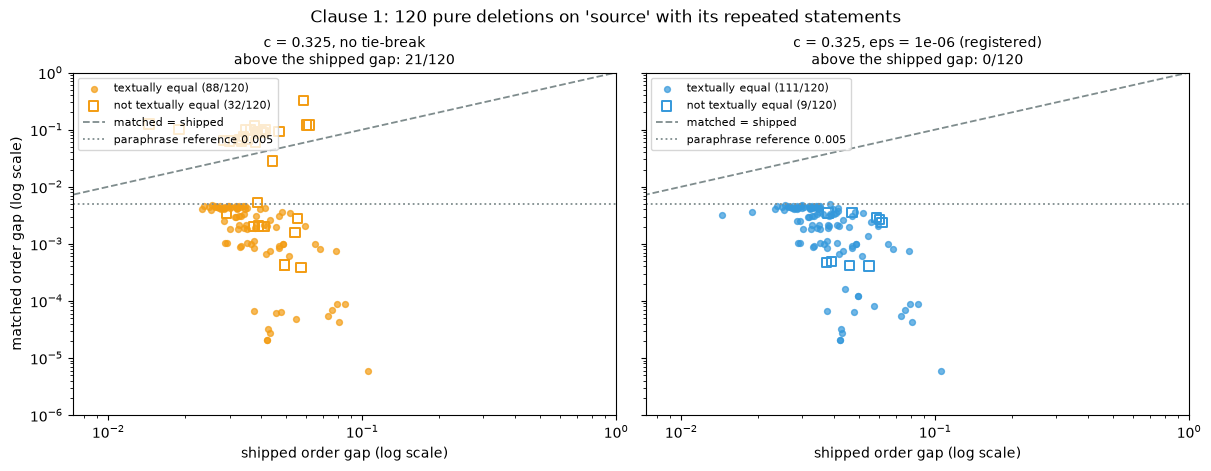

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True, sharex=True, sharey=True)
shipped = kept_df["shipped"].to_numpy()
span = [PLOT_FLOOR, 1.0]
for ax, key in zip(axes, (PLAIN, REG)):
    matched = np.maximum(kept_df[key].to_numpy(), PLOT_FLOOR)
    equal = kept_df[f"txt_{key}"].to_numpy()
    ax.scatter(shipped[equal], matched[equal], s=18, alpha=0.7, color=ARM_COLOUR[key], marker="o",
               label=f"textually equal ({int(equal.sum())}/{len(equal)})")
    ax.scatter(shipped[~equal], matched[~equal], s=46, facecolors="none", edgecolors=ARM_COLOUR[key], marker="s", lw=1.4,
               label=f"not textually equal ({int((~equal).sum())}/{len(equal)})")
    ax.plot(span, span, color=COL_REFERENCE, ls="--", lw=1.3, label="matched = shipped")
    ax.axhline(GAP_BAR, color=COL_REFERENCE, ls=":", lw=1.3, label=f"paraphrase reference {GAP_BAR}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(float(shipped.min()) / 2, 1.0)
    ax.set_ylim(PLOT_FLOOR, 1.0)
    ax.set_xlabel("shipped order gap (log scale)")
    ax.set_title(f"{ARMS[key].label}\nabove the shipped gap: {THIRD[key]['above_shipped']}/{THIRD[key]['cases']}", fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("matched order gap (log scale)")
fig.suptitle(f"Clause 1: {C1_CASES} pure deletions on '{LONG_DOC}' with its repeated statements")
plt.show()

## Clause 2 - registered deletion cases and separation

The registered arm on the two E13-H70 sets: the 280 order-preserving deletion cases, of which at least 95% must
read `≤ 0.005`, and the 70 deleted-only cases at `k = 2` against the 10010 reordered-and-deleted cases, which must
separate at AUC `≥ 0.95`. The base documents hold no repeated statement, so the prediction is that these readings
do not move: the cell compares them case by case with the reproduced E13-H70 readings.

In [27]:
C2 = ORDER[REG]
CLAUSE2_MET = bool(C2["deletion_share"] >= DELETION_SHARE_BAR and C2["auc"] >= AUC_BAR)
DEL_EQUAL_TO_H70 = bool(np.array_equal(del_df[REG].to_numpy(), del_df[H70_ARM].to_numpy()))
DEL_EQUAL_COUNT = int((del_df[REG].to_numpy() == del_df[H70_ARM].to_numpy()).sum())
POS_EQUAL_TO_H70 = bool(np.array_equal(pos_df[REG].to_numpy(), pos_df[H70_ARM].to_numpy()))
POS_EQUAL_COUNT = int((pos_df[REG].to_numpy() == pos_df[H70_ARM].to_numpy()).sum())

t = Table(title="Clause 2 - the E13-H70 deletion and separation readings per arm", header_style="bold medium_purple")
t.add_column("arm")
for column in (f"deletion cases <= {GAP_BAR}", "survivors recovered", "largest deletion reading", "median at k=2", "AUC",
               "deletion matchings = no tie-break", "positive matchings = no tie-break"):
    t.add_column(column, justify="right")
t.add_row("shipped opw_gap", f"{int((del_df['shipped'] <= GAP_BAR).sum())}/{del_df.height}", "-", f"{float(del_df['shipped'].max()):.3e}",
          f"{SHIPPED_MEDIAN_K2:.3e}", f"{AUC_SHIPPED:.6f}", "-", "-")
for key, arm in ARMS.items():
    row = ORDER[key]
    t.add_row(arm.label, f"{row['deletion_within_bar']}/{del_df.height}", f"{row['deletion_recovered']}/{del_df.height}", f"{row['deletion_max']:.3e}",
              f"{row['deletion_median_k2']:.3e}", f"{row['auc']:.6f}", f"{int(del_df[f'same_{key}'].sum())}/{del_df.height}",
              f"{int(pos_df[f'same_{key}'].sum())}/{pos_df.height}", style="bold" if key == REG else None)
c2_colour = "dark_sea_green" if CLAUSE2_MET else "indian_red"
console.print(Group(t, Panel(
    f"[bold {c2_colour}]clause 2 {'MET' if CLAUSE2_MET else 'NOT MET'}[/bold {c2_colour}] under {ARMS[REG].label}\n"
    f"deletion cases at or below {GAP_BAR}: {C2['deletion_within_bar']}/{del_df.height} = {C2['deletion_share']:.4f} (bar >= {DELETION_SHARE_BAR})\n"
    f"AUC, {N_NEG} deleted-only (k={K_SEPARATION}) against {N_POS} reordered-and-deleted: {C2['auc']:.6f} (bar >= {AUC_BAR}); shipped baseline {AUC_SHIPPED:.6f}\n"
    f"against the reproduced E13-H70 readings (c = {C_H70}, no tie-break): the {del_df.height} deletion readings np.array_equal {DEL_EQUAL_TO_H70}"
    f" ({DEL_EQUAL_COUNT}/{del_df.height} equal); the {pos_df.height} positive readings np.array_equal {POS_EQUAL_TO_H70} ({POS_EQUAL_COUNT}/{pos_df.height} equal)",
    border_style=c2_colour, expand=False)))

                                           Clause 2 - the E13-H70 deletion and separation readings per arm                                            
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃                   ┃                   ┃                   ┃                    ┃               ┃          ┃          deletion ┃                    ┃
┃                   ┃ deletion cases <= ┃         survivors ┃   largest deletion ┃               ┃          ┃    matchings = no ┃ positive matchings ┃
┃ arm               ┃             0.005 ┃         recovered ┃            reading ┃ median at k=2 ┃      AUC ┃         tie-break ┃     = no tie-break ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ shipped opw_gap   │             0/280 │                 - │          2.810e-01 │     1.340e-01 │ 0.950980 │                 - │                  - │
│ c = 0.6, no       │           280/280 │           280/280 │          6.101e-04 │     9.671e-05 │ 0.999903 │           280/280 │        10010/10010 │
│ tie-break         │                   │                   │                    │               │          │                   │                    │
│ (E13-H70)         │                   │                   │                    │               │          │                   │                    │
│ c = 0.325, no     │           280/280 │           280/280 │          6.101e-04 │     9.671e-05 │ 0.999903 │           280/280 │        10010/10010 │
│ tie-break         │                   │                   │                    │               │          │                   │                    │
│ c = 0.325, eps =  │           280/280 │           280/280 │          6.101e-04 │     9.671e-05 │ 0.999903 │           280/280 │        10010/10010 │
│ 1e-06             │                   │                   │                    │               │          │                   │                    │
│ (registered)      │                   │                   │                    │               │          │                   │                    │
│ c = 0.325, eps =  │           280/280 │           280/280 │          6.101e-04 │     9.671e-05 │ 0.999903 │           280/280 │        10010/10010 │
│ 0.0001 (no bar)   │                   │                   │                    │               │          │                   │                    │
│ c = 0.325, eps =  │           280/280 │           280/280 │          6.101e-04 │     9.671e-05 │ 0.999903 │           280/280 │        10010/10010 │
│ 1e-08 (no bar)    │                   │                   │                    │               │          │                   │                    │
│ c = 0.325, eps =  │           280/280 │           280/280 │          6.101e-04 │     9.671e-05 │ 0.999903 │           280/280 │        10010/10010 │
│ 1e-06, positions  │                   │                   │                    │               │          │                   │                    │
│ from 1 (no bar)   │                   │                   │                    │               │          │                   │                    │
└───────────────────┴───────────────────┴───────────────────┴────────────────────┴───────────────┴──────────┴───────────────────┴────────────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 2 MET under c = 0.325, eps = 1e-06 (registered)                                                                                             │
│ deletion cases at or below 0.005: 280/280 = 1.0000 (bar >= 0.95)                                                                                   │
│ AUC, 70 deleted-only (k=2) against 10010 reordered-and-deleted: 0.999903

The two panels show the two classes under the shipped order gap and under the registered arm. Filled bars are the
deleted-only cases, hatched outlines the reordered-and-deleted cases. The reading to check is the overlap of the
two classes in each panel.

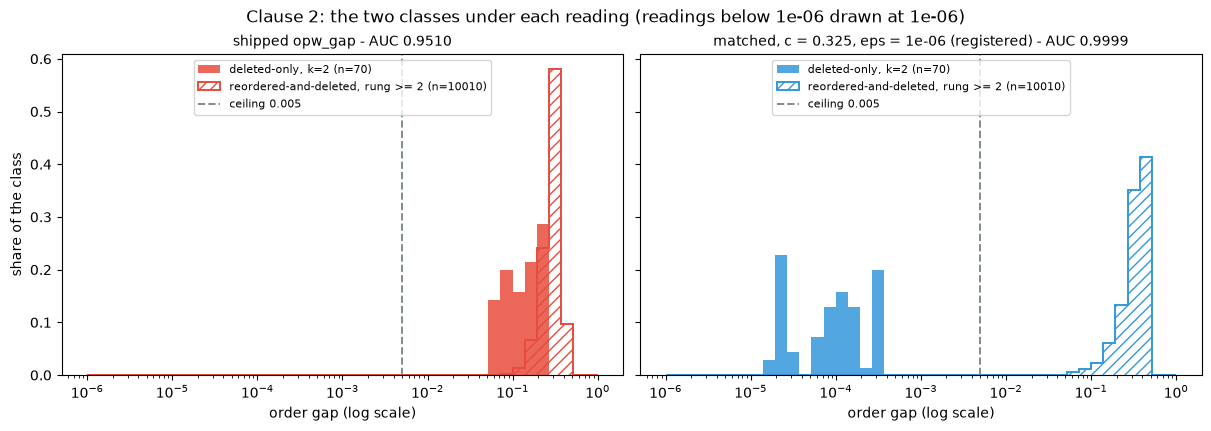

In [28]:
bins = np.logspace(-6, 0, 43)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, sharey=True)
for ax, method, colour, title in (
    (axes[0], "shipped", COL_SHIPPED, f"shipped opw_gap - AUC {AUC_SHIPPED:.4f}"),
    (axes[1], REG, COL_TIE, f"matched, {ARMS[REG].label} - AUC {C2['auc']:.4f}"),
):
    neg = np.maximum(neg_df[method].to_numpy(), bins[0])
    pos = np.maximum(pos_df[method].to_numpy(), bins[0])
    ax.hist(neg, bins=bins, weights=np.full(len(neg), 1 / len(neg)), color=colour, alpha=0.85, label=f"deleted-only, k={K_SEPARATION} (n={len(neg)})")
    ax.hist(pos, bins=bins, weights=np.full(len(pos), 1 / len(pos)), histtype="step", hatch="///", color=colour, lw=1.4,
            label=f"reordered-and-deleted, rung >= {RUNG_MIN} (n={len(pos)})")
    ax.axvline(GAP_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"ceiling {GAP_BAR}")
    ax.set_xscale("log")
    ax.set_xlabel("order gap (log scale)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="upper center")
axes[0].set_ylabel("share of the class")
fig.suptitle("Clause 2: the two classes under each reading (readings below 1e-06 drawn at 1e-06)")
plt.show()

## Clause 3 - bit-identity on fully matched equal-length pairs

On every fixture pair of equal length that the registered arm matches completely, the matched gap must equal
shipped `opw_gap` under `np.array_equal`. The count of such pairs is a constant a build needs and is persisted.
The prediction adds that the count at `c = 0.325` falls below the E13-H70 count 1847 by fewer than 20; the second
table lists the pairs that are fully matched at `c = 0.6` and not at `c = 0.325`.

In [29]:
eligible_reg = fully_matched(pair_df, REG)
C3 = ORDER[REG]
CLAUSE3_MET = bool(C3["fully_matched_array_equal"] and C3["fully_matched_pairs"] > 0)
C3_MAX_ABS_DIFF = float(np.abs(eligible_reg[REG].to_numpy() - eligible_reg["shipped"].to_numpy()).max())
COUNT_DROP = RECORDED["identities"] - C3["fully_matched_pairs"]
dropped_df = fully_matched(pair_df, H70_ARM).filter(pl.col(f"n_{REG}") < pl.col("n_a")).sort(["family", "a", "b"])
SAME_FIXTURE_MATCHINGS = int(pair_df[f"same_{REG}"].sum())

by_family = (
    pair_df.group_by("family")
    .agg(pl.len().alias("pairs"), (pl.col("n_a") == pl.col("n_b")).sum().alias("equal_length"),
         ((pl.col("n_a") == pl.col("n_b")) & (pl.col(f"n_{H70_ARM}") == pl.col("n_a"))).sum().alias("full_h70"),
         ((pl.col("n_a") == pl.col("n_b")) & (pl.col(f"n_{PLAIN}") == pl.col("n_a"))).sum().alias("full_plain"),
         ((pl.col("n_a") == pl.col("n_b")) & (pl.col(f"n_{REG}") == pl.col("n_a"))).sum().alias("full_reg"),
         ((pl.col("n_a") == pl.col("n_b")) & (pl.col(f"n_{REG}") == pl.col("n_a")) & (pl.col(REG) == pl.col("shipped"))).sum().alias("identical"))
    .sort("family")
)
t = Table(title="Clause 3 - fully matched equal-length fixture pairs, by family", header_style="bold medium_purple")
for column in ("family", "pairs", "equal length", f"fully matched, c = {C_H70}", f"fully matched, c = {C_REGISTERED}",
               f"fully matched, c = {C_REGISTERED} with eps = {EPS_REGISTERED:g}", "equal to shipped opw_gap"):
    t.add_column(column, justify="left" if column == "family" else "right")
for row in by_family.iter_rows(named=True):
    t.add_row(row["family"], str(row["pairs"]), str(row["equal_length"]), str(row["full_h70"]), str(row["full_plain"]), str(row["full_reg"]),
              f"{row['identical']}/{row['full_reg']}")
t.add_row("all", str(N_FIXTURE_PAIRS), str(N_EQUAL_LENGTH), str(ORDER[H70_ARM]["fully_matched_pairs"]), str(ORDER[PLAIN]["fully_matched_pairs"]),
          str(C3["fully_matched_pairs"]), f"{C3['fully_matched_exactly_equal']}/{C3['fully_matched_pairs']}", style="bold")

t2 = Table(title=f"Pairs fully matched at c = {C_H70} and not at c = {C_REGISTERED} ({dropped_df.height})", header_style="bold medium_purple")
for column in ("family", "a", "b", "statements", f"matched at c = {C_REGISTERED}", "shipped gap", "matched gap"):
    t2.add_column(column, justify="left" if column in ("family", "a", "b") else "right")
for row in dropped_df.iter_rows(named=True):
    t2.add_row(row["family"], row["a"], row["b"], str(row["n_a"]), str(row[f"n_{REG}"]), f"{row['shipped']:.6f}", f"{row[REG]:.6f}")
c3_colour = "dark_sea_green" if CLAUSE3_MET else "indian_red"
console.print(Group(t, t2, Panel(
    f"[bold {c3_colour}]clause 3 {'MET' if CLAUSE3_MET else 'NOT MET'}[/bold {c3_colour}] under {ARMS[REG].label}\n"
    f"np.array_equal = {C3['fully_matched_array_equal']} on {C3['fully_matched_pairs']} fully matched equal-length pairs"
    f" ({C3['fully_matched_exactly_equal']} exactly equal, largest |difference| {C3_MAX_ABS_DIFF!r})\n"
    f"count against the E13-H70 count: {RECORDED['identities']} → {C3['fully_matched_pairs']}, a fall of {COUNT_DROP} (prediction: fewer than {COUNT_DROP_BELOW})\n"
    f"count without the tie-break at c = {C_REGISTERED}: {ORDER[PLAIN]['fully_matched_pairs']} | fixture pairs whose matching the tie-break leaves unchanged:"
    f" {SAME_FIXTURE_MATCHINGS}/{N_FIXTURE_PAIRS}\n"
    "the equality holds by construction: a fully matched equal-length pair is passed to opw_gap unmodified",
    border_style=c3_colour, expand=False)))

                                            Clause 3 - fully matched equal-length fixture pairs, by family                                            
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                        ┃       ┃              ┃                        ┃     fully matched, c = ┃     fully matched, c = ┃        equal to shipped ┃
┃ family                 ┃ pairs ┃ equal length ┃ fully matched, c = 0.6 ┃                  0.325 ┃ 0.325 with eps = 1e-06 ┃                 opw_gap ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ cross_summary/ibm      │    55 │            4 │                      4 │                      0 │                      0 │                     0/0 │
│ cross_summary/wergela… │     3 │            0 │                      0 │                      0 │                      0 │                     0/0 │
│ paraphrase/ab_regen    │     4 │            2 │                      2 │                      0 │                      0 │                     0/0 │
│ paraphrase/backtransl… │    10 │           10 │                     10 │                     10 │                     10 │                   10/10 │
│ reorder_pool           │  1820 │         1820 │                   1820 │                   1820 │                   1820 │               1820/1820 │
│ section_summary_source │     1 │            0 │                      0 │                      0 │                      0 │                     0/0 │
│ section_swap (identity │    10 │           10 │                     10 │                     10 │                     10 │                   10/10 │
│ sequence)              │       │              │                        │                        │                        │                         │
│ tier_contrast          │    10 │            1 │                      1 │                      0 │                      0 │                     0/0 │
│ all                    │  1913 │         1847 │                   1847 │                   1840 │                   1840 │               1840/1840 │
└────────────────────────┴───────┴──────────────┴────────────────────────┴────────────────────────┴────────────────────────┴─────────────────────────┘
                         Pairs fully matched at c = 0.6 and not at c = 0.325 (7)                         
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ family              ┃ a      ┃ b      ┃ statements ┃ matched at c = 0.325 ┃ shipped gap ┃ matched gap ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ cross_summary/ibm   │ adv1-a │ adv1-b │         10 │                    8 │    0.021499 │    0.000024 │
│ cross_summary/ibm   │ gold   │ sonnet │         11 │                    9 │    0.103182 │    0.119351 │
│ cross_summary/ibm   │ gold-2 │ opus   │         13 │                    9 │    0.106239 │    0.111729 │
│ cross_summary/ibm   │ v1     │ v2     │         12 │                   10 │    0.027904 │    0.107943 │
│ paraphrase/ab_regen │ adv1-a │ adv1-b │         10 │                    8 │    0.021499 │    0.000024 │
│ paraphrase/ab_regen │ v1     │ v2     │         12 │                   10 │    0.027904 │    0.107943 │
│ tier_contrast       │ gold   │ sonnet │         11 │                    9 │    0.103182 │    0.119351 │
└─────────────────────┴────────┴────────┴────────────┴──────────────────────┴─────────────┴─────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 3 MET under c = 0.325, eps = 1e-06 (registered)                                                                  │
│ np.array_equal = True on 1840 fully matched equal-length pairs

The bars count the fully matched equal-length fixture pairs per arm. The reading to check is each bar against the
E13-H70 count (dashed) and against the lowest count the prediction allows (dotted).

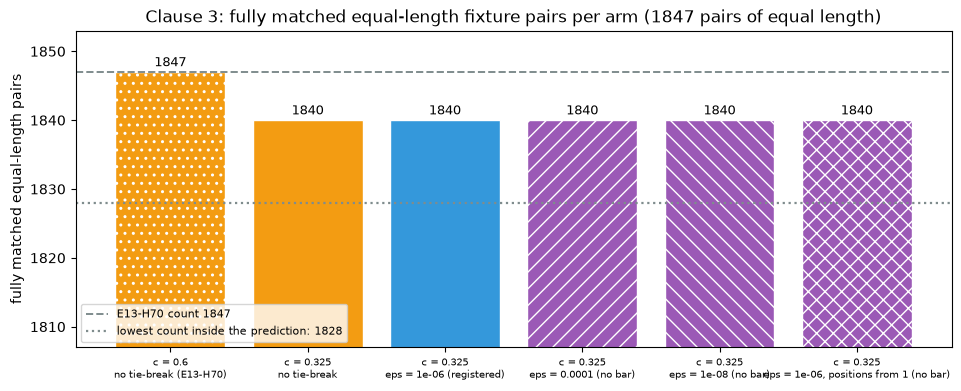

In [30]:
fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
keys = list(ARMS)
counts = [ORDER[key]["fully_matched_pairs"] for key in keys]
bars = ax.bar(range(len(keys)), counts, color=[ARM_COLOUR[key] for key in keys], hatch=[ARM_HATCH[key] for key in keys], edgecolor="white")
ax.bar_label(bars, labels=[str(v) for v in counts], fontsize=9, padding=2)
ax.axhline(RECORDED["identities"], color=COL_REFERENCE, ls="--", lw=1.4, label=f"E13-H70 count {RECORDED['identities']}")
ax.axhline(RECORDED["identities"] - COUNT_DROP_BELOW + 1, color=COL_REFERENCE, ls=":", lw=1.6,
           label=f"lowest count inside the prediction: {RECORDED['identities'] - COUNT_DROP_BELOW + 1}")
ax.set_ylim(RECORDED["identities"] - 2 * COUNT_DROP_BELOW, RECORDED["identities"] + 6)
ax.set_xticks(range(len(keys)), [ARMS[key].label.replace(", ", "\n", 1) for key in keys], fontsize=7)
ax.set_ylabel("fully matched equal-length pairs")
ax.set_title(f"Clause 3: fully matched equal-length fixture pairs per arm ({N_EQUAL_LENGTH} pairs of equal length)")
ax.legend(fontsize=8, loc="lower left")
plt.show()

## Clause 4 - per-statement map

The E13-H71 macro-F1 over {kept, removed, added} on the 900 edited pairs, read at `c = 0.325` with the tie-break
on. The bar is at least 0.90 on half A and on half B. E13-H71 chose `c = 0.325` on half A, so the half B reading is
the held-out one and the half A reading is the calibration reading. The table adds how many labels the tie-break
changes against the same cutoff without it.

In [31]:
C4 = MAP[REG]
CLAUSE4_MET = bool(C4["macro_f1"]["half_A"] >= MACRO_F1_BAR and C4["macro_f1"]["half_B"] >= MACRO_F1_BAR)
N_MAP_STATEMENTS = int(sum(p["y_a"].size + p["y_b"].size for p in EDIT_PAIRS))

t = Table(title="Clause 4 - macro-F1 of the per-statement map on the 900 edited pairs, per arm", header_style="bold medium_purple")
t.add_column("arm")
for column in ("half A", "half B", "all pairs", "F1 kept / removed / added (all)", "pairs with a changed label", "statements with a changed label",
               "pairs with a changed target"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    row = MAP[key]
    t.add_row(arm.label, f"{row['macro_f1']['half_A']:.4f}", f"{row['macro_f1']['half_B']:.4f}", f"{row['macro_f1']['all']:.4f}",
              " / ".join(f"{row['f1']['all'][name]:.4f}" for name in CLASS_NAMES), f"{row['pairs_with_a_changed_label']}/{len(EDIT_PAIRS)}",
              f"{row['statements_with_a_changed_label']}/{N_MAP_STATEMENTS}", f"{row['pairs_with_a_changed_target']}/{len(EDIT_PAIRS)}",
              style="bold" if key == REG else None)
c4_colour = "dark_sea_green" if CLAUSE4_MET else "indian_red"
console.print(Group(t, Panel(
    f"[bold {c4_colour}]clause 4 {'MET' if CLAUSE4_MET else 'NOT MET'}[/bold {c4_colour}] under {ARMS[REG].label}\n"
    f"macro-F1 half A {C4['macro_f1']['half_A']:.4f} ({C4['n_pairs']['half_A']} pairs), half B {C4['macro_f1']['half_B']:.4f}"
    f" ({C4['n_pairs']['half_B']} pairs), bar >= {MACRO_F1_BAR} in both\n"
    f"without the tie-break: half A {MAP[PLAIN]['macro_f1']['half_A']:.4f}, half B {MAP[PLAIN]['macro_f1']['half_B']:.4f}\n"
    "'changed' columns compare an arm with the arm without a tie-break at the registered cutoff; 'target' is the matched B index per A statement",
    border_style=c4_colour, expand=False)))

                                    Clause 4 - macro-F1 of the per-statement map on the 900 edited pairs, per arm                                     
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃                       ┃        ┃        ┃           ┃   F1 kept / removed / ┃  pairs with a changed ┃    statements with a ┃  pairs with a changed ┃
┃ arm                   ┃ half A ┃ half B ┃ all pairs ┃           added (all) ┃                 label ┃        changed label ┃                target ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ c = 0.6, no tie-break │ 0.7828 │ 0.7713 │    0.7771 │     0.9695 / 0.6928 / │               293/900 │           1030/21060 │               293/900 │
│ (E13-H70)             │        │        │           │                0.6688 │                       │                      │                       │
│ c = 0.325, no         │ 0.9674 │ 0.9772 │    0.9723 │     0.9951 / 0.9792 / │                 0/900 │              0/21060 │                 0/900 │
│ tie-break             │        │        │           │                0.9426 │                       │                      │                       │
│ c = 0.325, eps =      │ 0.9674 │ 0.9772 │    0.9723 │     0.9951 / 0.9792 / │                 0/900 │              0/21060 │                 0/900 │
│ 1e-06 (registered)    │        │        │           │                0.9426 │                       │                      │                       │
│ c = 0.325, eps =      │ 0.9674 │ 0.9772 │    0.9723 │     0.9951 / 0.9792 / │                 0/900 │              0/21060 │                 0/900 │
│ 0.0001 (no bar)       │        │        │           │                0.9426 │                       │                      │                       │
│ c = 0.325, eps =      │ 0.9674 │ 0.9772 │    0.9723 │     0.9951 / 0.9792 / │                 0/900 │              0/21060 │                 0/900 │
│ 1e-08 (no bar)        │        │        │           │                0.9426 │                       │                      │                       │
│ c = 0.325, eps =      │ 0.9674 │ 0.9772 │    0.9723 │     0.9951 / 0.9792 / │                 0/900 │              0/21060 │                 0/900 │
│ 1e-06, positions from │        │        │           │                0.9426 │                       │                      │                       │
│ 1 (no bar)            │        │        │           │                       │                       │                      │                       │
└───────────────────────┴────────┴────────┴───────────┴───────────────────────┴───────────────────────┴──────────────────────┴───────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 4 MET under c = 0.325, eps = 1e-06 (registered)                                                                                      │
│ macro-F1 half A 0.9674 (450 pairs), half B 0.9772 (450 pairs), bar >= 0.9 in both                                                           │
│ without the tie-break: half A 0.9674, half B 0.9772                                                                                         │
│ 'changed' columns compare an arm with the arm without a tie-break at the registered cutoff; 'target' is the matched B index per A statement │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

The bars give the macro-F1 of each half per arm. The reading to check is every bar against the registered bar
(dashed) and the registered arm against the arm without a tie-break.

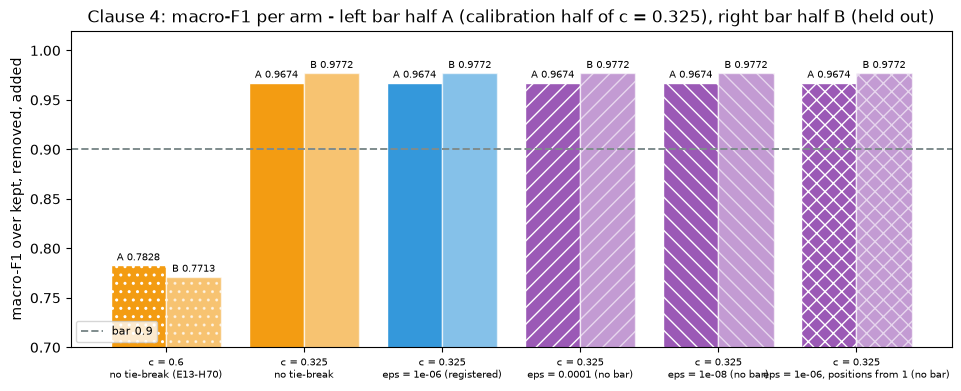

In [32]:
fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
keys = list(ARMS)
x = np.arange(len(keys))
for shift, half, alpha in ((-0.2, "half_A", 1.0), (0.2, "half_B", 0.6)):
    values = [MAP[key]["macro_f1"][half] for key in keys]
    bars = ax.bar(x + shift, values, 0.4, color=[ARM_COLOUR[key] for key in keys], hatch=[ARM_HATCH[key] for key in keys], edgecolor="white", alpha=alpha)
    ax.bar_label(bars, labels=[f"{half[-1]} {v:.4f}" for v in values], fontsize=7, padding=2)
ax.axhline(MACRO_F1_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"bar {MACRO_F1_BAR}")
ax.set_ylim(0.7, 1.02)
ax.set_xticks(x, [ARMS[key].label.replace(", ", "\n", 1) for key in keys], fontsize=7)
ax.set_ylabel("macro-F1 over kept, removed, added")
ax.set_title("Clause 4: macro-F1 per arm - left bar half A (calibration half of c = 0.325), right bar half B (held out)")
ax.legend(fontsize=8, loc="lower left")
plt.show()

## Readings without a bar

The record lists five readings that carry no bar: the arms `ε = 1e-4` and `ε = 1e-8`, the pure deletions on the
53-statement document against the identity gap of the shorter document, the 66 natural fixture pairs of unequal
length, and the E13-H71 no-edit control at `c = 0.325`. Two executor readings are added and labelled as such: the
position term counted from 1, because the record leaves the index open, and the shorter document encoded in its
own call, because every registered deletion case builds the shorter document from row copies of the longer one.
None of these readings enters the verdict.

### All arms on the four clauses

In [33]:
t = Table(title="Every arm on the readings of the four clauses", header_style="bold medium_purple")
t.add_column("arm")
for column in ("third pass: matched <= shipped", "third pass: textually equal", f"280 deletions <= {GAP_BAR}", "AUC",
               "fully matched pairs = shipped", "macro-F1 half A", "macro-F1 half B"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    t.add_row(arm.label, f"{THIRD[key]['at_or_below_shipped']}/{THIRD[key]['cases']}", f"{THIRD[key]['text_equal']}/{THIRD[key]['cases']}",
              f"{ORDER[key]['deletion_within_bar']}/{del_df.height}", f"{ORDER[key]['auc']:.6f}",
              f"{ORDER[key]['fully_matched_exactly_equal']}/{ORDER[key]['fully_matched_pairs']}",
              f"{MAP[key]['macro_f1']['half_A']:.4f}", f"{MAP[key]['macro_f1']['half_B']:.4f}", style="bold" if key == REG else None)

# per set: the cases whose matched pairs the arm changes against the arm without a tie-break at the registered cutoff
CHANGED = {
    key: {
        "third_pass_repeated_kept": kept_df.height - int(kept_df[f"same_{key}"].sum()),
        "third_pass_repeated_removed": removed_df.height - int(removed_df[f"same_{key}"].sum()),
        "deletion_cases": del_df.height - int(del_df[f"same_{key}"].sum()),
        "reordered_and_deleted_cases": pos_df.height - int(pos_df[f"same_{key}"].sum()),
        "fixture_pairs": pair_df.height - int(pair_df[f"same_{key}"].sum()),
        "edited_pairs": MAP[key]["pairs_with_a_changed_target"],
    }
    for key in ARMS
}
SET_SIZES = {"third_pass_repeated_kept": kept_df.height, "third_pass_repeated_removed": removed_df.height, "deletion_cases": del_df.height,
             "reordered_and_deleted_cases": pos_df.height, "fixture_pairs": pair_df.height, "edited_pairs": len(EDIT_PAIRS)}
t2 = Table(title=f"Cases whose matched pairs differ from the arm '{ARMS[PLAIN].label}'", header_style="bold medium_purple")
t2.add_column("arm")
for name, size in SET_SIZES.items():
    t2.add_column(f"{name.replace('_', ' ')} (of {size})", justify="right")
for key, arm in ARMS.items():
    t2.add_row(arm.label, *[str(CHANGED[key][name]) for name in SET_SIZES], style="bold" if key == REG else None)
console.print(Group(t, t2))

                                                    Every arm on the readings of the four clauses                                                     
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃                   ┃        third pass: ┃       third pass: ┃   280 deletions <= ┃          ┃     fully matched ┃                 ┃                 ┃
┃ arm               ┃ matched <= shipped ┃   textually equal ┃              0.005 ┃      AUC ┃   pairs = shipped ┃ macro-F1 half A ┃ macro-F1 half B ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ c = 0.6, no       │             99/120 │            88/120 │            280/280 │ 0.999903 │         1847/1847 │          0.7828 │          0.7713 │
│ tie-break         │                    │                   │                    │          │                   │                 │                 │
│ (E13-H70)         │                    │                   │                    │          │                   │                 │                 │
│ c = 0.325, no     │             99/120 │            88/120 │            280/280 │ 0.999903 │         1840/1840 │          0.9674 │          0.9772 │
│ tie-break         │                    │                   │                    │          │                   │                 │                 │
│ c = 0.325, eps =  │            120/120 │           111/120 │            280/280 │ 0.999903 │         1840/1840 │          0.9674 │          0.9772 │
│ 1e-06             │                    │                   │                    │          │                   │                 │                 │
│ (registered)      │                    │                   │                    │          │                   │                 │                 │
│ c = 0.325, eps =  │            120/120 │           111/120 │            280/280 │ 0.999903 │         1840/1840 │          0.9674 │          0.9772 │
│ 0.0001 (no bar)   │                    │                   │                    │          │                   │                 │                 │
│ c = 0.325, eps =  │            120/120 │           111/120 │            280/280 │ 0.999903 │         1840/1840 │          0.9674 │          0.9772 │
│ 1e-08 (no bar)    │                    │                   │                    │          │                   │                 │                 │
│ c = 0.325, eps =  │            120/120 │           111/120 │            280/280 │ 0.999903 │         1840/1840 │          0.9674 │          0.9772 │
│ 1e-06, positions  │                    │                   │                    │          │                   │                 │                 │
│ from 1 (no bar)   │                    │                   │                    │          │                   │                 │                 │
└───────────────────┴────────────────────┴───────────────────┴────────────────────┴──────────┴───────────────────┴─────────────────┴─────────────────┘
                                       Cases whose matched pairs differ from the arm 'c = 0.325, no tie-break'                                        
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃                    ┃         third pass ┃         third pass ┃                     ┃      reordered and ┃                     ┃                    ┃
┃                    ┃  repeated kept (of ┃   repeated removed ┃  deletion cases (of ┃  deleted cases (of ┃   fixture pairs (of ┃   edited pairs (of ┃
┃ arm                ┃               120) ┃           (of 120) ┃                280) ┃             10010) ┃               1913) ┃               900) ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━

### The 53-statement document

The same third-pass deletions on `source` with its 9 repeated statements removed. The record asks for the
difference between the matched order gap and the identity gap `opw_gap(B, B)` of the shorter document. That call
passes one object twice, and POT then sets the diagonal of the ground cost to exactly zero; the matched reading
always passes two arrays. Both forms of the identity gap are therefore read: `opw_gap(B, B)` and
`opw_gap(B, copy of B)`.

In [34]:
REMOVED_DOC = {}
for key in ARMS:
    matched = removed_df[key].to_numpy()
    REMOVED_DOC[key] = third_pass_summary(removed_df, key) | {
        "equal_to_floor_same": int((matched == removed_df["floor_same"].to_numpy()).sum()),
        "max_abs_diff_to_floor_same": float(np.abs(matched - removed_df["floor_same"].to_numpy()).max()),
        "max_abs_diff_to_floor_copy": float(np.abs(matched - removed_df["floor_copy"].to_numpy()).max()),
        "median_diff_to_floor_same": float(np.median(matched - removed_df["floor_same"].to_numpy())),
    }
FLOOR_SAME_MAX = float(removed_df["floor_same"].max())
FLOOR_COPY_MAX = float(removed_df["floor_copy"].max())

t = Table(title=f"Without a bar - k={LONG_K} interior deletions on '{LONG_DOC}' with {DOC_REMOVED} ({len(unique_positions)} statements, {removed_df.height} cases)",
          header_style="bold medium_purple")
t.add_column("arm")
for column in ("survivors recovered", "textually equal", "matched <= shipped", f"matched > {GAP_BAR}", "matched = opw_gap(B, copy of B)",
               "matched = opw_gap(B, B)", "max |matched - opw_gap(B, B)|", "median (matched - opw_gap(B, B))"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    row = REMOVED_DOC[key]
    t.add_row(arm.label, f"{row['survivors_recovered']}/{row['cases']}", f"{row['text_equal']}/{row['cases']}", f"{row['at_or_below_shipped']}/{row['cases']}",
              f"{row['above_gap_bar']}/{row['cases']}", f"{row['equal_to_floor_copy']}/{row['cases']}", f"{row['equal_to_floor_same']}/{row['cases']}",
              f"{row['max_abs_diff_to_floor_same']:.3e}", f"{row['median_diff_to_floor_same']:+.3e}", style="bold" if key == REG else None)
console.print(Group(t,
    f"largest identity gap of a shortened document: opw_gap(B, B) {FLOOR_SAME_MAX:.3e}, opw_gap(B, copy of B) {FLOOR_COPY_MAX:.3e}"
    f" | paraphrase reference {GAP_BAR}"))

                    Without a bar - k=2 interior deletions on 'source' with repeated statements removed (53 statements, 120 cases)                    
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃                ┃               ┃                ┃               ┃                ┃     matched = ┃                ┃  max |matched ┃         median ┃
┃                ┃     survivors ┃      textually ┃    matched <= ┃      matched > ┃    opw_gap(B, ┃      matched = ┃  - opw_gap(B, ┃     (matched - ┃
┃ arm            ┃     recovered ┃          equal ┃       shipped ┃          0.005 ┃    copy of B) ┃  opw_gap(B, B) ┃           B)| ┃ opw_gap(B, B)) ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ c = 0.6, no    │       120/120 │        120/120 │       120/120 │         63/120 │       120/120 │          0/120 │     7.813e-06 │     +5.463e-06 │
│ tie-break      │               │                │               │                │               │                │               │                │
│ (E13-H70)      │               │                │               │                │               │                │               │                │
│ c = 0.325, no  │       120/120 │        120/120 │       120/120 │         63/120 │       120/120 │          0/120 │     7.813e-06 │     +5.463e-06 │
│ tie-break      │               │                │               │                │               │                │               │                │
│ c = 0.325, eps │       120/120 │        120/120 │       120/120 │         63/120 │       120/120 │          0/120 │     7.813e-06 │     +5.463e-06 │
│ = 1e-06        │               │                │               │                │               │                │               │                │
│ (registered)   │               │                │               │                │               │                │               │                │
│ c = 0.325, eps │       120/120 │        120/120 │       120/120 │         63/120 │       120/120 │          0/120 │     7.813e-06 │     +5.463e-06 │
│ = 0.0001 (no   │               │                │               │                │               │                │               │                │
│ bar)           │               │                │               │                │               │                │               │                │
│ c = 0.325, eps │       120/120 │        120/120 │       120/120 │         63/120 │       120/120 │          0/120 │     7.813e-06 │     +5.463e-06 │
│ = 1e-08 (no    │               │                │               │                │               │                │               │                │
│ bar)           │               │                │               │                │               │                │               │                │
│ c = 0.325, eps │       120/120 │        120/120 │       120/120 │         63/120 │       120/120 │          0/120 │     7.813e-06 │     +5.463e-06 │
│ = 1e-06,       │               │                │               │                │               │                │               │                │
│ positions from │               │                │               │                │               │                │               │                │
│ 1 (no bar)     │               │                │               │                │               │                │               │                │
└────────────────┴───────────────┴────────────────┴───────────────┴────────────────┴───────────────┴────────────────┴───────────────┴────────────────┘
largest identity gap of a shortened document: opw_gap(B, B) 7.040e-03, opw_gap(B, copy of B) 7.047e-03 | paraphrase reference 0.005

### The 66 natural pairs of unequal length

The fixture pairs whose two documents differ in length (cross-summary, tier-contrast and summary-against-source
pairs). No ground truth states what their order gap should read, so the table is a reading and not a test. It
shows whether the cutoff and the tie-break move the matched gap on pairs that are not synthetic deletions.

In [35]:
unequal_df = pair_df.filter(pl.col("n_a") != pl.col("n_b"))


def unequal_summary(frame: pl.DataFrame, key: str) -> dict:
    """Shipped against matched order gap over unequal-length pairs under the arm ``key`` (the E13-H70 table)."""
    shipped, matched = frame["shipped"].to_numpy(), frame[key].to_numpy()
    scored = ~np.isnan(matched)
    shorter = np.minimum(frame["n_a"].to_numpy(), frame["n_b"].to_numpy())
    return {
        "pairs": frame.height, "no_matched_pair": int((~scored).sum()),
        "shipped_median": float(np.median(shipped)), "matched_median": float(np.median(matched[scored])),
        "matched_below_shipped": int((matched[scored] < shipped[scored]).sum()),
        "matched_above_shipped": int((matched[scored] > shipped[scored]).sum()),
        "matched_within_bar": int((matched[scored] <= GAP_BAR).sum()),
        "matched_exactly_zero": int((matched[scored] == 0.0).sum()),
        "matched_max": float(matched[scored].max()),
        "shorter_fully_matched": int((frame[f"n_{key}"].to_numpy() == shorter).sum()),
        "mean_matched_statements": float(frame[f"n_{key}"].mean()),
        "pairs_with_at_most_one_matched_pair": int((frame[f"n_{key}"] <= 1).sum()),
        "mean_statements_of_the_shorter_document": float(shorter.mean()),
        "readings_equal_to_no_tie_break": int(((matched == frame[PLAIN].to_numpy()) | (np.isnan(matched) & frame[PLAIN].is_nan().to_numpy())).sum()),
        "matchings_equal_to_no_tie_break": int(frame[f"same_{key}"].sum()),
    }


UNEQUAL = {key: unequal_summary(unequal_df, key) for key in ARMS}
t = Table(title=f"Without a bar - the {unequal_df.height} fixture pairs of unequal length", header_style="bold medium_purple")
t.add_column("arm")
for column in ("matched median", "below / above shipped", f"<= {GAP_BAR}", "exactly 0", "matched max", "shorter side fully matched",
               "mean matched statements", "at most 1 matched pair", "no matched pair", "matchings = no tie-break", "readings = no tie-break"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    row = UNEQUAL[key]
    t.add_row(arm.label, f"{row['matched_median']:.4f}", f"{row['matched_below_shipped']} / {row['matched_above_shipped']}",
              f"{row['matched_within_bar']}/{row['pairs']}", f"{row['matched_exactly_zero']}/{row['pairs']}", f"{row['matched_max']:.4f}",
              f"{row['shorter_fully_matched']}/{row['pairs']}", f"{row['mean_matched_statements']:.2f}",
              f"{row['pairs_with_at_most_one_matched_pair']}/{row['pairs']}", str(row["no_matched_pair"]),
              f"{row['matchings_equal_to_no_tie_break']}/{row['pairs']}", f"{row['readings_equal_to_no_tie_break']}/{row['pairs']}",
              style="bold" if key == REG else None)
console.print(Group(t, f"shipped order gap on the same pairs: median {UNEQUAL[REG]['shipped_median']:.4f} | mean statements of the shorter document:"
                       f" {UNEQUAL[REG]['mean_statements_of_the_shorter_document']:.2f} | no ground truth exists for these pairs"))

                                                Without a bar - the 66 fixture pairs of unequal length                                                
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃            ┃            ┃           ┃          ┃           ┃            ┃   shorter ┃            ┃           ┃            ┃           ┃            ┃
┃            ┃            ┃   below / ┃          ┃           ┃            ┃      side ┃       mean ┃ at most 1 ┃            ┃ matchings ┃ readings = ┃
┃            ┃    matched ┃     above ┃          ┃           ┃    matched ┃     fully ┃    matched ┃   matched ┃ no matched ┃      = no ┃         no ┃
┃ arm        ┃     median ┃   shipped ┃ <= 0.005 ┃ exactly 0 ┃        max ┃   matched ┃ statements ┃      pair ┃       pair ┃ tie-break ┃  tie-break ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ c = 0.6,   │     0.0200 │   42 / 24 │    22/66 │     12/66 │     0.1621 │     59/66 │       8.14 │      0/66 │          0 │     15/66 │      17/66 │
│ no         │            │           │          │           │            │           │            │           │            │           │            │
│ tie-break  │            │           │          │           │            │           │            │           │            │           │            │
│ (E13-H70)  │            │           │          │           │            │           │            │           │            │           │            │
│ c = 0.325, │     0.0000 │   49 / 15 │    38/66 │     35/66 │     0.1827 │     15/66 │       4.68 │     19/66 │          2 │     66/66 │      66/66 │
│ no         │            │           │          │           │            │           │            │           │            │           │            │
│ tie-break  │            │           │          │           │            │           │            │           │            │           │            │
│ c = 0.325, │     0.0000 │   49 / 15 │    38/66 │     35/66 │     0.1827 │     15/66 │       4.68 │     19/66 │          2 │     66/66 │      66/66 │
│ eps =      │            │           │          │           │            │           │            │           │            │           │            │
│ 1e-06      │            │           │          │           │            │           │            │           │            │           │            │
│ (register… │            │           │          │           │            │           │            │           │            │           │            │
│ c = 0.325, │     0.0000 │   49 / 15 │    38/66 │     35/66 │     0.1827 │     15/66 │       4.68 │     19/66 │          2 │     66/66 │      66/66 │
│ eps =      │            │           │          │           │            │           │            │           │            │           │            │
│ 0.0001 (no │            │           │          │           │            │           │            │           │            │           │            │
│ bar)       │            │           │          │           │            │           │            │           │            │           │            │
│ c = 0.325, │     0.0000 │   49 / 15 │    38/66 │     35/66 │     0.1827 │     15/66 │       4.68 │     19/66 │          2 │     66/66 │      66/66 │
│ eps =      │            │           │          │           │            │           │            │           │            │           │            │
│ 1e-08 (no  │            │           │          │           │            │           │            │           │            │           │            │
│ bar)       │            │           │          │           │            │           │            │           │            │           │            │
│ c = 0.325, │     0.0000 │   49 / 15 │    38/66 │     35/66 │     0.1827 

### The E13-H71 no-edit control

Each unedited base document against its own back-translation: no statement is removed, so every statement the
map reads as removed is a false reading. E13-H71 read 1 of 117 with the cutoff of each direction (`0.31` on half
A, `0.325` on half B); here every base is read at the single cutoff `0.325`.

In [36]:
t = Table(title=f"Without a bar - no-edit control, {NO_EDIT_STATEMENTS} statements of {len(BASES)} unedited bases against their back-translation",
          header_style="bold medium_purple")
t.add_column("arm")
for column in ("statements read as removed", "bases with one or more"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    row = MAP[key]
    t.add_row(arm.label, f"{row['no_edit_read_as_removed']}/{NO_EDIT_STATEMENTS}",
              ", ".join(f"{b} {v}" for b, v in row["no_edit_per_base"].items() if v) or "none", style="bold" if key == REG else None)
console.print(Group(t, f"recorded in E13-H71 with the cutoff of each direction: {h71_saved['mechanism']['no_edit_control']['read_as_removed']}/"
                       f"{h71_saved['mechanism']['no_edit_control']['n_statements']} | largest true-pair cost: "
                       f"{max(float(np.diag(PAIR_COST[b]).max()) for b in BASES):.6f}"))

    Without a bar - no-edit control, 117 statements of 10 unedited bases against their back-translation    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                                               ┃ statements read as removed ┃ bases with one or more ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ c = 0.6, no tie-break (E13-H70)                   │                      0/117 │                   none │
│ c = 0.325, no tie-break                           │                      0/117 │                   none │
│ c = 0.325, eps = 1e-06 (registered)               │                      0/117 │                   none │
│ c = 0.325, eps = 0.0001 (no bar)                  │                      0/117 │                   none │
│ c = 0.325, eps = 1e-08 (no bar)                   │                      0/117 │                   none │
│ c = 0.325, eps = 1e-06, positions from 1 (no bar) │                      0/117 │                   none │
└───────────────────────────────────────────────────┴────────────────────────────┴────────────────────────┘
recorded in E13-H71 with the cutoff of each direction: 1/117 | largest true-pair cost: 0.322901

### Executor reading - the shorter document encoded in its own call

Every deletion case of the record builds the shorter document as `B = A[keep]`, so a surviving statement and its
copy share one embedding row and the ground costs inside the tie group are equal by construction. The shipped
pipeline encodes each document in its own call. This reading repeats the 120 clause 1 cases with the shorter
document encoded on its own, `B = encode(texts of B)`, and reads the precondition of the kill-gate and the two
conditions of clause 1 again. It also reads how far the separately encoded rows are from the row copies and
whether the shipped gap, the matched gap and the matched pairs of each case move. It is outside the record and
outside the bar.

In [37]:
own_rows = []
for case in progress([c for c in LONG_CASES if c["doc"] == DOC_KEPT], "shorter document encoded in its own call"):
    texts_a = long_texts[: case["n"]]
    texts_b = [texts_a[i] for i in case["keep"]]
    A = LONG_DOCS[DOC_KEPT][: case["n"]]
    B = ENC.encode(texts_b)
    copies = A[case["keep"]]                                   # the registered construction of the same case
    readings, matchings = score_case(A, B)
    copy_readings, copy_matchings = score_case(A, copies)
    group = tie_group(cost_matrix(A, B), texts_a, texts_b)
    repeated_b = [j for j, text in enumerate(texts_b) if text == REPEATED_TEXT]
    row_diff = np.abs(B - copies).max(axis=1)
    differing = np.flatnonzero(row_diff > 0)
    row = {
        "n": case["n"], "rep": case["rep"], "dropped_repeated": sum(texts_a[i] == REPEATED_TEXT for i in case["drop"]),
        "rows_equal_to_copies": bool(np.array_equal(B, copies)),
        "max_abs_row_diff": float(row_diff.max()), "rows_differing": int(differing.size),
        "min_words_differing": min((len(texts_b[j].split()) for j in differing), default=0),
        "shipped_copy": copy_readings["shipped"], "reg_copy": copy_readings[REG],
        "same_pairs_as_copies": bool(all(np.array_equal(a, b) for a, b in zip(matchings[REG], copy_matchings[REG]))),
        "repeated_rows_equal_to_a": bool(all(np.array_equal(B[j], repeated_rows[0]) for j in repeated_b)),
        "tie_rows": group.shape[0], "tie_cols": group.shape[1],
        "tie_bit_patterns": int(bit_patterns(group).size), "tie_spread": float(group.max() - group.min()) if group.size else 0.0,
        **readings,
    }
    for key, (rows, _) in matchings.items():
        row[f"txt_{key}"] = [texts_a[i] for i in rows] == texts_b
    own_rows.append(row)
own_df = pl.DataFrame(own_rows)

shorter document encoded in its own call:   0%|          | 0/120 [00:00<?, ?it/s]

shorter document encoded in its own call:  69%|██████▉   | 83/120 [00:15<00:06,  5.47it/s]

shorter document encoded in its own call:  69%|██████▉   | 83/120 [00:26<00:06,  5.47it/s]

shorter document encoded in its own call: 100%|██████████| 120/120 [00:30<00:00,  3.70it/s]

shorter document encoded in its own call: 100%|██████████| 120/120 [00:30<00:00,  3.97it/s]

In [38]:
OWN = {}
for key in ARMS:
    matched, shipped = own_df[key].to_numpy(), own_df["shipped"].to_numpy()
    OWN[key] = {"cases": own_df.height, "text_equal": int(own_df[f"txt_{key}"].sum()), "at_or_below_shipped": int((matched <= shipped).sum()),
                "above_gap_bar": int((matched > GAP_BAR).sum()), "matched_max": float(np.nanmax(matched)), "matched_median": float(np.nanmedian(matched))}
own_group = own_df.filter(has_group)
OWN_ROWS_EQUAL = int(own_df["rows_equal_to_copies"].sum())
OWN_REPEATED_ROWS_EQUAL = int(own_df["repeated_rows_equal_to_a"].sum())
OWN_EXACT_TIE = own_group.filter(pl.col("tie_bit_patterns") == 1).height
OWN_TIE_SPREAD_MAX = float(own_group["tie_spread"].max())
OWN_EPS_BELOW_SPREAD = own_group.filter(pl.col("tie_spread") > EPS_REGISTERED).height
moved_df = own_df.filter(~pl.col("rows_equal_to_copies"))
OWN_ROW_DIFF_MAX = float(own_df["max_abs_row_diff"].max())
OWN_ROWS_DIFFERING = int(own_df["rows_differing"].sum())
OWN_MIN_WORDS_DIFFERING = int(moved_df["min_words_differing"].min()) if moved_df.height else 0
OWN_SHIPPED_EQUAL = int((own_df["shipped"] == own_df["shipped_copy"]).sum())
OWN_SHIPPED_DIFF_MAX = float((own_df["shipped"] - own_df["shipped_copy"]).abs().max())
OWN_REG_EQUAL = int((own_df[REG] == own_df["reg_copy"]).sum())
OWN_REG_DIFF_MAX = float((own_df[REG] - own_df["reg_copy"]).abs().max())
OWN_SAME_PAIRS = int(own_df["same_pairs_as_copies"].sum())

t = Table(title=f"Executor reading - the {own_df.height} clause 1 cases with the shorter document encoded in its own call", header_style="bold medium_purple")
t.add_column("arm")
for column in ("textually equal", "matched <= shipped", f"matched > {GAP_BAR}", "matched median", "matched max"):
    t.add_column(column, justify="right")
for key, arm in ARMS.items():
    row = OWN[key]
    t.add_row(arm.label, f"{row['text_equal']}/{row['cases']}", f"{row['at_or_below_shipped']}/{row['cases']}", f"{row['above_gap_bar']}/{row['cases']}",
              f"{row['matched_median']:.3e}", f"{row['matched_max']:.3e}", style="bold" if key == REG else None)
console.print(Group(t,
    f"[bold]precondition under separate encoding[/bold]\n"
    f"  cases in which every row of the separately encoded B is bitwise equal to its row copy A[keep]: {OWN_ROWS_EQUAL}/{own_df.height}\n"
    f"  in the other {moved_df.height} cases: {OWN_ROWS_DIFFERING} rows differ, largest difference of one embedding entry {OWN_ROW_DIFF_MAX:.3e},"
    f" shortest statement with a differing row {OWN_MIN_WORDS_DIFFERING} words\n"
    f"  against the row-copy reading of the same case: shipped gap equal in {OWN_SHIPPED_EQUAL}/{own_df.height} (largest |difference|"
    f" {OWN_SHIPPED_DIFF_MAX:.3e}), matched gap of the registered arm equal in {OWN_REG_EQUAL}/{own_df.height} (largest |difference|"
    f" {OWN_REG_DIFF_MAX:.3e}), matched pairs equal in {OWN_SAME_PAIRS}/{own_df.height}\n"
    f"  cases in which every repeated statement of B has the embedding row the repeated statements of A have: {OWN_REPEATED_ROWS_EQUAL}/{own_df.height}\n"
    f"  cases whose tie group shares one bit pattern: {OWN_EXACT_TIE}/{own_group.height}\n"
    f"  largest spread (max - min) of the ground cost inside a tie group: {OWN_TIE_SPREAD_MAX:.3e};"
    f" cases whose spread is above eps = {EPS_REGISTERED:g}: {OWN_EPS_BELOW_SPREAD}/{own_group.height}\n"
    f"shipped order gap on these cases: median {float(own_df['shipped'].median()):.5f}"))

                         Executor reading - the 120 clause 1 cases with the shorter document encoded in its own call                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ arm                                               ┃ textually equal ┃ matched <= shipped ┃ matched > 0.005 ┃ matched median ┃ matched max ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ c = 0.6, no tie-break (E13-H70)                   │          88/120 │             99/120 │          23/120 │      3.211e-03 │   3.246e-01 │
│ c = 0.325, no tie-break                           │          88/120 │             99/120 │          23/120 │      3.211e-03 │   3.246e-01 │
│ c = 0.325, eps = 1e-06 (registered)               │         111/120 │            120/120 │           0/120 │      2.888e-03 │   4.876e-03 │
│ c = 0.325, eps = 0.0001 (no bar)                  │         111/120 │            120/120 │           0/120 │      2.888e-03 │   4.876e-03 │
│ c = 0.325, eps = 1e-08 (no bar)                   │         111/120 │            120/120 │           0/120 │      2.888e-03 │   4.876e-03 │
│ c = 0.325, eps = 1e-06, positions from 1 (no bar) │         111/120 │            120/120 │           0/120 │      2.888e-03 │   4.876e-03 │
└───────────────────────────────────────────────────┴─────────────────┴────────────────────┴─────────────────┴────────────────┴─────────────┘
precondition under separate encoding
  cases in which every row of the separately encoded B is bitwise equal to its row copy A: 96/120
  in the other 24 cases: 41 rows differ, largest difference of one embedding entry 4.095e-03, shortest statement with a differing row 26 words
  against the row-copy reading of the same case: shipped gap equal in 96/120 (largest |difference| 1.288e-03), matched gap of the registered arm equal
in 96/120 (largest |difference| 6.671e-05), matched pairs equal in 120/120
  cases in which every repeated statement of B has the embedding row the repeated statements of A have: 120/120
  cases whose tie group shares one bit pattern: 120/120
  largest spread (max - min) of the ground cost inside a tie group: 0.000e+00; cases whose spread is above eps = 1e-06: 0/120
shipped order gap on these cases: median 0.03664

The bars compare, per arm, the count of textually equal sub-sequences on the 120 clause 1 cases: with the shorter
document built from row copies (the registered construction, filled) and with the shorter document encoded in its
own call (the executor reading, hatched outline). The reading to check is each bar against the registered floor
of 114.

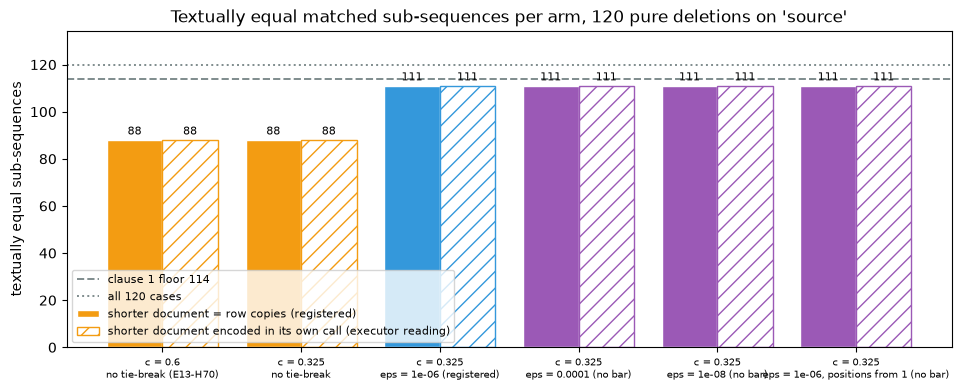

In [39]:
fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
keys = list(ARMS)
x = np.arange(len(keys))
copies = [THIRD[key]["text_equal"] for key in keys]
own = [OWN[key]["text_equal"] for key in keys]
bars = ax.bar(x - 0.2, copies, 0.4, color=[ARM_COLOUR[key] for key in keys], edgecolor="white", label="shorter document = row copies (registered)")
ax.bar_label(bars, labels=[str(v) for v in copies], fontsize=8, padding=2)
bars = ax.bar(x + 0.2, own, 0.4, color="white", edgecolor=[ARM_COLOUR[key] for key in keys], hatch="//", label="shorter document encoded in its own call (executor reading)")
ax.bar_label(bars, labels=[str(v) for v in own], fontsize=8, padding=2)
ax.axhline(TEXT_EQUAL_MIN, color=COL_REFERENCE, ls="--", lw=1.4, label=f"clause 1 floor {TEXT_EQUAL_MIN}")
ax.axhline(C1_CASES, color=COL_REFERENCE, ls=":", lw=1.4, label=f"all {C1_CASES} cases")
ax.set_ylim(0, C1_CASES * 1.12)
ax.set_xticks(x, [ARMS[key].label.replace(", ", "\n", 1) for key in keys], fontsize=7)
ax.set_ylabel("textually equal sub-sequences")
ax.set_title(f"Textually equal matched sub-sequences per arm, {C1_CASES} pure deletions on '{LONG_DOC}'")
ax.legend(fontsize=8, loc="lower left")
plt.show()

## Guardrails

The standing guardrails, measured. `V` counts the ordinality violations over the 6 gold × 4 adversarial
comparisons of the ibm panel on the shipped default path. The lever lives in this notebook, so both shipped
distances must be unchanged: the panel's `smd` and `order_gap` are read again and compared with `np.array_equal`
against the reading taken before the experiment, as are the default-path readings on `(gold, gold-2)` and the 280
shipped deletion readings. The source tree is fingerprinted at the start and at the end and `git status` is read
for `src/` and `tests/`. The metric-property row is a statement, not a test.

In [40]:
def state(ok: bool) -> str:
    """Rich-coloured guardrail state."""
    return "[dark_sea_green]hold[/dark_sea_green]" if ok else "[indian_red]BREACH[/indian_red]"


PANEL_AFTER = panel_reading()
tiers = np.array([tier for _, _, tier in PANEL[1:]])
gold_smd, adversarial_smd = PANEL_AFTER[0][tiers == "gold"], PANEL_AFTER[0][tiers == "adversarial"]
V = int(sum(1 for g in gold_smd for a in adversarial_smd if g >= a))
V_TOTAL = int(gold_smd.size * adversarial_smd.size)
PANEL_MARGIN_PTS = float((adversarial_smd.min() - gold_smd.max()) / SMD_MAX * 100)   # closeness = 1 - smd / SMD_MAX
SMD_IDENTICAL = bool(np.array_equal(PANEL_BEFORE[0], PANEL_AFTER[0]))
GAP_IDENTICAL = bool(np.array_equal(PANEL_BEFORE[1], PANEL_AFTER[1]))
FINGERPRINT_END = tree_fingerprint()
GIT_STATUS = subprocess.run(["git", "status", "--porcelain", "--", "src", "tests"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
SRC_UNTOUCHED = bool(FINGERPRINT_START == FINGERPRINT_END and GIT_STATUS == "")
guard_after = np.array([smd(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]]), opw_gap(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]])])
DEFAULT_PATH_EQUAL = bool(np.array_equal(guard_before, guard_after))
shipped_again = np.array([opw_gap(EMB[case["base"]], EMB[case["base"]][case["keep"]]) for case in CASES])
SHIPPED_280_EQUAL = bool(np.array_equal(del_df["shipped"].to_numpy(), shipped_again))
OVERRIDE_REMOVED = "embed_statements" not in vars(DD) and type(DD._segmenter).__name__ == "Segmenter"
GUARDRAILS_HOLD = bool(V == 0 and SMD_IDENTICAL and GAP_IDENTICAL and SRC_UNTOUCHED and DEFAULT_PATH_EQUAL and SHIPPED_280_EQUAL and OVERRIDE_REMOVED)

t = Table(title="Guardrails", header_style="bold medium_purple")
for column in ("guardrail", "reading", "state"):
    t.add_column(column)
t.add_row("V - content ordinality (ibm panel, shipped default path)", f"{V}/{V_TOTAL} violations, boundary margin {PANEL_MARGIN_PTS:+.2f} pts"
          f" (primer naive row: V {PANEL_PRIMER_ROW['V']}/24, margin {PANEL_PRIMER_ROW['margin_pts']:+.2f}); gold maximum {gold_smd.max():.4f},"
          f" adversarial minimum {adversarial_smd.min():.4f}", state(V == 0))
t.add_row(f"smd before = after, {PANEL_AFTER[0].size} anchor pairs", f"np.array_equal {SMD_IDENTICAL}", state(SMD_IDENTICAL))
t.add_row(f"order_gap before = after, {PANEL_AFTER[1].size} anchor pairs", f"np.array_equal {GAP_IDENTICAL}", state(GAP_IDENTICAL))
t.add_row("src/ and tests/ fingerprint start = end", f"{FINGERPRINT_START[:16]} = {FINGERPRINT_END[:16]}", state(FINGERPRINT_START == FINGERPRINT_END))
t.add_row("git status --porcelain -- src tests", "empty" if GIT_STATUS == "" else GIT_STATUS.replace("\n", "; "), state(GIT_STATUS == ""))
t.add_row(f"default path on {GUARD_PAIR}", f"smd {float(guard_after[0])!r}, order gap {float(guard_after[1])!r} - np.array_equal {DEFAULT_PATH_EQUAL}",
          state(DEFAULT_PATH_EQUAL))
t.add_row("280 shipped deletion readings recomputed", f"np.array_equal {SHIPPED_280_EQUAL}", state(SHIPPED_280_EQUAL))
t.add_row("instance overrides removed (embed_statements wrapper, pinned segmenter)", str(OVERRIDE_REMOVED), state(OVERRIDE_REMOVED))
t.add_row("metric property", "shipped smd (a metric) and shipped opw_gap (a score) are not edited; the matched gap is a notebook prototype and a score,"
          " the map is an annotation; no triangle test was run", "[dim]stated, not tested[/dim]")
console.print(Group(t, f"[bold]GUARDRAILS: {'ALL HOLD' if GUARDRAILS_HOLD else 'BREACHED'}[/bold]"))

                                                                      Guardrails                                                                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ guardrail                                                     ┃ reading                                                       ┃ state              ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ V - content ordinality (ibm panel, shipped default path)      │ 0/24 violations, boundary margin +4.71 pts (primer naive row: │ hold               │
│                                                               │ V 0/24, margin +4.71); gold maximum 0.2907, adversarial       │                    │
│                                                               │ minimum 0.3573                                                │                    │
│ smd before = after, 10 anchor pairs                           │ np.array_equal True                                           │ hold               │
│ order_gap before = after, 10 anchor pairs                     │ np.array_equal True                                           │ hold               │
│ src/ and tests/ fingerprint start = end                       │ 905a308ecd1b29d1 = 905a308ecd1b29d1                           │ hold               │
│ git status --porcelain -- src tests                           │ empty                                                         │ hold               │
│ default path on ('gold', 'gold-2')                            │ smd 0.22343884174015136, order gap 0.1343654387715936 -       │ hold               │
│                                                               │ np.array_equal True                                           │                    │
│ 280 shipped deletion readings recomputed                      │ np.array_equal True                                           │ hold               │
│ instance overrides removed (embed_statements wrapper, pinned  │ True                                                          │ hold               │
│ segmenter)                                                    │                                                               │                    │
│ metric property                                               │ shipped smd (a metric) and shipped opw_gap (a score) are not  │ stated, not tested │
│                                                               │ edited; the matched gap is a notebook prototype and a score,  │                    │
│                                                               │ the map is an annotation; no triangle test was run            │                    │
└───────────────────────────────────────────────────────────────┴───────────────────────────────────────────────────────────────┴────────────────────┘
GUARDRAILS: ALL HOLD

## Acceptance bar and verdict

The registered bar, applied literally: all four clauses at `c = 0.325` with `ε = 1e-6`. The verdict follows the
campaign vocabulary: a kill-gate harness check that does not reproduce reads `Blocked`, a missing exact tie
`Killed-at-gate`, a failed sanity check or a breached guardrail `Blocked`, a lever that meets its bar `Promoted`,
a lever that misses it `Refuted`. `Refuted (null)` is read only when the registered arm returns exactly the
third-pass readings of the arm without a tie-break. The prediction is checked claim by claim. "The 1847 fully
matched identities are unchanged" is read as: every fully matched equal-length pair still equals shipped `opw_gap`
and the tie-break does not move the count at the registered cutoff. The direction of the prediction is read on the
two third-pass counts, against the same cutoff without the tie-break, and on the sign of the change of the fully
matched count; the exact counts are separate rows.

In [41]:
BAR_MET = bool(CLAUSE1_MET and CLAUSE2_MET and CLAUSE3_MET and CLAUSE4_MET)
NO_EFFECT = bool(np.array_equal(kept_df[REG].to_numpy(), kept_df[PLAIN].to_numpy()))
if not HARNESS_REPRODUCED:
    VERDICT = "Blocked"
elif not EXACT_TIE_EXISTS:
    VERDICT = "Killed-at-gate"
elif not SANITY_PASSED or not GUARDRAILS_HOLD:
    VERDICT = "Blocked"
elif BAR_MET:
    VERDICT = "Promoted"
elif NO_EFFECT:
    VERDICT = "Refuted (null)"
else:
    VERDICT = "Refuted"

# the prediction of the record, claim by claim
PREDICTION = {
    "third_pass_at_or_below_shipped_120": bool(C1_AT_OR_BELOW == C1_CASES),
    "third_pass_text_equal_120": bool(C1_TEXT_EQUAL == C1_CASES),
    "deletion_readings_unchanged": DEL_EQUAL_TO_H70,
    "identities_unchanged": bool(C3["fully_matched_array_equal"] and ORDER[PLAIN]["fully_matched_pairs"] == C3["fully_matched_pairs"]),
    "count_falls_by_fewer_than_20": bool(0 <= COUNT_DROP < COUNT_DROP_BELOW),
}
PREDICTION_HELD = bool(all(PREDICTION.values()))
DIRECTION = {
    "fewer_cases_above_shipped_than_without_tie_break": bool(THIRD[REG]["above_shipped"] < THIRD[PLAIN]["above_shipped"]),
    "more_textually_equal_than_without_tie_break": bool(THIRD[REG]["text_equal"] > THIRD[PLAIN]["text_equal"]),
    "fully_matched_count_below_1847": bool(C3["fully_matched_pairs"] < RECORDED["identities"]),
}
DIRECTION_MATCHED = bool(all(DIRECTION.values()))

def yes(flag: bool) -> str:
    """Rich-coloured yes or no."""
    return "[dark_sea_green]yes[/dark_sea_green]" if flag else "[indian_red]no[/indian_red]"


t = Table(title="Registered acceptance bar - E15-H79", header_style="bold medium_purple")
for column in ("item", "requirement", "reading", "met"):
    t.add_column(column)
t.add_row("kill-gate, harness check", f"{RECORDED['third_pass_recovered']}/120 recovered and {RECORDED['third_pass_above_shipped']}/120 above shipped at c = {C_H70}",
          f"{GATE['survivors_recovered']}/{GATE['cases']} and {GATE['above_shipped']}/{GATE['cases']}", yes(HARNESS_REPRODUCED))
t.add_row("kill-gate, precondition", "one case with a bitwise equal tie group", f"{EXACT_TIE_CASES}/{TIE_GROUP_CASES} cases", yes(EXACT_TIE_EXISTS))
t.add_row("sanity check", "the five recorded E13 readings reproduce", f"{sum(r == h for _, r, h, d in REPRODUCTION if d)}/5", yes(SANITY_PASSED))
t.add_row("1 - repeated statements", f"matched <= shipped in {C1_CASES}/{C1_CASES} and textually equal in >= {TEXT_EQUAL_MIN}/{C1_CASES}",
          f"{C1_AT_OR_BELOW}/{C1_CASES} and {C1_TEXT_EQUAL}/{C1_CASES}", yes(CLAUSE1_MET))
t.add_row("2 - deletions and separation", f">= {DELETION_SHARE_BAR:.0%} of 280 read <= {GAP_BAR} and AUC >= {AUC_BAR}",
          f"{C2['deletion_within_bar']}/{del_df.height} and {C2['auc']:.6f}", yes(CLAUSE2_MET))
t.add_row("3 - bit-identity", "np.array_equal on every fully matched equal-length pair",
          f"{C3['fully_matched_exactly_equal']}/{C3['fully_matched_pairs']} exactly equal", yes(CLAUSE3_MET))
t.add_row("4 - per-statement map", f"macro-F1 >= {MACRO_F1_BAR} in both halves", f"{C4['macro_f1']['half_A']:.4f} and {C4['macro_f1']['half_B']:.4f}", yes(CLAUSE4_MET))
t.add_row("prediction - at or below shipped", f"{C1_CASES}/{C1_CASES}", f"{C1_AT_OR_BELOW}/{C1_CASES}", yes(PREDICTION["third_pass_at_or_below_shipped_120"]))
t.add_row("prediction - textually equal", f"{C1_CASES}/{C1_CASES}", f"{C1_TEXT_EQUAL}/{C1_CASES}", yes(PREDICTION["third_pass_text_equal_120"]))
t.add_row("prediction - 280 deletion readings unchanged", "np.array_equal with the E13-H70 readings", f"{DEL_EQUAL_COUNT}/{del_df.height} equal",
          yes(PREDICTION["deletion_readings_unchanged"]))
t.add_row("prediction - fully matched identities unchanged", "equal to shipped, count not moved by the tie-break",
          f"{C3['fully_matched_exactly_equal']}/{C3['fully_matched_pairs']} equal; count {ORDER[PLAIN]['fully_matched_pairs']} → {C3['fully_matched_pairs']} with the tie-break",
          yes(PREDICTION["identities_unchanged"]))
t.add_row("prediction - count at c = 0.325", f"below {RECORDED['identities']} by fewer than {COUNT_DROP_BELOW}", f"{C3['fully_matched_pairs']} (a fall of {COUNT_DROP})",
          yes(PREDICTION["count_falls_by_fewer_than_20"]))
verdict_colour = "dark_sea_green" if VERDICT == "Promoted" else "indian_red"
console.print(Group(t, Panel(
    f"[bold {verdict_colour}]bar met: {BAR_MET} | verdict: {VERDICT}[/bold {verdict_colour}]\n"
    f"kill-gate passed: {KILL_GATE_PASSED} | sanity passed: {SANITY_PASSED} | guardrails hold: {GUARDRAILS_HOLD}\n"
    f"prediction held in every claim: {PREDICTION_HELD} | direction matched: {DIRECTION_MATCHED} "
    f"(above shipped {THIRD[PLAIN]['above_shipped']} → {THIRD[REG]['above_shipped']}, textually equal {THIRD[PLAIN]['text_equal']} → {THIRD[REG]['text_equal']},"
    f" fully matched count {RECORDED['identities']} → {C3['fully_matched_pairs']})\n"
    f"the registered arm returns exactly the third-pass readings of the arm without a tie-break: {NO_EFFECT}",
    border_style=verdict_colour, expand=False)))

                                                         Registered acceptance bar - E15-H79                                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┓
┃ item                                          ┃ requirement                                   ┃ reading                                      ┃ met ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━┩
│ kill-gate, harness check                      │ 88/120 recovered and 21/120 above shipped at  │ 88/120 and 21/120                            │ yes │
│                                               │ c = 0.6                                       │                                              │     │
│ kill-gate, precondition                       │ one case with a bitwise equal tie group       │ 120/120 cases                                │ yes │
│ sanity check                                  │ the five recorded E13 readings reproduce      │ 5/5                                          │ yes │
│ 1 - repeated statements                       │ matched <= shipped in 120/120 and textually   │ 120/120 and 111/120                          │ no  │
│                                               │ equal in >= 114/120                           │                                              │     │
│ 2 - deletions and separation                  │ >= 95% of 280 read <= 0.005 and AUC >= 0.95   │ 280/280 and 0.999903                         │ yes │
│ 3 - bit-identity                              │ np.array_equal on every fully matched         │ 1840/1840 exactly equal                      │ yes │
│                                               │ equal-length pair                             │                                              │     │
│ 4 - per-statement map                         │ macro-F1 >= 0.9 in both halves                │ 0.9674 and 0.9772                            │ yes │
│ prediction - at or below shipped              │ 120/120                                       │ 120/120                                      │ yes │
│ prediction - textually equal                  │ 120/120                                       │ 111/120                                      │ no  │
│ prediction - 280 deletion readings unchanged  │ np.array_equal with the E13-H70 readings      │ 280/280 equal                                │ yes │
│ prediction - fully matched identities         │ equal to shipped, count not moved by the      │ 1840/1840 equal; count 1840 → 1840 with the  │ yes │
│ unchanged                                     │ tie-break                                     │ tie-break                                    │     │
│ prediction - count at c = 0.325               │ below 1847 by fewer than 20                   │ 1840 (a fall of 7)                           │ yes │
└───────────────────────────────────────────────┴───────────────────────────────────────────────┴──────────────────────────────────────────────┴─────┘
╭───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ bar met: False | verdict: Refuted                                                                                                                 │
│ kill-gate passed: True | sanity passed: True | guardrails hold: True                                                                              │
│ prediction held in every claim: False | direction matched: True (above shipped 21 → 0, textually equal 88 → 111, fully matched count 1847 → 1840) │
│ the registered arm returns exactly the third-pass readings of the arm without a tie-break: False                                                  │
╰──────────────────────────────────────────────────────────────────────────────

## Metrics

Every measured number, the bar readings and the guardrail readings, written to
`reports/E15-H79-matching-tie-break-metrics.json`. The block `build_constants` holds what a build needs: `c`, `ε`,
the form of the position term and the count of fully matched equal-length pairs at `c = 0.325`. The second cell
builds the stage A result block from the same variables and prints it; the numbers of the campaign result file are
the numbers printed there.

In [42]:
def sig(value: float, digits: int = 6) -> float:
    """``value`` at ``digits`` significant digits, so readings near 1e-7 keep their precision in JSON."""
    return float(f"{float(value):.{digits}g}")


def sig_values(row: dict) -> dict:
    """``row`` with every float at 6 significant digits; nested dictionaries are rounded as well."""
    return {key: (sig(value) if isinstance(value, float) else sig_values(value) if isinstance(value, dict) else value) for key, value in row.items()}


metrics = {
    "id": "E15-H79",
    "slug": "matching-tie-break",
    "model": "opus",
    "environment": {"python": sys.version.split()[0], "docdistance": docdistance.__version__, "pot": ot.__version__, "numpy": np.__version__,
                    "scipy": scipy.__version__, "encoder": "mmBERT OpenVINO INT8 (CPU)"},
    "seed": SEED,
    "build_constants": {
        "c": C_REGISTERED, "eps": EPS_REGISTERED,
        "assignment_cost": "np.minimum(cost, c) + eps * abs(i / n - j / m)",
        "position_index": "i and j counted from 0 (i = 0 .. n-1, j = 0 .. m-1); n and m are the statement counts of A and B",
        "unmatched_rule": "a pair whose ground cost without the position term is >= c stays unmatched",
        "ground_cost_dtype": str(cost_matrix(EMB[BASES[0]], EMB[BASES[1]]).dtype),
        "fully_matched_equal_length_pairs_at_c": C3["fully_matched_pairs"],
        "fully_matched_equal_length_pairs_at_c_without_tie_break": ORDER[PLAIN]["fully_matched_pairs"],
        "fully_matched_equal_length_pairs_at_0.6": ORDER[H70_ARM]["fully_matched_pairs"],
        "equal_length_fixture_pairs": N_EQUAL_LENGTH, "fixture_pairs": N_FIXTURE_PAIRS,
        "shipped_DIFF_CHANGED_COST": pipe.DIFF_CHANGED_COST,
    },
    "arms": {key: {"c": arm.c, "eps": arm.eps, "position_base": arm.base, "label": arm.label} for key, arm in ARMS.items()},
    "kill_gate": {
        "arm": ARMS[H70_ARM].label, "passed": KILL_GATE_PASSED,
        "harness_reproduced": HARNESS_REPRODUCED, "exact_tie_exists": EXACT_TIE_EXISTS,
        "recorded": {k: RECORDED[k] for k in ("third_pass_cases", "third_pass_recovered", "third_pass_above_shipped")},
        "here": sig_values(GATE),
        "per_prefix_length": {str(n): sig_values(row) for n, row in GATE_PER_N.items()},
        "deletions_that_removed_a_repeated_statement": GATE_DROPPED_REPEATED,
        "not_recovered_among_those": GATE_NOT_RECOVERED_DROPPED, "not_recovered_among_the_others": GATE_NOT_RECOVERED_OTHER,
        "document": LONG_DOC, "statements": len(long_texts), "repeated_text": REPEATED_TEXT, "repeated_positions": REPEATED_POSITIONS,
        "repeated_embedding_rows_bitwise_equal": REPEATED_ROWS_BITWISE_EQUAL,
        "cases_with_a_tie_group": TIE_GROUP_CASES, "cases_with_one_bit_pattern": EXACT_TIE_CASES,
        "cases_with_one_bit_pattern_and_survivors_not_recovered": EXACT_TIE_NOT_RECOVERED,
        "tied_cost_values": TIE_VALUES,
        "shown_tie": {"prefix_length": worst["n"], "deleted_positions": worst["drop"], "tie_group_shape": list(block.shape),
                      "bit_patterns": WORST_BITS, "tied_cost": float(block.flat[0]),
                      "matched_without_tie_break": sig(worst[H70_ARM]), "matched_with_tie_break": sig(worst[REG]), "shipped": sig(worst["shipped"]),
                      "unmatched_without_tie_break": worst[f"unmatched_{H70_ARM}"], "unmatched_with_tie_break": worst[f"unmatched_{REG}"]},
    },
    "sanity_check": {
        "passed": SANITY_PASSED, "supporting_rows_reproduced": f"{SUPPORTING_MATCH}/{SUPPORTING_ROWS}",
        "rows": [{"reading": reading, "recorded": recorded, "here": here, "decides": decides, "reproduced": recorded == here}
                 for reading, recorded, here, decides in REPRODUCTION],
        "paraphrase_alignment": f"{len(BASES) - len(EXCLUDED)}/{len(BASES)}", "edit_fixture_key": fixture_key,
        "edit_fixture_key_equals_e13_h71": FIXTURE_KEY_EQUALS_H71,
        "pairs_computed_by_this_notebook": N_OWN, "pairs_computed_in_this_execution": N_COMPUTED, "pairs_read_from_e13_h71_checkpoint": N_FROM_H71,
        "bases_of_pairs_computed_by_this_notebook": OWN_BASES,
        "own_cost_matrices_equal_to_e13_h71_checkpoint": f"{H71_COST_EQUAL}/{len(in_both)}",
        "own_stored_readings_equal_to_e13_h71_checkpoint": f"{H71_READING_EQUAL}/{len(in_both)}",
        "pairs_with_pinned_statement_units": N_PINNED,
    },
    "clause_1_repeated_statements": {
        "arm": ARMS[REG].label, "met": CLAUSE1_MET, "cases": C1_CASES, "at_or_below_shipped": C1_AT_OR_BELOW, "text_equal": C1_TEXT_EQUAL,
        "text_equal_bar": TEXT_EQUAL_MIN,
        "misses": C1_MISSES, "misses_with_a_deleted_repeated_statement": C1_MISS_DROPPED_REPEATED,
        "misses_with_returned_position_sum_below_survivor_sum": C1_MISS_RETURNED_BELOW,
        "misses_with_exactly_equal_position_sums": C1_MISS_POSITION_TIE, "misses_above_shipped": C1_MISS_ABOVE_SHIPPED,
        "exact_ties_with_float64_returned_sum_below_survivor_sum": C1_TIE_FLOAT_BELOW,
        "exact_ties_with_float64_sums_equal": C1_TIE_FLOAT_EQUAL,
        "misses_above_gap_bar": C1_MISS_ABOVE_BAR, "misses_matched_max": sig(C1_MISS_MATCHED_MAX),
        "position_sum_comparison_all_cases": C1_POSITION_COMPARE,
        "cases_with_equal_ground_cost_of_returned_and_survivor_matching": C1_GROUND_COST_EQUAL,
        "mechanism_per_arm": MECHANISM,
        "text_equal_among_cases_with_a_deleted_repeated_statement": f"{C1_DROPPED_REPEATED_EQUAL}/{GATE_DROPPED_REPEATED}",
        "miss_cases": [{"prefix_length": row["n"], "draw": row["rep"], "deleted_positions": row["drop"], "unmatched_positions": row[f"unmatched_{REG}"],
                        "position_sum_returned": sig(row["position_returned"]), "position_sum_survivors": sig(row["position_survivors"]),
                        "position_sum_comparison": row["position_compare"], "matched": sig(row[REG]), "shipped": sig(row["shipped"]), "identity_gap_of_shortened": sig(row["floor_copy"])}
                       for row in miss_df.iter_rows(named=True)],
        "per_arm": {key: sig_values(row) for key, row in THIRD.items()},
    },
    "clause_2_deletions_and_separation": {
        "arm": ARMS[REG].label, "met": CLAUSE2_MET, "deletion_share_bar": DELETION_SHARE_BAR, "gap_bar": GAP_BAR, "auc_bar": AUC_BAR,
        "n_deletion_cases": del_df.height, "n_negatives": N_NEG, "n_positives": N_POS,
        "shipped_auc": sig(AUC_SHIPPED), "shipped_median_k2": sig(SHIPPED_MEDIAN_K2),
        "deletion_readings_array_equal_to_e13_h70": DEL_EQUAL_TO_H70, "deletion_readings_equal_to_e13_h70": DEL_EQUAL_COUNT,
        "positive_readings_array_equal_to_e13_h70": POS_EQUAL_TO_H70, "positive_readings_equal_to_e13_h70": POS_EQUAL_COUNT,
        "per_arm": {key: sig_values(row) for key, row in ORDER.items()},
    },
    "clause_3_bit_identity": {
        "arm": ARMS[REG].label, "met": CLAUSE3_MET, "array_equal": C3["fully_matched_array_equal"], "fully_matched_pairs": C3["fully_matched_pairs"],
        "exactly_equal": C3["fully_matched_exactly_equal"], "max_abs_diff": C3_MAX_ABS_DIFF, "count_e13_h70": RECORDED["identities"],
        "count_fall": COUNT_DROP, "fixture_matchings_unchanged_by_tie_break": f"{SAME_FIXTURE_MATCHINGS}/{N_FIXTURE_PAIRS}",
        "pairs_fully_matched_at_0.6_only": [{"family": row["family"], "a": row["a"], "b": row["b"], "statements": row["n_a"],
                                             "matched_at_c": row[f"n_{REG}"]} for row in dropped_df.iter_rows(named=True)],
        "by_family": {row["family"]: {k: row[k] for k in ("pairs", "equal_length", "full_h70", "full_plain", "full_reg", "identical")}
                      for row in by_family.iter_rows(named=True)},
    },
    "clause_4_statement_map": {
        "arm": ARMS[REG].label, "met": CLAUSE4_MET, "bar": MACRO_F1_BAR, "n_pairs": len(EDIT_PAIRS), "n_statements": N_MAP_STATEMENTS,
        "half_A_is_the_calibration_half_of_c": True,
        "per_arm": {key: sig_values({k: v for k, v in row.items() if k != "no_edit_per_base"}) for key, row in MAP.items()},
    },
    "without_bar": {
        "matchings_changed_against_no_tie_break": {"set_sizes": SET_SIZES, "per_arm": CHANGED},
        "document_without_repeated_statements": {"statements": len(unique_positions), "cases": removed_df.height,
                                                 "identity_gap_same_object_max": sig(FLOOR_SAME_MAX), "identity_gap_copy_max": sig(FLOOR_COPY_MAX),
                                                 "per_arm": {key: sig_values(row) for key, row in REMOVED_DOC.items()}},
        "unequal_length_pairs": {"pairs": unequal_df.height, "per_arm": {key: sig_values(row) for key, row in UNEQUAL.items()}},
        "no_edit_control": {"statements": NO_EDIT_STATEMENTS,
                            "per_arm": {key: {"read_as_removed": row["no_edit_read_as_removed"], "per_base": row["no_edit_per_base"]} for key, row in MAP.items()}},
        "executor_reading_shorter_document_encoded_in_its_own_call": {
            "in_record": False, "cases": own_df.height, "all_rows_bitwise_equal_to_row_copies": OWN_ROWS_EQUAL,
            "repeated_rows_bitwise_equal_to_those_of_a": OWN_REPEATED_ROWS_EQUAL, "cases_with_a_tie_group": own_group.height,
            "cases_with_one_bit_pattern": OWN_EXACT_TIE, "tie_group_cost_spread_max": sig(OWN_TIE_SPREAD_MAX),
            "cases_with_spread_above_eps": OWN_EPS_BELOW_SPREAD, "shipped_median": sig(float(own_df["shipped"].median())),
            "rows_differing_from_row_copies": OWN_ROWS_DIFFERING, "max_abs_difference_of_one_embedding_entry": sig(OWN_ROW_DIFF_MAX),
            "shortest_statement_with_a_differing_row_words": OWN_MIN_WORDS_DIFFERING,
            "shipped_gap_equal_to_row_copy_reading": OWN_SHIPPED_EQUAL, "shipped_gap_max_abs_diff": sig(OWN_SHIPPED_DIFF_MAX),
            "matched_gap_equal_to_row_copy_reading": OWN_REG_EQUAL, "matched_gap_max_abs_diff": sig(OWN_REG_DIFF_MAX),
            "matched_pairs_equal_to_row_copy_matching": OWN_SAME_PAIRS,
            "per_arm": {key: sig_values(row) for key, row in OWN.items()}},
    },
    "prediction": {"claims": PREDICTION, "held_in_every_claim": PREDICTION_HELD, "direction": DIRECTION, "direction_matched": DIRECTION_MATCHED},
    "acceptance": {
        "bar": "at c = 0.325 with eps = 1e-6: (1) matched gap <= shipped gap in 120/120 third-pass cases and matched sub-sequence textually equal in"
               " >= 114/120; (2) >= 95% of the 280 deletion cases read <= 0.005 and AUC >= 0.95; (3) np.array_equal with shipped opw_gap on every"
               " fully matched equal-length fixture pair; (4) E13-H71 macro-F1 >= 0.90 in both halves",
        "clause_1_met": CLAUSE1_MET, "clause_2_met": CLAUSE2_MET, "clause_3_met": CLAUSE3_MET, "clause_4_met": CLAUSE4_MET,
        "met": BAR_MET, "no_effect_on_third_pass": NO_EFFECT, "verdict": VERDICT,
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}", "panel_margin_pts": round(PANEL_MARGIN_PTS, 4), "gold_smd_max": sig(float(gold_smd.max())),
        "adversarial_smd_min": sig(float(adversarial_smd.min())), "smd_array_equal_before_after": SMD_IDENTICAL,
        "order_gap_array_equal_before_after": GAP_IDENTICAL, "fingerprint_start": FINGERPRINT_START, "fingerprint_end": FINGERPRINT_END,
        "git_status_src_tests": GIT_STATUS or "empty", "src_untouched": SRC_UNTOUCHED, "default_path_array_equal": DEFAULT_PATH_EQUAL,
        "shipped_280_array_equal": SHIPPED_280_EQUAL, "instance_override_removed": bool(OVERRIDE_REMOVED), "all_hold": GUARDRAILS_HOLD,
        "metric_property": "stated, not tested - shipped smd (a metric) and shipped opw_gap (a score) are not edited; the matched gap is a notebook"
                           " prototype and a score, the map is an annotation; no triangle test was run",
    },
}
print(f"metrics assembled: {len(metrics)} blocks")

metrics assembled: 17 blocks


In [43]:
def held(flag: bool) -> str:
    """The word the prediction rows use."""
    return "held" if flag else "falsified"


# the summary and the caveats below describe a run in which the gate and the sanity check pass and clause 1 alone is missed
assert VERDICT == "Refuted" and not CLAUSE1_MET and CLAUSE2_MET and CLAUSE3_MET and CLAUSE4_MET, "the result text does not describe this outcome"

plain, reg, one = THIRD[PLAIN], THIRD[REG], THIRD[ONE_BASED]
REORDER_FULL = int(by_family.filter(pl.col("family") == "reorder_pool")["full_reg"][0])
second_readings = (
    f"positions counted from 1: {one['text_equal']}/{C1_CASES} textually equal and {one['at_or_below_shipped']}/{C1_CASES} at or below shipped;"
    f" eps = {EPS_NO_BAR[0]:g}: {THIRD['c0325_e4']['text_equal']}/{C1_CASES} and {THIRD['c0325_e4']['at_or_below_shipped']}/{C1_CASES};"
    f" eps = {EPS_NO_BAR[1]:g}: {THIRD['c0325_e8']['text_equal']}/{C1_CASES} and {THIRD['c0325_e8']['at_or_below_shipped']}/{C1_CASES};"
    f" shorter document encoded in its own call (executor reading): {OWN[REG]['text_equal']}/{C1_CASES} and {OWN[REG]['at_or_below_shipped']}/{C1_CASES}"
)
gate_reading = (
    f"harness check without the tie-break at c = {C_H70}: survivors recovered {GATE['survivors_recovered']}/{GATE['cases']} (recorded"
    f" {RECORDED['third_pass_recovered']}/{RECORDED['third_pass_cases']}), matched gap above shipped {GATE['above_shipped']}/{GATE['cases']} (recorded"
    f" {RECORDED['third_pass_above_shipped']}/{RECORDED['third_pass_cases']}); precondition: the ground cost inside the group of repeated statements"
    f" shares one bit pattern in {EXACT_TIE_CASES}/{TIE_GROUP_CASES} cases, {EXACT_TIE_NOT_RECOVERED} of them cases in which the survivors were not"
    f" recovered; shown case: prefix {worst['n']}, deleted positions {worst['drop']}, tie group {block.shape[0]} x {block.shape[1]}, bit pattern"
    f" {WORST_BITS[0]} (float32 cost {float(block.flat[0])!r}); tied cost value over the cases: "
    + ", ".join(f"{value!r} in {count}" for value, count in TIE_VALUES.items())
)
sanity_reading = "; ".join(f"{reading}: recorded {recorded}, here {here}" for reading, recorded, here, decides in REPRODUCTION if decides) + (
    f"; supporting rows reproduced {SUPPORTING_MATCH}/{SUPPORTING_ROWS}; edit-fixture key {fixture_key} equals the E13-H71 key:"
    f" {FIXTURE_KEY_EQUALS_H71}; {N_OWN} of {len(EDITS)} pair readings computed by this notebook, cost matrices equal to the E13-H71 checkpoint in"
    f" {H71_COST_EQUAL}/{len(in_both)}; {N_FROM_H71} pair readings read from the E13-H71 checkpoint"
)

RESULT = {
    "id": "E15-H79", "slug": "matching-tie-break", "model": "opus",
    "verdict": VERDICT,
    "verdict_number": (
        f"third-pass set at c = {C_REGISTERED}, eps = {EPS_REGISTERED:g}: matched sub-sequence textually equal to the shorter document in"
        f" {C1_TEXT_EQUAL}/{C1_CASES} cases against a bar of >= {TEXT_EQUAL_MIN}/{C1_CASES} (without the tie-break {plain['text_equal']}/{C1_CASES});"
        f" matched gap at or below the shipped gap in {C1_AT_OR_BELOW}/{C1_CASES} against a bar of {C1_CASES}/{C1_CASES} (without the tie-break"
        f" {plain['at_or_below_shipped']}/{C1_CASES}); second readings - {second_readings}; clauses 2, 3 and 4 met:"
        f" {C2['deletion_within_bar']}/{del_df.height} deletion cases <= {GAP_BAR}, AUC {C2['auc']:.6f},"
        f" {C3['fully_matched_exactly_equal']}/{C3['fully_matched_pairs']} fully matched equal-length pairs equal to shipped opw_gap,"
        f" macro-F1 {C4['macro_f1']['half_A']:.4f} half A and {C4['macro_f1']['half_B']:.4f} half B"
    ),
    "kill_gate": {"ran": True, "passed": KILL_GATE_PASSED, "reading": gate_reading},
    "sanity_check": {"required": True, "passed": SANITY_PASSED, "reading": sanity_reading},
    "prediction_check": {
        "predicted": "with the tie-break the 120 pure-deletion cases on the 62-statement source document read at or below the shipped gap in 120/120"
                     " and the matched sub-sequences are textually equal in 120/120; the 280 registered deletion readings and the 1847 fully matched"
                     " identities are unchanged; at c = 0.325 the count of fully matched equal-length pairs falls below 1847 by fewer than 20",
        "observed": (
            f"at or below the shipped gap in {C1_AT_OR_BELOW}/{C1_CASES} ({held(PREDICTION['third_pass_at_or_below_shipped_120'])}; without the tie-break"
            f" {plain['at_or_below_shipped']}/{C1_CASES}); textually equal in {C1_TEXT_EQUAL}/{C1_CASES} ({held(PREDICTION['third_pass_text_equal_120'])};"
            f" without the tie-break {plain['text_equal']}/{C1_CASES}); the {del_df.height} deletion readings np.array_equal to the reproduced E13-H70"
            f" readings: {DEL_EQUAL_TO_H70} ({held(PREDICTION['deletion_readings_unchanged'])}); fully matched identities:"
            f" {C3['fully_matched_exactly_equal']}/{C3['fully_matched_pairs']} equal to shipped opw_gap and the tie-break leaves the count at"
            f" {ORDER[PLAIN]['fully_matched_pairs']} → {C3['fully_matched_pairs']} ({held(PREDICTION['identities_unchanged'])}); count at c ="
            f" {C_REGISTERED}: {C3['fully_matched_pairs']}, a fall of {COUNT_DROP} from {RECORDED['identities']}"
            f" ({held(PREDICTION['count_falls_by_fewer_than_20'])}). Direction: cases above the shipped gap {plain['above_shipped']} →"
            f" {reg['above_shipped']}, textually equal {plain['text_equal']} → {reg['text_equal']}, fully matched count {RECORDED['identities']} →"
            f" {C3['fully_matched_pairs']}; all three move as predicted. The exact count of 120/120 textually equal sub-sequences was not reached"
        ),
        "direction_matched": DIRECTION_MATCHED,
    },
    "acceptance": {
        "bar": metrics["acceptance"]["bar"],
        "met": BAR_MET,
        "readings": {
            "clause_1_repeated_statements": (
                f"NOT MET - matched gap at or below the shipped gap in {C1_AT_OR_BELOW}/{C1_CASES} (bar {C1_CASES}/{C1_CASES}, condition met);"
                f" matched sub-sequence textually equal in {C1_TEXT_EQUAL}/{C1_CASES} (bar >= {TEXT_EQUAL_MIN}/{C1_CASES}, condition not met);"
                f" the {C1_MISSES} misses all deleted a repeated statement; the position term ranks another matching below the survivor matching in"
                f" {C1_MISS_RETURNED_BELOW} of them and ties exactly with it in {C1_MISS_POSITION_TIE}; largest matched gap among the misses"
                f" {C1_MISS_MATCHED_MAX:.6f}, {C1_MISS_ABOVE_BAR} above {GAP_BAR}; second readings - {second_readings}"
            ) if not CLAUSE1_MET else (
                f"met - at or below the shipped gap in {C1_AT_OR_BELOW}/{C1_CASES}, textually equal in {C1_TEXT_EQUAL}/{C1_CASES}; second readings -"
                f" {second_readings}"
            ),
            "clause_2_deletions_and_separation": (
                f"{'met' if CLAUSE2_MET else 'NOT MET'} - {C2['deletion_within_bar']}/{del_df.height} = {C2['deletion_share']:.4f} read <= {GAP_BAR}"
                f" (bar >= {DELETION_SHARE_BAR}); AUC {C2['auc']:.6f} (bar >= {AUC_BAR}), {N_NEG} deleted-only against {N_POS} reordered-and-deleted;"
                f" shipped baseline {AUC_SHIPPED:.6f}; the readings are np.array_equal to the E13-H70 readings ({DEL_EQUAL_COUNT}/{del_df.height} and"
                f" {POS_EQUAL_COUNT}/{pos_df.height}); the base documents hold no repeated statement, so the tie-break has nothing to act on there"
            ),
            "clause_3_bit_identity": (
                f"{'met' if CLAUSE3_MET else 'NOT MET'} - np.array_equal {C3['fully_matched_array_equal']} on {C3['fully_matched_pairs']} fully matched"
                f" equal-length pairs ({C3['fully_matched_exactly_equal']} exactly equal, largest |difference| {C3_MAX_ABS_DIFF!r}); met by construction:"
                f" a fully matched equal-length pair is passed to opw_gap unmodified; count {RECORDED['identities']} at c = {C_H70} →"
                f" {C3['fully_matched_pairs']} at c = {C_REGISTERED}"
            ),
            "clause_4_statement_map": (
                f"{'met' if CLAUSE4_MET else 'NOT MET'} - macro-F1 {C4['macro_f1']['half_A']:.4f} on half A (the half c = 0.325 was chosen on) and"
                f" {C4['macro_f1']['half_B']:.4f} on half B (held out), bar >= {MACRO_F1_BAR} in both; the tie-break changes"
                f" {C4['statements_with_a_changed_label']}/{N_MAP_STATEMENTS} statement labels"
            ),
        },
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}",
        "src_untouched": SRC_UNTOUCHED,
        "metric_property": metrics["guardrails"]["metric_property"],
        "notes": (
            f"Rows that can fail: V {V}/{V_TOTAL} on the ibm panel, boundary margin {PANEL_MARGIN_PTS:+.2f} pts (primer naive row"
            f" {PANEL_PRIMER_ROW['margin_pts']:+.2f}); source-tree fingerprint start = end: {FINGERPRINT_START == FINGERPRINT_END}"
            f" ({FINGERPRINT_START[:16]}); git status for src and tests: {'empty' if GIT_STATUS == '' else GIT_STATUS}. Rows that compare two calls"
            f" inside one kernel: panel smd np.array_equal before/after {SMD_IDENTICAL} and order_gap {GAP_IDENTICAL} ({PANEL_AFTER[0].size} anchor"
            f" pairs each); default-path smd {float(guard_after[0])!r} and order gap {float(guard_after[1])!r} on {GUARD_PAIR} np.array_equal"
            f" {DEFAULT_PATH_EQUAL}; the 280 shipped deletion readings recomputed np.array_equal {SHIPPED_280_EQUAL}; instance overrides removed"
            f" {bool(OVERRIDE_REMOVED)}. No edit under src/, docs/ or tests/"
        ),
    },
    "key_numbers": {
        "build_constants": {"c": C_REGISTERED, "eps": EPS_REGISTERED, "position_index_from": ARMS[REG].base,
                            "fully_matched_equal_length_pairs_at_c": C3["fully_matched_pairs"],
                            "fully_matched_equal_length_pairs_at_0.6": ORDER[H70_ARM]["fully_matched_pairs"]},
        "kill_gate_survivors_recovered": GATE["survivors_recovered"], "kill_gate_above_shipped": GATE["above_shipped"],
        "kill_gate_cases": GATE["cases"], "kill_gate_exact_tie_cases": EXACT_TIE_CASES, "kill_gate_tie_group_cases": TIE_GROUP_CASES,
        "kill_gate_tied_cost_values": {repr(value): count for value, count in TIE_VALUES.items()},
        "third_pass_per_arm": {key: {name: THIRD[key][name] for name in ("survivors_recovered", "text_equal", "at_or_below_shipped", "above_shipped",
                                                                         "above_gap_bar", "equal_to_floor_copy")}
                               | {"matched_max": sig(THIRD[key]["matched_max"]), "matched_median": sig(THIRD[key]["matched_median"])} for key in ARMS},
        "third_pass_shipped_median": sig(reg["shipped_median"]),
        "third_pass_deletions_that_removed_a_repeated_statement": GATE_DROPPED_REPEATED,
        "third_pass_text_equal_among_those": C1_DROPPED_REPEATED_EQUAL,
        "misses": C1_MISSES, "misses_position_sum_below_survivors": C1_MISS_RETURNED_BELOW, "misses_position_sum_exact_tie": C1_MISS_POSITION_TIE,
        "misses_above_shipped": C1_MISS_ABOVE_SHIPPED, "misses_above_gap_bar": C1_MISS_ABOVE_BAR, "misses_matched_max": sig(C1_MISS_MATCHED_MAX),
        "exact_ties_float64_returned_below_survivors": C1_TIE_FLOAT_BELOW, "exact_ties_float64_sums_equal": C1_TIE_FLOAT_EQUAL,
        "mechanism_registered_arm": MECHANISM[REG], "mechanism_no_tie_break": MECHANISM[PLAIN],
        "matchings_changed_by_registered_tie_break": CHANGED[REG], "set_sizes": SET_SIZES,
        "deletion_within_bar": C2["deletion_within_bar"], "deletion_n": del_df.height, "deletion_max": sig(C2["deletion_max"]),
        "auc_registered": sig(C2["auc"]), "auc_shipped": sig(AUC_SHIPPED), "n_negatives": N_NEG, "n_positives": N_POS,
        "fully_matched_pairs_registered": C3["fully_matched_pairs"], "fully_matched_exactly_equal": C3["fully_matched_exactly_equal"],
        "fully_matched_count_fall": COUNT_DROP, "pairs_fully_matched_at_0.6_only": dropped_df.height,
        "macro_f1_registered": {name: round(value, 4) for name, value in C4["macro_f1"].items()},
        "macro_f1_no_tie_break": {name: round(value, 4) for name, value in MAP[PLAIN]["macro_f1"].items()},
        "map_statements_with_a_changed_label": C4["statements_with_a_changed_label"], "map_statements": N_MAP_STATEMENTS,
        "no_edit_control_read_as_removed": f"{C4['no_edit_read_as_removed']}/{NO_EDIT_STATEMENTS}",
        "document_without_repeated_statements": {
            "statements": len(unique_positions), "cases": removed_df.height, "survivors_recovered": REMOVED_DOC[REG]["survivors_recovered"],
            "matched_equal_to_opw_gap_B_copy": REMOVED_DOC[REG]["equal_to_floor_copy"], "matched_equal_to_opw_gap_B_B": REMOVED_DOC[REG]["equal_to_floor_same"],
            "max_abs_diff_to_opw_gap_B_B": sig(REMOVED_DOC[REG]["max_abs_diff_to_floor_same"]),
            "median_diff_to_opw_gap_B_B": sig(REMOVED_DOC[REG]["median_diff_to_floor_same"]),
            "above_gap_bar": REMOVED_DOC[REG]["above_gap_bar"], "above_shipped": REMOVED_DOC[REG]["above_shipped"]},
        "unequal_length_pairs": {key: {name: (sig(value) if isinstance(value, float) else value) for name, value in UNEQUAL[key].items()
                                       if name in ("pairs", "no_matched_pair", "matched_median", "matched_below_shipped", "matched_above_shipped",
                                                   "matched_within_bar", "matched_exactly_zero", "matched_max", "shorter_fully_matched",
                                                   "mean_matched_statements", "pairs_with_at_most_one_matched_pair", "matchings_equal_to_no_tie_break")}
                                 for key in (H70_ARM, PLAIN, REG)},
        "unequal_length_shipped_median": sig(UNEQUAL[REG]["shipped_median"]),
        "own_encoding_executor_reading": {"cases": own_df.height, "all_rows_bitwise_equal_to_row_copies": OWN_ROWS_EQUAL,
                                          "repeated_rows_bitwise_equal": OWN_REPEATED_ROWS_EQUAL, "cases_with_one_bit_pattern": OWN_EXACT_TIE,
                                          "tie_group_cost_spread_max": sig(OWN_TIE_SPREAD_MAX), "text_equal_registered": OWN[REG]["text_equal"],
                                          "at_or_below_shipped_registered": OWN[REG]["at_or_below_shipped"],
                                          "rows_differing_from_row_copies": OWN_ROWS_DIFFERING,
                                          "max_abs_difference_of_one_embedding_entry": sig(OWN_ROW_DIFF_MAX),
                                          "shortest_statement_with_a_differing_row_words": OWN_MIN_WORDS_DIFFERING,
                                          "shipped_gap_equal_to_row_copy_reading": OWN_SHIPPED_EQUAL,
                                          "shipped_gap_max_abs_diff": sig(OWN_SHIPPED_DIFF_MAX),
                                          "matched_gap_equal_to_row_copy_reading": OWN_REG_EQUAL,
                                          "matched_gap_max_abs_diff": sig(OWN_REG_DIFF_MAX),
                                          "matched_pairs_equal_to_row_copy_matching": OWN_SAME_PAIRS,
                                          "text_equal_no_tie_break": OWN[PLAIN]["text_equal"]},
        "edited_pairs_computed_by_this_notebook": N_OWN, "edited_pairs_read_from_e13_h71_checkpoint": N_FROM_H71,
        "panel_margin_pts": round(PANEL_MARGIN_PTS, 4),
    },
    "result_summary": (
        f"The registered tie-break (assignment cost min(cost, c) + eps * |i/n - j/m|, c = {C_REGISTERED}, eps = {EPS_REGISTERED:g}, positions counted"
        f" from 0) misses clause 1 of the bar on one of its two conditions; the verdict is {VERDICT}. Kill-gate passed: without the tie-break at c ="
        f" {C_H70} the E13-H70 third-pass readings reproduce ({GATE['survivors_recovered']}/{GATE['cases']} survivors recovered,"
        f" {GATE['above_shipped']}/{GATE['cases']} above shipped), and the ground cost inside the group of repeated statements is bitwise equal in"
        f" {EXACT_TIE_CASES}/{TIE_GROUP_CASES} cases. The copied case builders reproduce the five recorded E13 readings (280/280, AUC 0.999903,"
        f" 1847/1847, macro-F1 0.9674 and 0.9772). Clause 1, the {C1_CASES} pure deletions on the 62-statement document with 9 repeated statements:"
        f" the matched order gap is at or below the shipped gap in {C1_AT_OR_BELOW}/{C1_CASES} cases (without the tie-break"
        f" {plain['at_or_below_shipped']}/{C1_CASES}) and above {GAP_BAR} in {reg['above_gap_bar']} (without it {plain['above_gap_bar']}); the largest"
        f" matched reading falls from {plain['matched_max']:.4f} to {reg['matched_max']:.6f}. The matched sub-sequence is textually equal to the shorter"
        f" document in {C1_TEXT_EQUAL}/{C1_CASES} cases (without the tie-break {plain['text_equal']}/{C1_CASES}), below the bar of {TEXT_EQUAL_MIN}."
        f" Cause of the {C1_MISSES} misses: the tie group is matched in document order in {MECHANISM[REG]['tie_group_in_document_order']}/{C1_CASES}"
        f" cases, but the position term also decides which repeated statement of the longer document stays unmatched, and it does not read which one"
        f" was deleted. In {C1_MISS_RETURNED_BELOW} misses another matching has a strictly smaller position sum than the survivor matching; in"
        f" {C1_MISS_POSITION_TIE} the two position sums are exactly equal. The misses read at most {C1_MISS_MATCHED_MAX:.6f}. Clauses 2, 3 and 4 are"
        f" met and every registered E13 reading is unchanged: {C2['deletion_within_bar']}/{del_df.height} deletion cases <= {GAP_BAR} and AUC"
        f" {C2['auc']:.6f}, both np.array_equal to the E13-H70 readings; {C3['fully_matched_exactly_equal']}/{C3['fully_matched_pairs']} fully matched"
        f" equal-length pairs equal to shipped opw_gap (count {RECORDED['identities']} → {C3['fully_matched_pairs']}, a fall of {COUNT_DROP}, caused by"
        f" the cutoff); macro-F1 {C4['macro_f1']['half_A']:.4f} / {C4['macro_f1']['half_B']:.4f} with"
        f" {C4['statements_with_a_changed_label']}/{N_MAP_STATEMENTS} labels changed. The tie-break changes the matching in"
        f" {CHANGED[REG]['third_pass_repeated_kept']}/{C1_CASES} cases of the document with repeated statements and in 0 of the"
        f" {sum(size for name, size in SET_SIZES.items() if name != 'third_pass_repeated_kept')} cases of the other five sets. eps = {EPS_NO_BAR[0]:g},"
        f" eps = {EPS_NO_BAR[1]:g} and positions counted from 1 return the same counts ({THIRD['c0325_e4']['text_equal']},"
        f" {THIRD['c0325_e8']['text_equal']} and {one['text_equal']} of {C1_CASES} textually equal). Outside the bar: on the"
        f" {unequal_df.height} natural pairs of unequal length the tie-break changes 0 matchings, and the move of the cutoff from {C_H70} to"
        f" {C_REGISTERED} lowers the mean number of matched statements from {UNEQUAL[H70_ARM]['mean_matched_statements']:.2f} to"
        f" {UNEQUAL[PLAIN]['mean_matched_statements']:.2f} and the median matched gap from {UNEQUAL[H70_ARM]['matched_median']:.4f} to"
        f" {UNEQUAL[PLAIN]['matched_median']:.4f}. Executor reading outside the record: with the shorter document encoded in its own call the"
        f" clause 1 counts are the same ({OWN[REG]['text_equal']} and {OWN[REG]['at_or_below_shipped']} of {own_df.height}) and the matched pairs"
        f" equal the row-copy matching in {OWN_SAME_PAIRS}/{own_df.height} cases, but {OWN_ROWS_DIFFERING} rows of statements of"
        f" {OWN_MIN_WORDS_DIFFERING} words or more differ by up to {OWN_ROW_DIFF_MAX:.3e}; exact ties under separate encoding are shown for this"
        f" one-token repeated text only. Guardrails hold: V {V}/{V_TOTAL}, src and tests unchanged."
    ),
    "artifacts": {"notebook": str(ROOT / "notebooks/experiments/E15-H79-kj-matching-tie-break.ipynb"),
                  "metrics_json": str(METRICS_OUT), "log": str(ROOT / "logs/E15-H79-matching-tie-break.log")},
    "notebook_errors": 0,
    "caveats": " ".join([
        f"1. Scope of clause 1: one document ('{LONG_DOC}', {len(long_texts)} statements), one repeated text ({REPEATED_TEXT!r}, a list marker,"
        f" {len(REPEATED_POSITIONS)} occurrences), {C1_CASES} cases, {LONG_K} interior deletions per case, seeds [{LONG_SEED}, prefix length, draw]."
        f" {GATE_DROPPED_REPEATED} of the {C1_CASES} deletions removed a repeated statement; the tie-break returns a textually equal sub-sequence in"
        f" {C1_DROPPED_REPEATED_EQUAL} of those {GATE_DROPPED_REPEATED} and in all {C1_CASES - GATE_DROPPED_REPEATED} others.",
        f"2. The bar is missed by {TEXT_EQUAL_MIN - C1_TEXT_EQUAL} cases on the textual condition only. The order-gap condition of the same clause is"
        f" met ({C1_AT_OR_BELOW}/{C1_CASES}), and all {C1_MISSES} misses read at or below {GAP_BAR} and below the shipped gap. The bar was applied as"
        f" registered; the verdict follows the conjunction.",
        f"3. Mechanism of the misses: the returned matching and the survivor matching have the same total capped ground cost in"
        f" {C1_GROUND_COST_EQUAL}/{C1_CASES} cases, so the position term alone ranks them. |i/n - j/m| compares relative positions with two different"
        f" denominators; after a deletion the survivor matching is not always the one with the smallest sum. In {C1_MISS_POSITION_TIE} misses the two"
        f" sums are exactly equal in rational arithmetic; as float64, the form the solver receives, the returned sum is below the survivor sum in"
        f" {C1_TIE_FLOAT_BELOW} of them and equal to it in {C1_TIE_FLOAT_EQUAL}. A rule that leaves the deleted member"
        f" unmatched needs the order of the neighbouring statements; that is a different mechanism and was not added or measured.",
        f"4. Position index: the record does not say from which number positions count. The registered arm counts from 0; counting from 1 gives the"
        f" same counts ({one['text_equal']}/{C1_CASES}, {one['at_or_below_shipped']}/{C1_CASES}) with the same matching as the registered arm in"
        f" {MECHANISM[ONE_BASED]['matching_equal_to_registered_arm']}/{C1_CASES} cases.",
        f"5. Exact ties exist here because the {len(REPEATED_POSITIONS)} repeated statements share one bitwise equal embedding row and each registered"
        f" case builds the shorter document from row copies of the longer one. The tied float32 cost is not always zero: "
        + ", ".join(f"{value!r} in {count} cases" for value, count in TIE_VALUES.items())
        + f". Executor reading outside the record: with the shorter document encoded in its own call, the rows of the repeated statements are"
        f" bitwise equal in {OWN_REPEATED_ROWS_EQUAL}/{own_df.height} cases, the tie group has one bit pattern in {OWN_EXACT_TIE}/{own_group.height}, the"
        f" matched pairs equal the row-copy matching in {OWN_SAME_PAIRS}/{own_df.height} and the clause 1 counts are"
        f" {OWN[REG]['text_equal']}/{own_df.height} and {OWN[REG]['at_or_below_shipped']}/{own_df.height}. That reading does not show that ties stay"
        f" exact under separate encoding in general: all rows are bitwise equal to the row copies in {OWN_ROWS_EQUAL}/{own_df.height} cases only, and"
        f" in the other {moved_df.height} cases {OWN_ROWS_DIFFERING} rows differ by up to {OWN_ROW_DIFF_MAX:.3e} in one embedding entry (shortest"
        f" statement with a differing row: {OWN_MIN_WORDS_DIFFERING} words; shipped gap moved by up to {OWN_SHIPPED_DIFF_MAX:.3e}, matched gap by up"
        f" to {OWN_REG_DIFF_MAX:.3e}). The repeated text here is one token and is encoded in the batch of the shortest statements in every"
        f" document. A repeated statement whose batch differs between the two documents was not measured; a cost difference of the measured size"
        f" inside a tie group is above eps = {EPS_REGISTERED:g}, and the position term would then not decide. Not measured either: near-identical"
        f" statements, another encoder.",
        f"6. Clause 3 holds by construction: a fully matched equal-length pair is passed to opw_gap unmodified. {REORDER_FULL} of the"
        f" {C3['fully_matched_pairs']} pairs are reorder-pool entries. The {dropped_df.height} pairs that are fully matched at c = {C_H70} and not at"
        f" c = {C_REGISTERED} are natural cross-summary, regeneration and tier-contrast pairs; their matched gap no longer equals the shipped gap.",
        f"7. Clause 4: c = 0.325 was chosen on half A in E13-H71, so the half A reading ({C4['macro_f1']['half_A']:.4f}) is the calibration reading and"
        f" only the half B reading ({C4['macro_f1']['half_B']:.4f}) is held out. The 900 edited pairs hold no repeated statement inside a document, so"
        f" the clause shows that the tie-break changes no label; it does not test the tie-break on the map.",
        f"8. Clauses 2 and 4 cannot fail through the tie-break on sets without repeated statements: the tie-break changed 0 matchings on the"
        f" {del_df.height} deletion cases, the {pos_df.height} reordered-and-deleted cases, the {pair_df.height} fixture pairs, the"
        f" {len(EDIT_PAIRS)} edited pairs and the {removed_df.height} cases of the document without repeated statements. The clauses confirm that"
        f" the readings do not move; the shipped baseline also clears the pooled AUC bar ({AUC_SHIPPED:.6f}).",
        f"9. The single cutoff: the registered E13-H70 readings are equal at c = {C_H70} and c = {C_REGISTERED}. Outside the bar the cutoff is not"
        f" inert: on the {unequal_df.height} natural pairs of unequal length the matched gap is computed on"
        f" {UNEQUAL[PLAIN]['mean_matched_statements']:.2f} statements on average at c = {C_REGISTERED} against"
        f" {UNEQUAL[H70_ARM]['mean_matched_statements']:.2f} at c = {C_H70} (shorter document: {UNEQUAL[PLAIN]['mean_statements_of_the_shorter_document']:.2f}"
        f" statements on average); it reads exactly 0 in {UNEQUAL[PLAIN]['matched_exactly_zero']}/{unequal_df.height} pairs (at c = {C_H70}:"
        f" {UNEQUAL[H70_ARM]['matched_exactly_zero']}), {UNEQUAL[PLAIN]['pairs_with_at_most_one_matched_pair']} pairs keep at most one matched pair and"
        f" {UNEQUAL[PLAIN]['no_matched_pair']} keep none. No ground truth exists for these pairs; this is a reading, not a test. The registered cutoff is"
        f" the literal 0.325; the shipped constant DIFF_CHANGED_COST is {pipe.DIFF_CHANGED_COST!r} and was not measured.",
        f"10. Identity floor, unchanged from E13-H70: on the document without repeated statements the matched gap equals opw_gap(B, copy of B) in"
        f" {REMOVED_DOC[REG]['equal_to_floor_copy']}/{removed_df.height} cases and differs from opw_gap(B, B) by at most"
        f" {REMOVED_DOC[REG]['max_abs_diff_to_floor_same']:.3e} (POT zeroes the diagonal of the ground cost only when both arguments are one object);"
        f" it reads above {GAP_BAR} in {REMOVED_DOC[REG]['above_gap_bar']}/{removed_df.height} cases because the identity gap of shipped opw_gap grows with"
        f" document length. The tie-break does not act on this.",
        f"11. Edited-pair readings: {N_OWN} of {len(EDITS)} shipped details readings were computed by this notebook (bases {', '.join(OWN_BASES)}) and"
        f" are equal to the E13-H71 checkpoint in {H71_READING_EQUAL}/{len(in_both)}; the other {N_FROM_H71} were read from the E13-H71 checkpoint,"
        f" which has the same fixture key (sha1 over the library version and every pair text). The first execution of this notebook was stopped"
        f" during that loop because another notebook held most cores of the machine; the restore order was added after that.",
        "12. Executor rules, written in the configuration cell, which executes before every measurement cell: positions counted from 0; a tie group"
        " needs at least 2 rows and 1 column; textual equality is sequence equality of the matched statements of the longer document with the"
        " shorter document; Refuted (null) would be read only on exact equality of the third-pass readings with and without the tie-break. The"
        " notebook was executed more than once; the registered arms, cutoffs, bars and builders did not change between executions. Added after the"
        " first complete execution: the exact position sums, the document-order columns, the column of matchings equal to the registered arm and the"
        " zero-reading columns of the unequal-length table. Added after the second complete execution: the float64 difference of the position sums"
        " and, in the executor reading, the size of the row differences and the comparison with the row-copy reading of the same case. The second"
        " addition followed a check of that reading: its matched columns equalled the clause 1 columns at the printed digits although 24 cases had"
        " rows that differ, and the check measured that the matched gap does move there, by less than the printed digits.",
        "13. Guardrail rows that can fail: V, the source-tree fingerprint, git status. The np.array_equal rows compare two calls of unmodified"
        " shipped functions inside one kernel and detect a change made during the run only. The metric-property row is a statement, not a test.",
        "14. Other processes executed notebooks on this machine during the run; no timing is quoted as a measurement.",
    ]),
}
print(json.dumps(RESULT, indent=2, ensure_ascii=False))

{
  "id": "E15-H79",
  "slug": "matching-tie-break",
  "model": "opus",
  "verdict": "Refuted",
  "verdict_number": "third-pass set at c = 0.325, eps = 1e-06: matched sub-sequence textually equal to the shorter document in 111/120 cases against a bar of >= 114/120 (without the tie-break 88/120); matched gap at or below the shipped gap in 120/120 against a bar of 120/120 (without the tie-break 99/120); second readings - positions counted from 1: 111/120 textually equal and 120/120 at or below shipped; eps = 0.0001: 111/120 and 120/120; eps = 1e-08: 111/120 and 120/120; shorter document encoded in its own call (executor reading): 111/120 and 120/120; clauses 2, 3 and 4 met: 280/280 deletion cases <= 0.005, AUC 0.999903, 1840/1840 fully matched equal-length pairs equal to shipped opw_gap, macro-F1 0.9674 half A and 0.9772 half B",
  "kill_gate": {
    "ran": true,
    "passed": true,
    "reading": "harness check without the tie-break at c = 0.6: survivors recovered 88/120 (recorded 88/12

In [44]:
metrics["result"] = RESULT
METRICS_OUT.parent.mkdir(parents=True, exist_ok=True)
METRICS_OUT.write_text(json.dumps(metrics, indent=2, ensure_ascii=False) + "\n")
print(f"wrote {METRICS_OUT.relative_to(ROOT)} ({METRICS_OUT.stat().st_size} bytes)")
print(json.dumps({key: value for key, value in metrics.items() if key != "result"}, indent=1, ensure_ascii=False))

wrote reports/E15-H79-matching-tie-break-metrics.json (68245 bytes)
{
 "id": "E15-H79",
 "slug": "matching-tie-break",
 "model": "opus",
 "environment": {
  "python": "3.14.8",
  "docdistance": "1.1.5",
  "pot": "0.9.6.post1",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "encoder": "mmBERT OpenVINO INT8 (CPU)"
 },
 "seed": 0,
 "build_constants": {
  "c": 0.325,
  "eps": 1e-06,
  "assignment_cost": "np.minimum(cost, c) + eps * abs(i / n - j / m)",
  "position_index": "i and j counted from 0 (i = 0 .. n-1, j = 0 .. m-1); n and m are the statement counts of A and B",
  "unmatched_rule": "a pair whose ground cost without the position term is >= c stays unmatched",
  "ground_cost_dtype": "float32",
  "fully_matched_equal_length_pairs_at_c": 1840,
  "fully_matched_equal_length_pairs_at_c_without_tie_break": 1840,
  "fully_matched_equal_length_pairs_at_0.6": 1847,
  "equal_length_fixture_pairs": 1847,
  "fixture_pairs": 1913,
  "shipped_DIFF_CHANGED_COST": 0.3252691193458119
 },
 "arms": {
  "c

## Conclusions

**Verdict: Refuted.** The registered tie-break (`min(C, c) + ε·|i/n - j/m|`, `c = 0.325`, `ε = 1e-6`, positions counted from 0) meets clauses 2, 3 and 4 and one of the two conditions of clause 1. It misses the other condition of clause 1: the matched sub-sequence is textually equal to the shorter document in `111/120` cases against a bar of `≥ 114/120`. The bar is a conjunction and was applied as registered.

**Gate and harness**

- **Kill-gate passed** - without the tie-break at `c = 0.6` the third pass reproduces E13-H70: survivors recovered in `88/120` cases, matched gap above the shipped gap in `21/120`. The ground cost inside the group of repeated statements shares one bit pattern in `120/120` cases, `32` of them cases in which the survivors were not recovered
- **The tied cost is not always zero** - it reads `0.0` in 60 cases and `0.0003452669770922512` in 60. The 9 repeated statements share one bitwise equal embedding row, and POT's float32 `sqrt(a² + b² - 2ab)` returns either value for the whole group
- **Sanity check passed** - the five named E13 readings reproduce (`280/280`, AUC `0.999903`, `1847/1847`, macro-F1 `0.9674` and `0.9772`), as do `9/9` supporting rows. The edit-fixture key `3e396129ed50` equals the E13-H71 key

**Clause 1 - repeated statements: not met, 120/120 and 111/120**

- **Order-gap condition met** - the matched gap is at or below the shipped gap in `120/120` cases (`99/120` without the tie-break). No case reads above `0.005` (`23/120` without it); the largest matched reading falls from `3.246e-01` to `4.876e-03`
- **Textual condition missed by 3 cases** - `111/120` textually equal sub-sequences (`88/120` without the tie-break). Of the `43` deletions that removed a repeated statement, `34` now return a textually equal sub-sequence; all `77` others do
- **Mechanism, the part that holds** - the tie group is matched in document order in `120/120` cases under every arm, as the record states
- **Mechanism, the part that does not** - the whole matching is in document order in `111/120` cases. When a repeated statement is deleted, the longer document has one repeated statement more than the shorter one, and the position term also chooses which one stays unmatched. It does not read which statement was deleted. The returned matching and the survivor matching have the same total capped ground cost in `120/120` cases, so the position term alone ranks them
- **Two causes among the 9 misses** - in `7` the returned matching has a strictly smaller exact position sum than the survivor matching: `|i/n - j/m|` compares relative positions under two denominators, and a deletion before the group shifts them. In `2` the two exact sums are equal, a tie of the position term itself; as float64 the returned sum is lower by `5.6e-17` in both, and the solver follows that
- **Size of the remaining error** - the 9 misses read at most `0.003538`, none above `0.005` and none above the shipped gap. Each is one list marker placed on the other side of a neighbouring statement

**Clauses 2, 3 and 4: met, and nothing moves**

- **Clause 2** - `280/280` deletion cases read `≤ 0.005` and the AUC is `0.999903` (70 against 10010; shipped baseline `0.950980`). Both sets are `np.array_equal` to the reproduced E13-H70 readings
- **Clause 3** - `1840/1840` fully matched equal-length pairs equal shipped `opw_gap`, largest difference `0.0`. This holds by construction: such a pair is passed to `opw_gap` unmodified
- **Clause 4** - macro-F1 `0.9674` on half A and `0.9772` on half B, with `0/21060` statement labels changed. Half A is the half on which E13-H71 chose `c = 0.325`; only the half B reading is held out
- **Meaning** - the tie-break changes the matching in `35/120` cases of the document with repeated statements and in `0` cases of the other five sets (`120`, `280`, `10010`, `1913`, `900`). The record's claim that `ε` cannot move a pairing between statements whose costs differ is supported on these sets, also at `ε = 1e-4`. The same fact limits clauses 2 and 4: they confirm that readings do not move, and they do not test the tie-break

**Readings without a bar**

- **Other arms** - `ε = 1e-4`, `ε = 1e-8` and positions counted from 1 return the matching of the registered arm in `120/120` third-pass cases, so every count is the same
- **Count of fully matched pairs** - `1847` at `c = 0.6` → `1840` at `c = 0.325`, with or without the tie-break. The 7 pairs lost are natural cross-summary, regeneration and tier-contrast pairs
- **53-statement document** - survivors recovered in `120/120`; the matched gap equals `opw_gap(B, copy of B)` in `120/120` and `opw_gap(B, B)` in `0/120` (largest difference `7.813e-06`, because POT zeroes the diagonal only for one object). It reads above `0.005` in `63/120`: the identity gap of shipped `opw_gap` grows with length, as E13-H70 measured
- **66 natural pairs of unequal length** - the tie-break changes `0/66` matchings. The cutoff does act: from `c = 0.6` to `c = 0.325` the mean number of matched statements falls from `8.14` to `4.68` (shorter document: `8.24`), the median matched gap from `0.0200` to `0.0000`, and `35/66` pairs read exactly 0 (`12/66` before). No ground truth exists for these pairs
- **No-edit control** - `0/117` statements read as removed at `c = 0.325` under every arm

**Executor reading - the shorter document encoded in its own call**

- **Counts unchanged** - `111/120` textually equal and `120/120` at or below shipped; the matched pairs equal the row-copy matching in `120/120` cases
- **The encoding is not the same** - every row is bitwise equal to its row copy in `96/120` cases only. In the other 24 cases `41` rows differ by up to `4.095e-03` in one embedding entry; the shortest statement with a differing row has 26 words. The shipped gap moves by up to `1.288e-03`, the matched gap by up to `6.671e-05`
- **Why the ties stayed exact here** - the repeated text `-` is one token. The encoder orders statements by token length before batching, so `-` is padded the same way in every document, and its row is bitwise equal in `120/120` cases
- **Limit** - this does not show that ties stay exact under separate encoding. A repeated statement whose batch differs between two documents was not measured. A cost difference of the measured size inside a tie group is above `ε = 1e-6`, and the position term would then not decide

**Guardrails hold, measured** - `V = 0/24` on the ibm panel with boundary margin `+4.71` points; panel `smd` and `order_gap` equal under `np.array_equal` before and after; the `src/` and `tests/` fingerprint is unchanged and `git status` is empty for both; both instance overrides are removed. The metric-property row is a statement: `opw_gap` and the matched gap are scores, the map is an annotation, and no triangle test was run.

**What this warrants and what it does not**

- **Warranted** - on this document the tie-break removes every reading above the shipped gap (`21 → 0`) and every reading above `0.005` (`23 → 0`), and it leaves all registered E13 readings bit-identical. The constants a build needs are in `build_constants`: `c = 0.325`, `ε = 1e-6`, positions from 0, `1840` fully matched equal-length pairs
- **Not warranted** - the claim that the matching returns the order-preserving one among ties. It does so in `111/120` cases. A build that ships a per-statement map on this matching would mark the wrong repeated statement as removed in the other cases
- **Not measured** - a rule that leaves the deleted member of a tie group unmatched. It needs the order of the neighbouring statements, which is a different mechanism from a position term and was not added
- **Scope** - one document, one repeated text of one token, 120 cases with 2 interior deletions. Near-identical statements and another encoder were not measured